# Funktionalanalysis und Operatortheorie

Das Notebook behandelt Vektorräume aus Funktionen und lineare Abbildungen auf ihnen, also lineare Algebra in unendlich vielen Dimensionen, und rechnet die Kernaussagen mit numpy und scipy nach. Dazu gehören fehlende Kompaktheit, nicht gleichwertige Normen, schwache Konvergenz und Vollständigkeit, der Satz von Hahn-Banach als Verschränkungszeuge, Riesz-Darstellung und Kern-Hilberträume, beschränkte, kompakte und unbeschränkte Operatoren, die Arten des Spektrums, Pseudospektren, Spektralmaße, selbstadjungierte Erweiterungen, das Weyl-Gesetz, die Sätze von Stone und von Stone-von Neumann. Als Anwendungen kommen Kernmethoden, die Karhunen-Loève-Zerlegung der Brownschen Bewegung, die gebrochene Fourier-Transformation, der Koopman-Operator mit Dynamic Mode Decomposition und das Lernen von Operatoren hinzu.

Was ändert sich, wenn Vektoren Funktionen sind und Matrizen Operatoren auf unendlich vielen Dimensionen, und warum braucht man das in der Quantenmechanik, der Numerik und dem maschinellen Lernen?

#### **Hintergrund**

Die **Funktionalanalysis** behandelt Funktionen als Punkte eines Vektorraums: Man kann sie addieren, strecken, ihre Länge (Norm) und ihren Winkel (Skalarprodukt) messen. Die **Operatortheorie** untersucht lineare Abbildungen zwischen solchen Räumen, etwa die Ableitung, ein Integral oder den Hamilton-Operator der Quantenmechanik. Vieles aus der linearen Algebra überträgt sich, aber nicht alles: In unendlich vielen Dimensionen ist die Einheitskugel nicht kompakt, verschiedene Normen messen verschiedene Konvergenz, ein Operator kann ein Spektrum ohne einen einzigen Eigenwert haben, und wichtige Operatoren wie die Ableitung sind unbeschränkt und nur auf einem Teil des Raums definiert. Die **Spektraltheorie**, die Zerlegung eines Operators nach seinem Spektrum, steht deshalb in der Mitte des Notebooks; sie verallgemeinert die Diagonalisierung von Matrizen aus dem Notebook über Eigenwerte.

Die Theorie entstand um 1900 aus Integralgleichungen: Ivar Fredholm löste 1900 Gleichungen der Form $u - \lambda Ku = f$, David Hilbert entwickelte daraus 1904 bis 1910 die Spektraltheorie und prägte das Wort „Spektrum“, Frigyes Riesz und Ernst Fischer zeigten 1907, dass $L^2$ vollständig ist, und Riesz führte die kompakten Operatoren ein. Stefan Banach fasste 1932 die Theorie der normierten Räume zusammen (Hahn-Banach, offene Abbildung, gleichmäßige Beschränktheit). John von Neumann schuf 1927 bis 1932 den abstrakten Hilbertraum als Grundlage der Quantenmechanik, mit unbeschränkten selbstadjungierten Operatoren und dem Spektralsatz; Marshall Stone bewies 1930 und 1932 den Satz über unitäre Gruppen, Bernard Koopman beschrieb 1931 nichtlineare Dynamik durch einen linearen Operator. Danach kamen die C*-Algebren (Gelfand und Naimark 1943), Laurent Schwartz' Distributionen (1945 bis 1950), die Sobolev-Räume und die Frage „Kann man die Form einer Trommel hören?“ (Mark Kac 1966), die Gordon, Webb und Wolpert 1992 mit Nein beantworteten.

Heute steckt die Funktionalanalysis in der **Quantenmechanik** (Zustände sind Vektoren eines Hilbertraums, Messgrößen selbstadjungierte Operatoren, ihr Spektrum sind die Messwerte), in der **Numerik partieller Differentialgleichungen** (Finite Elemente sind Galerkin-Verfahren in Sobolev-Räumen, Konvergenzbeweise sind Funktionalanalysis), in der **Signalverarbeitung** (Fourier- und Wavelet-Basen, Abtasten, Filter als Operatoren), in der **Regelungstechnik** ($H^\infty$-Regelung, Halbgruppen für Systeme mit unendlich vielen Zuständen) und im **maschinellen Lernen**: Kernmethoden und Gauß-Prozesse rechnen in Kern-Hilberträumen, neuronale Operatoren lernen Abbildungen zwischen Funktionsräumen, die Koopman-Theorie macht nichtlineare Dynamik linear, und die Theorie unendlich breiter Netze (Neural Tangent Kernel) ist eine Kernmethode.

Bibliotheken: Das Notebook benutzt **numpy** und **scipy** (dünnbesetzte Eigenwertlöser, `eigh_tridiagonal`, Bessel-Nullstellen, `solve_ivp`); jeder Operator wird auf einem Gitter oder in einer Basis diskretisiert, und das Notebook zeigt auch, wo diese Diskretisierung täuscht. Fertige Werkzeuge sind **Chebfun** (MATLAB) und **ApproxFun** (Julia), die mit Funktionen und Operatoren wie mit Vektoren und Matrizen rechnen, **FEniCS** und **Firedrake** (Finite Elemente), **EigTool** (Pseudospektren), **PyDMD** (Dynamic Mode Decomposition), **scikit-learn** (Kernmethoden, Gauß-Prozesse) und **neuraloperator** (Fourier Neural Operators in PyTorch).

Landkarte:

- **Räume**
  - Unendlich viele Dimensionen (Exp. 1): Die Einheitskugel ist nicht kompakt, und die Konstanten zwischen Normen wachsen mit der Dimension über alle Grenzen.
  - Schwache Konvergenz und Vollständigkeit (Exp. 2): $\sin(nx)$ geht schwach gegen 0, aber nicht in der Norm; stetige Funktionen haben in $L^2$ unstetige Grenzwerte.
  - Hahn-Banach (Exp. 3): Eine Hyperebene trennt einen verschränkten Zustand von allen separablen, das ist ein Verschränkungszeuge.
  - Riesz-Darstellung und Kern-Hilberträume (Exp. 4): Punktauswertung ist in $L^2$ unbeschränkt, in $H^1$ und in Kern-Hilberträumen ein Skalarprodukt; daraus folgt das Representer-Theorem der Kernmethoden.
- **Beschränkte Operatoren**
  - Beschränkt und unbeschränkt (Exp. 5): Die Ableitung ist unbeschränkt, ihre Inverse kompakt; Neumann-Reihe und Fredholm-Alternative.
  - Kompakte Operatoren (Exp. 6): Eigenwerte gehen gegen 0, je glatter der Kern, desto schneller; Mercer und Karhunen-Loève für die Brownsche Bewegung.
  - Arten des Spektrums (Exp. 7): Volterra-Operator ohne Eigenwerte, kontinuierliches Spektrum des Multiplikationsoperators, Rest- und Punktspektrum der Shifts.
  - Endliche Abschnitte und Pseudospektren (Exp. 8): Abgeschnittene Toeplitz-Matrizen haben ein ganz anderes Spektrum als der Operator; nicht normale Operatoren verstärken vorübergehend.
- **Spektraltheorie und unbeschränkte Operatoren**
  - Spektralmaß (Exp. 9): gebundene Zustände als Punktspektrum, Streuzustände als kontinuierliches Spektrum, unterschieden an der Zeitentwicklung.
  - Selbstadjungierte Erweiterungen (Exp. 10): Derselbe Differentialausdruck gibt mit verschiedenen Randbedingungen verschiedene Spektren.
  - Weyl-Gesetz (Exp. 11): Aus den Eigenwerten einer Trommel hört man Fläche, Umfang und Ecken.
  - Satz von Stone (Exp. 12): Unitäre Gruppen und ihre Erzeuger; die gebrochene Fourier-Transformation.
  - Stone-von Neumann (Exp. 13): $[x, p] = i$ ist mit Matrizen unmöglich; endliche Abschnitte und die Weyl-Relation.
- **Anwendungen**
  - Koopman-Operator (Exp. 14): Nichtlineare Dynamik als linearer Operator auf Funktionen, mit Dynamic Mode Decomposition aus Daten.
  - Operator-Lernen (Exp. 15): eine Abbildung zwischen Funktionsräumen aus Beispielen lernen, unabhängig von der Auflösung.

Verwandte Notebooks: Der Spektralsatz für Matrizen, Störungstheorie und Lanczos stehen in [Eigenwerte und Eigenvektoren](https://github.com/deltorobarba/science/blob/main/maths/eigenvalues.ipynb), $L^2$ mit der Fourier-Basis in [Harmonische Analysis und Fourier-Analyse](https://github.com/deltorobarba/science/blob/main/maths/fourieranalysis.ipynb), Resolvente und Riesz-Projektoren in [Funktionentheorie](https://github.com/deltorobarba/science/blob/main/maths/complexanalysis.ipynb), Distributionen und schwache Lösungen in [Testfunktionen](https://github.com/deltorobarba/science/blob/main/maths/testfunctions.ipynb), die Brownsche Bewegung und Gauß-Prozesse in [Stochastische Prozesse](https://github.com/deltorobarba/science/blob/main/maths/stochasticprocesses.ipynb), die Exponentialabbildung und Trotter-Formeln in [Lie-Gruppen, Lie-Algebren und Darstellungstheorie](https://github.com/deltorobarba/science/blob/main/maths/lie.ipynb), Spurnorm und Diamantnorm in [Quanteninformationstheorie](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb) und die Vertauschungsrelationen in [Heisenberg-Weyl Algebra](https://github.com/deltorobarba/science/blob/main/quantum/heisenbergweyl.md).

#### **Theorie**

Hier stehen die allgemeinen Begriffe und die Kataloge wichtiger Räume und Operatoren; die Theorie zu jedem einzelnen Thema steht in seinem Experiment, direkt nach den Fachbegriffen.

##### *1. Normierte Räume und Banachräume*

- **Norm:** eine Länge $\Vert x\Vert\geq0$ mit $\Vert x\Vert = 0$ nur für $x = 0$, $\Vert cx\Vert = \vert c\vert\,\Vert x\Vert$ und der Dreiecksungleichung $\Vert x + y\Vert\leq\Vert x\Vert + \Vert y\Vert$. Sie legt fest, was **Konvergenz** heißt: $x_n\to x$, wenn $\Vert x_n - x\Vert\to0$.
- **Cauchy-Folge:** eine Folge, deren Glieder sich beliebig nahe kommen; **vollständig** ist ein Raum, in dem jede Cauchy-Folge einen Grenzwert hat. Ein vollständiger normierter Raum heißt **Banachraum**.
- **Beispiele:** die Folgenräume $\ell^p$ mit $\Vert x\Vert_p = (\sum\vert x_k\vert^p)^{1/p}$ und $\ell^\infty$ mit $\sup\vert x_k\vert$; die Funktionenräume $L^p$ mit $(\int\vert f\vert^p)^{1/p}$; $C[a, b]$ mit der Supremumsnorm; die **Sobolev-Räume** $H^k$, in denen auch die ersten $k$ (schwachen) Ableitungen in $L^2$ liegen.
- **Endliche gegen unendliche Dimension:** Im $\mathbb R^n$ sind alle Normen gleichwertig, und die abgeschlossene Einheitskugel ist kompakt (Bolzano-Weierstraß). Nach dem **Lemma von Riesz** ist sie in einem normierten Raum genau dann kompakt, wenn die Dimension endlich ist (Exp. 1).
- **Separabel:** Es gibt eine abzählbare dichte Teilmenge; alle Räume dieses Notebooks außer $\ell^\infty$ und $L^\infty$ sind separabel.

##### *2. Hilberträume*

- **Hilbertraum:** ein vollständiger Raum mit Skalarprodukt $\langle x, y\rangle$ und Norm $\Vert x\Vert = \sqrt{\langle x, x\rangle}$, etwa $\ell^2$, $L^2$ und $H^k$. Es gilt die **Cauchy-Schwarz-Ungleichung** $\vert\langle x, y\rangle\vert\leq\Vert x\Vert\,\Vert y\Vert$.
- **Orthonormalbasis:** ein orthonormales System $(e_k)$, dessen Linearkombinationen dicht liegen; dann ist $x = \sum_k\langle e_k, x\rangle e_k$ und $\Vert x\Vert^2 = \sum_k\vert\langle e_k, x\rangle\vert^2$ (**Parseval**). Jeder separable unendlichdimensionale Hilbertraum ist zu $\ell^2$ isomorph: $L^2$ mit der Fourier-Basis ist „$\ell^2$ in anderen Koordinaten“.
- **Projektionssatz:** Zu jedem abgeschlossenen Unterraum $M$ gibt es genau einen nächsten Punkt $Px\in M$, und $x - Px$ steht senkrecht auf $M$. Das ist die Grundlage von Kleinste-Quadrate-Verfahren und Galerkin-Methoden.
- **Darstellungssatz von Riesz:** Jedes stetige lineare Funktional $\ell$ auf einem Hilbertraum ist ein Skalarprodukt, $\ell(x) = \langle y_\ell, x\rangle$ mit genau einem $y_\ell$ (Exp. 4).
- **Kern-Hilbertraum** (RKHS): ein Hilbertraum von Funktionen, in dem die Punktauswertung $f\mapsto f(x)$ stetig ist; ihr Riesz-Vektor ist $k(x, \cdot)$, und $k$ heißt **reproduzierender Kern**: $f(x) = \langle k(x, \cdot), f\rangle$.

##### *3. Dualraum und schwache Konvergenz*

- **Dualraum** $X'$: die stetigen linearen Funktionale auf $X$, mit der Norm $\Vert\ell\Vert = \sup_{\Vert x\Vert\leq1}\vert\ell(x)\vert$. Beispiele: $(\ell^p)' = \ell^q$ mit $1/p + 1/q = 1$ (Hölder), $(L^2)' = L^2$ (Riesz), der Dualraum der Testfunktionen sind die Distributionen.
- **Satz von Hahn-Banach:** Ein stetiges Funktional auf einem Unterraum lässt sich ohne Vergrößerung der Norm auf den ganzen Raum fortsetzen; geometrisch lassen sich eine abgeschlossene konvexe Menge und ein Punkt außerhalb durch eine Hyperebene trennen (Exp. 3). Daraus folgt, dass es genug Funktionale gibt, um Punkte zu unterscheiden.
- **Schwache Konvergenz:** $x_n\rightharpoonup x$, wenn $\ell(x_n)\to\ell(x)$ für jedes $\ell\in X'$. Aus Normkonvergenz folgt schwache Konvergenz, nicht umgekehrt (Exp. 2). In Hilberträumen hat jede beschränkte Folge eine schwach konvergente Teilfolge (Banach-Alaoglu); das ersetzt die fehlende Kompaktheit und ist der Kern vieler Existenzbeweise.
- **Die drei großen Sätze** für Banachräume (Baire): **gleichmäßige Beschränktheit** (punktweise beschränkte Familien stetiger Operatoren sind gleichmäßig beschränkt), **offene Abbildung** (eine stetige lineare Bijektion hat eine stetige Inverse) und **abgeschlossener Graph**.

##### *4. Lineare Operatoren*

- **Beschränkter Operator:** $\Vert A\Vert = \sup_{\Vert x\Vert\leq1}\Vert Ax\Vert < \infty$; für lineare Operatoren gleichwertig mit Stetigkeit. Die beschränkten Operatoren auf $X$ bilden die Banach-Algebra $B(X)$.
- **Adjungierter Operator** $A^\dagger$: $\langle A^\dagger y, x\rangle = \langle y, Ax\rangle$. **Selbstadjungiert:** $A^\dagger = A$; **unitär:** $A^\dagger A = AA^\dagger = 1$; **Isometrie:** $A^\dagger A = 1$ (in unendlicher Dimension nicht unbedingt unitär, Exp. 7); **normal:** $A^\dagger A = AA^\dagger$; **Projektion:** $P^2 = P = P^\dagger$.
- **Kompakter Operator:** bildet beschränkte Mengen auf Mengen mit kompaktem Abschluss ab; gleichwertig ist er ein Normgrenzwert von Operatoren endlichen Rangs. Integraloperatoren mit quadratintegrierbarem Kern sind kompakt. **Hilbert-Schmidt:** $\sum_k\Vert Ae_k\Vert^2 < \infty$; **Spurklasse:** $\sum_ks_k < \infty$ für die Singulärwerte $s_k$, dann ist die Spur $\mathrm{tr}A = \sum\langle e_k, Ae_k\rangle$ definiert (Dichtematrizen der Quantenmechanik sind Spurklasse-Operatoren). Allgemein bilden die Operatoren mit $\sum s_k^p < \infty$ die **Schatten-Klassen**.
- **Neumann-Reihe:** Für $\Vert A\Vert < 1$ ist $(1 - A)^{-1} = \sum_{k\geq0}A^k$ (Exp. 5).
- **Fredholm-Operator:** endlichdimensionaler Kern und Kokern; sein **Index** $\dim\ker A - \dim\mathrm{coker}A$ ändert sich unter kompakten Störungen nicht. $1 - \lambda K$ mit kompaktem $K$ hat Index 0 (**Fredholm-Alternative**), der Rechtsshift Index $-1$.

##### *5. Spektrum*

- **Resolventenmenge und Spektrum:** $z$ liegt in der Resolventenmenge, wenn $z - A$ eine beschränkte Inverse $(z - A)^{-1}$ hat (die **Resolvente**); sonst im **Spektrum** $\sigma(A)$. Für beschränkte $A$ ist $\sigma(A)$ kompakt und nicht leer.
- **Arten:** **Punktspektrum** (Eigenwerte, $z - A$ nicht injektiv), **kontinuierliches Spektrum** ($z - A$ injektiv mit dichtem, aber nicht abgeschlossenem Bild), **Restspektrum** ($z - A$ injektiv, Bild nicht dicht). In endlicher Dimension gibt es nur das Punktspektrum.
- **Approximative Eigenwerte** (Weyl-Folgen): normierte $x_n$ mit $\Vert(A - z)x_n\Vert\to0$. Für selbstadjungierte Operatoren ist das Spektrum genau die Menge der approximativen Eigenwerte, und es gibt kein Restspektrum.
- **Spektralradius:** $r(A) = \max_{z\in\sigma(A)}\vert z\vert = \lim_n\Vert A^n\Vert^{1/n}$ (Gelfand-Formel); $r(A)\leq\Vert A\Vert$, mit Gleichheit für normale $A$.
- **Diskretes und wesentliches Spektrum:** Das diskrete Spektrum sind isolierte Eigenwerte endlicher Vielfachheit, der Rest ist das wesentliche Spektrum. Kompakte Störungen ändern das wesentliche Spektrum nicht (Weyl); deshalb hat ein Atom ein diskretes Spektrum unterhalb des kontinuierlichen.
- **Pseudospektrum:** $\sigma_\varepsilon(A) = \lbrace z : \Vert(z - A)^{-1}\Vert > 1/\varepsilon\rbrace$, die Menge der Eigenwerte aller Störungen $A + E$ mit $\Vert E\Vert < \varepsilon$. Bei nicht normalen Operatoren ist es viel größer als das Spektrum (Exp. 8).

##### *6. Der Spektralsatz*

- **Kompakte selbstadjungierte Operatoren:** Es gibt eine Orthonormalbasis aus Eigenvektoren, die Eigenwerte sind reell und häufen sich höchstens bei 0, $A = \sum_k\lambda_k\vert e_k\rangle\langle e_k\vert$. Das ist der Fall, der am meisten wie eine Matrix aussieht (Exp. 6).
- **Beschränkte selbstadjungierte Operatoren:** $A = \int_{\sigma(A)}\lambda\,dE(\lambda)$ mit einem **projektorwertigen Maß** $E$, das jedem Intervall eine Projektion zuordnet. Gleichwertig ist $A$ unitär äquivalent zu einem Multiplikationsoperator $(Mf)(\lambda) = \lambda f(\lambda)$ auf einem $L^2$-Raum: „Diagonalisieren“ heißt in unendlicher Dimension, einen Multiplikationsoperator daraus zu machen.
- **Spektralmaß eines Zustands:** $\mu_\psi(B) = \langle\psi, E(B)\psi\rangle$, die Wahrscheinlichkeitsverteilung der Messwerte von $A$ im Zustand $\psi$. Es zerfällt in einen Punktanteil (Eigenwerte) und einen kontinuierlichen Anteil (Exp. 9).
- **Funktionalkalkül:** $f(A) = \int f(\lambda)\,dE(\lambda)$ für jede beschränkte messbare Funktion $f$, etwa $e^{-iAt}$, $(z - A)^{-1}$ oder die Projektion auf einen Energiebereich.

##### *7. Unbeschränkte Operatoren*

- **Definitionsbereich:** Unbeschränkte Operatoren wie $-i\frac{d}{dx}$ oder $-\Delta$ sind nur auf einem dichten Teilraum $D(A)$ definiert (für die Ableitung auf hinreichend glatten Funktionen); nach Hellinger-Toeplitz kann ein überall definierter symmetrischer Operator nicht unbeschränkt sein.
- **Symmetrisch und selbstadjungiert:** **Symmetrisch** heißt $\langle Ax, y\rangle = \langle x, Ay\rangle$ auf $D(A)$; **selbstadjungiert** verlangt zusätzlich $D(A^\dagger) = D(A)$. Nur selbstadjungierte Operatoren haben einen Spektralsatz, reelles Spektrum und eine unitäre Zeitentwicklung. Die Randbedingungen eines Differentialoperators sind genau die Wahl des Definitionsbereichs.
- **Defektindizes** (von Neumann): $n_\pm = \dim\ker(A^\dagger\mp i)$. Ein symmetrischer Operator hat selbstadjungierte Erweiterungen genau dann, wenn $n_+ = n_-$; sie werden durch die unitären Abbildungen zwischen den Defekträumen nummeriert (Exp. 10).
- **Satz von Stone:** Stark stetige unitäre Gruppen $U(t)$ und selbstadjungierte Operatoren $H$ entsprechen sich eins zu eins über $U(t) = e^{-iHt}$; der Erzeuger ist $H\psi = i\frac{d}{dt}U(t)\psi\vert_{t=0}$ auf den $\psi$, für die die Ableitung existiert (Exp. 12).
- **Satz von Stone-von Neumann:** Jedes irreduzible Paar unitärer Gruppen $U(a) = e^{-iap}$, $V(b) = e^{-ibx}$ mit der **Weyl-Relation** $U(a)V(b) = e^{iab}V(b)U(a)$ ist unitär äquivalent zur Schrödinger-Darstellung auf $L^2(\mathbb R)$. Deshalb sind Orts- und Impulsdarstellung, Matrizenmechanik und Wellenmechanik dasselbe (Exp. 13).

##### *8. Operatoralgebren (kurz)*

- **C*-Algebra:** eine Banach-Algebra mit einer Involution $a\mapsto a^\ast$ und $\Vert a^\ast a\Vert = \Vert a\Vert^2$, etwa $B(H)$ oder die stetigen Funktionen auf einem kompakten Raum. Nach Gelfand und Naimark ist jede kommutative C*-Algebra eine Algebra stetiger Funktionen und jede C*-Algebra eine Algebra von Operatoren auf einem Hilbertraum.
- **Zustand:** ein positives normiertes lineares Funktional $\omega$ ($\omega(a^\ast a)\geq0$, $\omega(1) = 1$), der Erwartungswert einer Messung. Die **GNS-Konstruktion** baut aus einem Zustand einen Hilbertraum und eine Darstellung, in der $\omega(a) = \langle\Omega, a\Omega\rangle$ gilt.
- **Von-Neumann-Algebra:** eine C*-Algebra von Operatoren, die schwach abgeschlossen ist; sie enthält alle Spektralprojektionen ihrer selbstadjungierten Elemente. Diese Sprache benutzt man in der Quantenstatistik, der Quantenfeldtheorie und der Quanteninformation mit unendlich vielen Freiheitsgraden.

##### *9. Katalog wichtiger Räume und Operatoren*

| Name | Raum | Norm | Eigenschaften | Wo er vorkommt |
| --- | --- | --- | --- | --- |
| Folgenraum | $\ell^p$, $1\leq p\leq\infty$ | $(\sum\vert x_k\vert^p)^{1/p}$ | Banachraum; für $p = 2$ Hilbertraum | Koeffizienten von Reihen, Signale in diskreter Zeit, Sparsity ($\ell^1$) |
| Lebesgue-Raum | $L^p(\Omega)$ | $(\int\vert f\vert^p)^{1/p}$ | Banachraum; $L^2$ Hilbertraum | Wellenfunktionen, Energie von Signalen, Wahrscheinlichkeitsdichten ($L^1$) |
| stetige Funktionen | $C(K)$ | $\sup\vert f\vert$ | Banachraum, kein Hilbertraum | gleichmäßige Approximation, Stone-Weierstraß, universelle Approximation neuronaler Netze |
| Sobolev-Raum | $H^k(\Omega)$, $W^{k,p}(\Omega)$ | $(\sum_{\vert\alpha\vert\leq k}\Vert\partial^\alpha f\Vert_p^p)^{1/p}$ | Hilbertraum für $p = 2$; Einbettungssätze | schwache Lösungen, Finite Elemente, Physics-Informed Neural Networks |
| Hardy-Raum | $H^2$ | $\ell^2$-Norm der Taylor-Koeffizienten | holomorphe Funktionen auf der Kreisscheibe | Regelungstechnik ($H^\infty$), kausale Filter, Toeplitz-Operatoren |
| Kern-Hilbertraum | $\mathcal H_k$ | aus dem Kern $k$ | Punktauswertung stetig | Kernmethoden, Gauß-Prozesse, Support-Vektor-Maschinen |
| Schwartz-Raum | $\mathcal S(\mathbb R^n)$ | Familie von Halbnormen | Fréchet-Raum, unter Fourier invariant | Fourier-Analyse, Distributionen ($\mathcal S'$) |
| Hilbert-Schmidt-Operatoren | $S_2(H)$ | $(\sum s_k^2)^{1/2}$ | Hilbertraum mit $\langle A, B\rangle = \mathrm{tr}(A^\dagger B)$ | Quanteninformation (Hilbert-Schmidt-Abstand), Kerne |
| Spurklasse | $S_1(H)$ | $\sum s_k$ | Banachraum, Dualraum der kompakten Operatoren | Dichtematrizen, Spurnorm |

| Name | Operator | beschränkt | kompakt | Spektrum | Wo er vorkommt |
| --- | --- | --- | --- | --- | --- |
| Integraloperator mit stetigem Kern | $(Kf)(x) = \int k(x, y)f(y)\,dy$ | ja | ja | Eigenwerte gegen 0 und die 0 | Integralgleichungen, Kovarianzoperatoren, Kernmethoden |
| Volterra-Operator | $(Vf)(x) = \int_0^xf(y)\,dy$ | ja | ja | nur $\lbrace0\rbrace$, kein Eigenwert | Anfangswertprobleme |
| Multiplikationsoperator | $(Mf)(x) = x f(x)$ auf $L^2[0, 1]$ | ja | nein | $[0, 1]$, kontinuierlich | Ortsoperator, Normalform des Spektralsatzes |
| Rechtsshift | $(x_1, x_2, \dots)\mapsto(0, x_1, x_2, \dots)$ | ja (Isometrie) | nein | Einheitskreisscheibe, innen Restspektrum | Verzögerung um einen Takt, Wold-Zerlegung |
| Linksshift | $(x_1, x_2, \dots)\mapsto(x_2, x_3, \dots)$ | ja | nein | Einheitskreisscheibe, innen Eigenwerte | Zeitreihen, Ergodentheorie |
| Toeplitz-Operator | Matrix $(a_{i-j})$ mit Symbol $a(\theta) = \sum a_ke^{ik\theta}$ | ja | nein | Bild des Symbols und die umlaufenen Punkte | Signalverarbeitung, stationäre Prozesse |
| Fourier-Transformation | $\mathcal F$ auf $L^2(\mathbb R)$ | unitär | nein | $\lbrace1, -i, -1, i\rbrace$, Eigenfunktionen Hermite-Funktionen | Signalverarbeitung, Optik, Quantenmechanik |
| Impuls | $-i\frac{d}{dx}$ auf $L^2(\mathbb R)$ | nein | nein | $\mathbb R$, kontinuierlich | Erzeuger der Verschiebungen |
| Laplace-Operator auf beschränktem Gebiet | $-\Delta$ mit Dirichlet-Rand | nein | Inverse kompakt | Eigenwerte gegen $\infty$ (Weyl-Gesetz) | Schwingungen, Wärmeleitung, Akustik |
| harmonischer Oszillator | $\frac12(p^2 + x^2)$ | nein | Inverse kompakt | $n + \tfrac12$ | Quantenoptik, Molekülschwingungen |
| Schrödinger-Operator | $-\tfrac12\Delta + V$ mit abfallendem $V$ | nein | nein | gebundene Zustände unter 0, kontinuierlich ab 0 | Atome, Moleküle, Streuung |
| Koopman-Operator | $(\mathcal Kg)(x) = g(\Phi_t(x))$ | je nach Raum | meist nein | Frequenzen und Zerfallsraten der Dynamik | Datengetriebene Dynamik, Strömungen |

#### **Code**

Werkzeuge, die mehrere Experimente brauchen: `grid01` (Mittelpunkte und Gewichte auf $[0, 1]$), `l2` (die $L^2$-Norm einer Gitterfunktion), `integral_operator` (die Nyström-Matrix eines Integraloperators: Sie wirkt auf Funktionswerte, und bei gleichen Gewichten sind ihre Eigenwerte und ihre Spektralnorm Näherungen für die des Operators) und `opnorm` (Spektralnorm). Jedes Experiment diskretisiert seine Operatoren selbst, weil die Art der Diskretisierung oft Teil der Aussage ist.

In [1]:
# Alles hier (numpy, scipy, matplotlib) ist in Colab vorinstalliert
import itertools, time
from math import factorial
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.linalg import expm, eigh, eigh_tridiagonal, toeplitz, svdvals
from scipy.integrate import solve_ivp
from scipy.special import jn_zeros

def grid01(n):
    """Mittelpunkte und Gewichte der Mittelpunktsregel auf [0, 1]."""
    return (np.arange(n) + 0.5) / n, np.full(n, 1 / n)

def l2(f, w):
    """L²-Norm einer auf dem Gitter gegebenen Funktion (Quadraturgewichte w)."""
    return np.sqrt(np.sum(w * np.abs(f) ** 2))

def integral_operator(kernel, n):
    """Nyström-Matrix von (Kf)(x) = ∫₀¹ k(x, y) f(y) dy auf n Mittelpunkten; dazu Gitter und Gewichte."""
    x, w = grid01(n)
    return kernel(x[:, None], x[None, :]) * w[None, :], x, w

def opnorm(A):
    """Spektralnorm: der größte Singulärwert."""
    return np.linalg.norm(A, 2)

print("Werkzeuge bereit: Gitter, L²-Norm, Nyström-Matrix, Operatornorm")

Werkzeuge bereit: Gitter, L²-Norm, Nyström-Matrix, Operatornorm


#### **Experimente**

##### *1. Unendlich viele Dimensionen: Kompaktheit und Normen*

Was geht verloren, wenn ein Vektorraum unendlich viele Dimensionen hat? Vorher vorhersagen: Wie weit liegen die Funktionen $e_n(x) = \sqrt2\sin(n\pi x)$ auf $[0, 1]$ in der $L^2$-Norm voneinander entfernt, und hat die Folge $e_1, e_2, \dots$ eine konvergente Teilfolge?

Links stehen die Einheitskugeln der $p$-Normen in der Ebene. In der Mitte werden zwei Folgen in drei Normen gemessen: $x_N = (\tfrac1N, \dots, \tfrac1N)$ mit $N$ Einträgen und $y_N = (1, \tfrac12, \dots, \tfrac1N)$. Rechts stehen die paarweisen $L^2$-Abstände der ersten 30 Funktionen $e_n$, durch Quadratur berechnet.

**Hintergrund & Fachbegriffe:**
- **$p$-Norm:** $\Vert x\Vert_p = (\sum_k\vert x_k\vert^p)^{1/p}$, für $p = \infty$ der größte Betrag; die **Einheitskugel** sind die $x$ mit $\Vert x\Vert\leq1$.
- **Gleichwertige Normen:** Es gibt Konstanten mit $c\Vert x\Vert_a\leq\Vert x\Vert_b\leq C\Vert x\Vert_a$; dann konvergieren dieselben Folgen.
- **Kompakt** (für Teilmengen normierter Räume): Jede Folge in der Menge hat eine Teilfolge, die gegen einen Punkt der Menge konvergiert.
- **Orthonormalsystem:** Vektoren mit $\langle e_m, e_n\rangle = \delta_{mn}$.

**Theorie:**

- **Endliche Dimension:** Im $\mathbb R^N$ gilt $\Vert x\Vert_\infty\leq\Vert x\Vert_2\leq\Vert x\Vert_1\leq\sqrt N\Vert x\Vert_2\leq N\Vert x\Vert_\infty$; alle Normen sind gleichwertig, aber die Konstanten wachsen mit $N$. Im Grenzfall $N\to\infty$ trennen sich die Normen: Eine Folge kann in einer Norm gegen 0 gehen und in einer anderen nicht, und dieselbe Menge kann in $\ell^2$ beschränkt und in $\ell^1$ unbeschränkt sein.
- **Keine Kompaktheit:** Für orthonormale $e_m, e_n$ ist $\Vert e_m - e_n\Vert^2 = \Vert e_m\Vert^2 + \Vert e_n\Vert^2 = 2$. Die Folge liegt in der Einheitskugel, aber keine Teilfolge ist eine Cauchy-Folge. Nach dem Lemma von Riesz passiert das in jedem unendlichdimensionalen normierten Raum.
- **Folgen:** Viele Sätze der Analysis, die auf Kompaktheit beruhen (ein stetiges Funktional nimmt auf der Kugel sein Minimum an), gelten nicht mehr. Man ersetzt Kompaktheit durch schwache Kompaktheit (Exp. 2) oder durch kompakte Operatoren (Exp. 6).

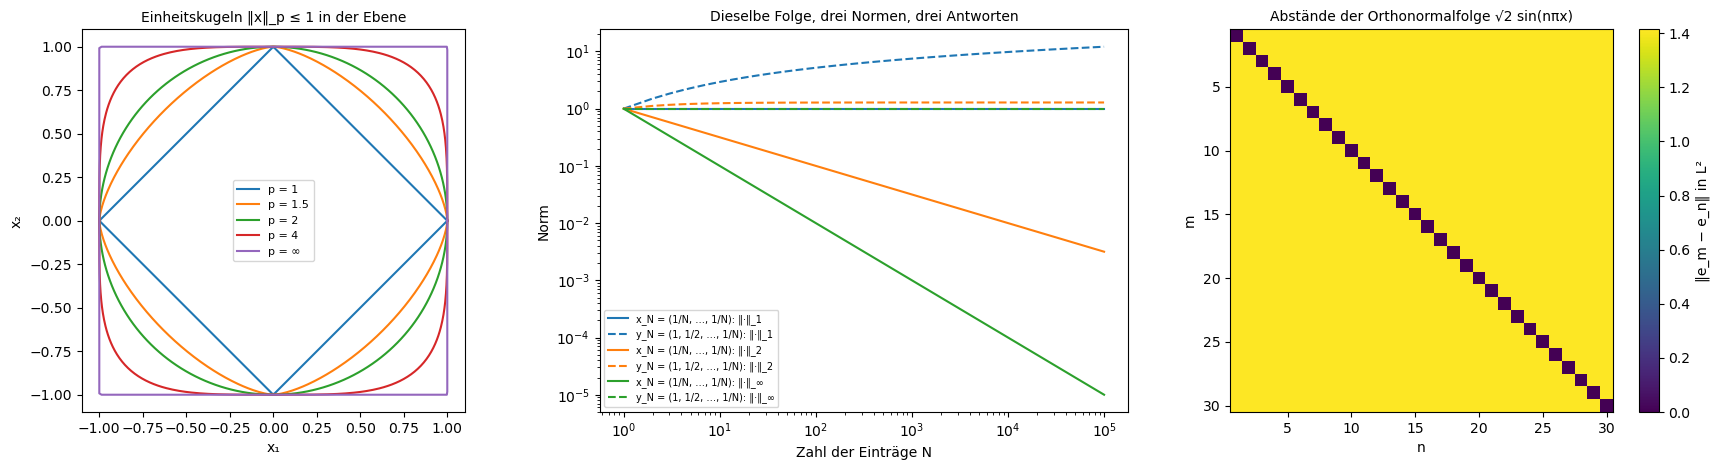

Abstände e_m − e_n (m ≠ n): kleinster 1.414214, größter 1.414214, √2 = 1.414214;  Normen der e_n: 1.000000 bis 1.000000
N =     10: x_N hat ‖·‖₁ = 1.0000, ‖·‖₂ = 0.3162, ‖·‖_∞ = 0.10000;  y_N hat ‖·‖₁ = 2.9290, ‖·‖₂ = 1.2449 (Grenze π/√6 = 1.2825)
N =   1000: x_N hat ‖·‖₁ = 1.0000, ‖·‖₂ = 0.0316, ‖·‖_∞ = 0.00100;  y_N hat ‖·‖₁ = 7.4855, ‖·‖₂ = 1.2822 (Grenze π/√6 = 1.2825)
N = 100000: x_N hat ‖·‖₁ = 1.0000, ‖·‖₂ = 0.0032, ‖·‖_∞ = 0.00001;  y_N hat ‖·‖₁ = 12.0901, ‖·‖₂ = 1.2825 (Grenze π/√6 = 1.2825)


In [2]:
ps = [1, 1.5, 2, 4, np.inf]
phi = np.linspace(0, 2 * np.pi, 600)
Nn = np.unique(np.r_[np.logspace(0, 5, 40).astype(int), 10, 1000, 100000])
pnorm = lambda v, p: np.max(np.abs(v)) if p == np.inf else np.sum(np.abs(v) ** p) ** (1 / p)
seqx = {p: [pnorm(np.full(N, 1 / N), p) for N in Nn] for p in (1, 2, np.inf)}
seqy = {p: [pnorm(1 / np.arange(1, N + 1), p) for N in Nn] for p in (1, 2, np.inf)}
xq, wq = grid01(20000)
E30 = np.array([np.sqrt(2) * np.sin(n * np.pi * xq) for n in range(1, 31)])
gram = (E30 * wq) @ E30.T
dist = np.sqrt(np.maximum(np.diag(gram)[:, None] + np.diag(gram)[None, :] - 2 * gram, 0))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for p, c in zip(ps, ("C0", "C1", "C2", "C3", "C4")):
    d = np.c_[np.cos(phi), np.sin(phi)]
    r = 1 / np.array([pnorm(v, p) for v in d])
    ax.plot(r * d[:, 0], r * d[:, 1], color=c, label=f"p = {'∞' if p == np.inf else p}")
ax.set_aspect("equal")
ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
ax.set_title("Einheitskugeln ‖x‖_p ≤ 1 in der Ebene", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for p, c in zip((1, 2, np.inf), ("C0", "C1", "C2")):
    lab = "∞" if p == np.inf else p
    ax.loglog(Nn, seqx[p], "-", color=c, label=f"x_N = (1/N, …, 1/N): ‖·‖_{lab}")
    ax.loglog(Nn, seqy[p], "--", color=c, label=f"y_N = (1, 1/2, …, 1/N): ‖·‖_{lab}")
ax.set_xlabel("Zahl der Einträge N")
ax.set_ylabel("Norm")
ax.set_title("Dieselbe Folge, drei Normen, drei Antworten", fontsize=10)
ax.legend(fontsize=7)
ax = axes[2]
im = ax.imshow(dist, cmap="viridis", extent=[0.5, 30.5, 30.5, 0.5])
plt.colorbar(im, ax=ax, label="‖e_m − e_n‖ in L²")
ax.set_xlabel("n"); ax.set_ylabel("m")
ax.set_title("Abstände der Orthonormalfolge √2 sin(nπx)", fontsize=10)
plt.tight_layout()
plt.show()

off = dist[~np.eye(30, dtype=bool)]
print(f"Abstände e_m − e_n (m ≠ n): kleinster {off.min():.6f}, größter {off.max():.6f}, √2 = {np.sqrt(2):.6f};  Normen der e_n: {np.diag(gram).min():.6f} bis {np.diag(gram).max():.6f}")
for N in (10, 1000, 100000):
    i = np.argmin(np.abs(Nn - N))
    print(f"N = {Nn[i]:6d}: x_N hat ‖·‖₁ = {seqx[1][i]:.4f}, ‖·‖₂ = {seqx[2][i]:.4f}, ‖·‖_∞ = {seqx[np.inf][i]:.5f};  "
          f"y_N hat ‖·‖₁ = {seqy[1][i]:.4f}, ‖·‖₂ = {seqy[2][i]:.4f} (Grenze π/√6 = {np.pi / np.sqrt(6):.4f})")

* **Links** stehen die Einheitskugeln: die Raute für $p = 1$, der Kreis für $p = 2$, das Quadrat für $p = \infty$. In zwei Dimensionen liegen sie ineinander und unterscheiden sich höchstens um den Faktor $\sqrt2$; in $N$ Dimensionen wächst dieser Faktor auf $\sqrt N$.
* In der **Mitte** (beide Achsen logarithmisch) hat $x_N = (\tfrac1N, \dots, \tfrac1N)$ laut **Ausgabe** immer $\Vert x_N\Vert_1 = 1$, aber $\Vert x_N\Vert_2 = N^{-1/2}$ und $\Vert x_N\Vert_\infty = 1/N$: In $\ell^2$ und $\ell^\infty$ geht die Folge gegen 0, in $\ell^1$ nicht. Für $y_N = (1, \tfrac12, \dots, \tfrac1N)$ wächst $\Vert y_N\Vert_1$ wie $\ln N$ (12.09 bei $N = 10^5$), während $\Vert y_N\Vert_2$ gegen $\pi/\sqrt6 = 1.2825$ geht: Die Folge $(1/k)$ liegt in $\ell^2$, nicht in $\ell^1$.
* **Rechts** sind alle Abstände $\Vert e_m - e_n\Vert$ für $m\neq n$ laut Ausgabe gleich $1.414214 = \sqrt2$, die Diagonale ist 0. Das beantwortet die Vorhersage: Die Folge liegt in der Einheitskugel, aber keine zwei Glieder kommen sich näher als $\sqrt2$, also hat sie keine konvergente Teilfolge. Die Einheitskugel von $L^2$ ist nicht kompakt.
* **Wo es vorkommt:** Die Wahl der Norm ist eine Modellentscheidung: $\ell^1$ bevorzugt dünnbesetzte Lösungen (Lasso, Compressed Sensing), $\ell^2$ glatte (Ridge, Energie), $\ell^\infty$ den schlimmsten Fall (Robustheit, Chebyshev-Approximation, adversariale Beispiele mit beschränkter Pixeländerung). Fehlende Kompaktheit ist der Grund, warum Existenz- und Konvergenzbeweise für Variationsprobleme und Finite Elemente kompakte Einbettungen (Rellich) oder schwache Konvergenz brauchen.

##### *2. Schwache Konvergenz und Vollständigkeit*

Gegen was konvergiert $\sin(nx)$ für $n\to\infty$, und warum braucht man vollständige Räume? Vorher vorhersagen: Wie schnell geht $\int_0^{2\pi}\sin(nx)g(x)\,dx$ gegen 0, wenn $g$ eine Sprungstelle hat, einen Knick oder glatt ist?

Links werden die Skalarprodukte $\langle\sin(nx), g\rangle$ auf $[0, 2\pi]$ für drei Testfunktionen $g$ gegen $n$ aufgetragen (Rechteck auf $[1, 2]$, Dreieck um 2, Gauß-Glocke um 2.5), dazu die konstante Norm $\Vert\sin(nx)\Vert = \sqrt\pi$. In der Mitte steht $\sin^2(20x)$ mit seinem gleitenden Mittel über eine Periode. Rechts konvergieren die stetigen Funktionen $f_n(x) = \tfrac12(1 + \tanh(n(x - \tfrac12)))$ auf $[0, 1]$ gegen eine Sprungfunktion; gemessen wird der Abstand in der $L^2$-Norm und in der Supremumsnorm.

**Hintergrund & Fachbegriffe:**
- **Schwache Konvergenz:** $f_n\rightharpoonup f$, wenn $\langle f_n, g\rangle\to\langle f, g\rangle$ für jedes $g$ (in einem Hilbertraum); **starke** oder **Normkonvergenz:** $\Vert f_n - f\Vert\to0$.
- **Riemann-Lebesgue-Lemma:** Für jedes integrierbare $g$ geht $\int g(x)\sin(nx)\,dx\to0$.
- **Supremumsnorm** $\Vert f\Vert_\infty = \sup\vert f(x)\vert$; mit ihr ist $C[0, 1]$ vollständig, mit der $L^2$-Norm nicht.
- **Vervollständigung:** der kleinste vollständige Raum, der einen gegebenen normierten Raum dicht enthält; $L^2[0, 1]$ ist die Vervollständigung von $C[0, 1]$ bezüglich der $L^2$-Norm.

**Theorie:**

- **Oszillation ohne Normverlust:** $\sin(nx)$ behält die Norm $\sqrt\pi$, aber jedes feste $g$ „sieht“ im Mittel nichts mehr, weil sich positive und negative Halbwellen aufheben. Wie schnell, hängt von der Glattheit von $g$ ab: bei einem Sprung wie $1/n$, bei einem Knick wie $1/n^2$, bei glattem $g$ schneller als jede Potenz (wie beim Abfall von Fourier-Koeffizienten).
- **Nichtlineare Funktionen schwacher Grenzwerte:** $\sin^2(nx) = \tfrac12 - \tfrac12\cos(2nx)\rightharpoonup\tfrac12$, obwohl $\sin(nx)\rightharpoonup0$ und $0^2 = 0$. Das Quadrat des schwachen Grenzwerts ist nicht der schwache Grenzwert des Quadrats. Darauf beruhen Homogenisierung (Materialien mit feiner Mikrostruktur) und die Schwierigkeiten bei nichtlinearen partiellen Differentialgleichungen.
- **Vollständigkeit:** $f_n$ ist eine Cauchy-Folge stetiger Funktionen in der $L^2$-Norm, ihr Grenzwert ist aber unstetig: $(C[0, 1], \Vert\cdot\Vert_2)$ ist nicht vollständig. In der Supremumsnorm ist $f_n$ keine Cauchy-Folge, weil der Abstand zur Sprungfunktion immer $\tfrac12$ bleibt (gleichmäßige Grenzwerte stetiger Funktionen sind stetig). Erst im vollständigen Raum $L^2$ existieren Grenzwerte, Minimierer und Lösungen.

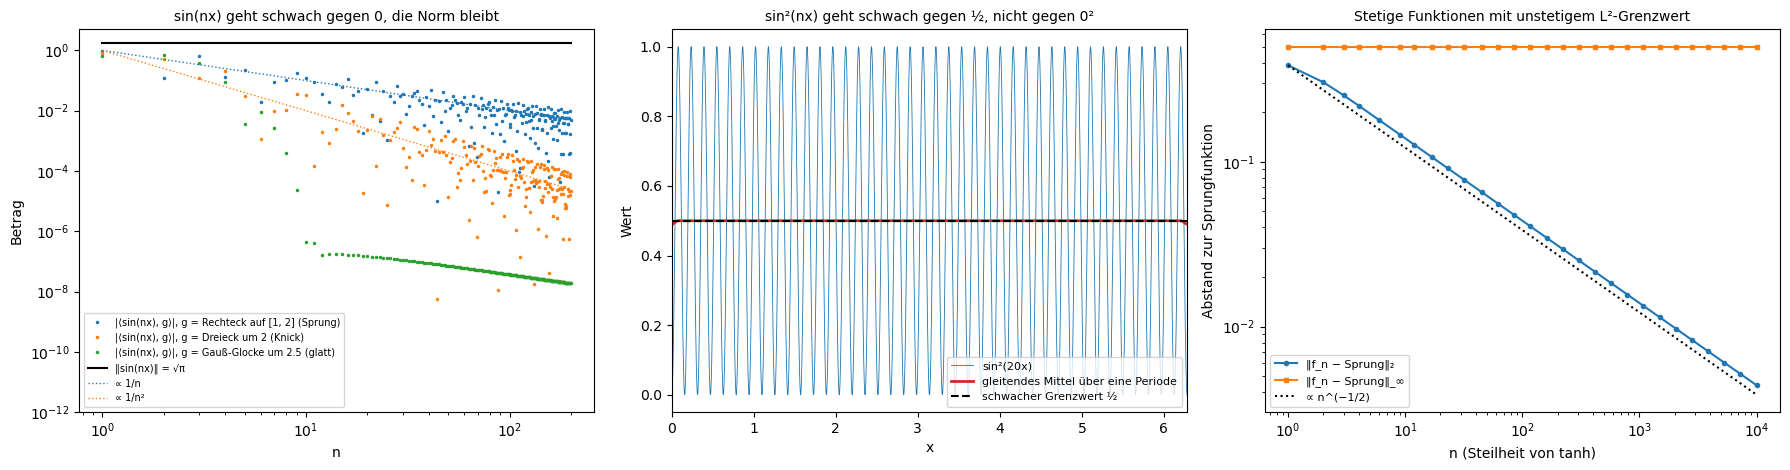

Rechteck auf [1, 2] (Sprung)   |⟨sin(nx), g⟩| bei n = 10, 100, 200: 1.25e-01, 3.76e-03, 5.06e-03
Dreieck um 2 (Knick)           |⟨sin(nx), g⟩| bei n = 10, 100, 200: 3.36e-02, 2.40e-05, 2.18e-05
Gauß-Glocke um 2.5 (glatt)     |⟨sin(nx), g⟩| bei n = 10, 100, 200: 4.36e-07, 3.69e-08, 1.86e-08
‖sin(nx)‖ zwischen 1.772454 und 1.772454 (√π = 1.772454)
⟨sin²(nx), g⟩ für die Gauß-Glocke, n = 1, 5, 20, 100: [0.518841, 0.626655, 0.626657, 0.626657];  ½∫g = 0.626657
L²-Abstand zum Sprung bei n = 10, 100, 1000: ['0.1390', '0.0439', '0.0139'];  Supremumsabstand immer 0.5000
Cauchy in L²: ‖f_n − f_2n‖₂ für n = 10, 100, 1000: ['0.0595', '0.0188', '0.0059']


In [3]:
x2 = np.linspace(0, 2 * np.pi, 200001)
w2 = np.full_like(x2, x2[1] - x2[0]); w2[[0, -1]] /= 2
tests = {"Rechteck auf [1, 2] (Sprung)": ((x2 >= 1) & (x2 <= 2)).astype(float),
         "Dreieck um 2 (Knick)": np.maximum(0, 1 - np.abs(x2 - 2)),
         "Gauß-Glocke um 2.5 (glatt)": np.exp(-2 * (x2 - 2.5) ** 2)}
ns2 = np.arange(1, 201)
inner = {k: np.array([abs(np.sum(w2 * np.sin(n * x2) * g)) for n in ns2]) for k, g in tests.items()}
norms2 = np.array([np.sqrt(np.sum(w2 * np.sin(n * x2) ** 2)) for n in ns2])
gauss = tests["Gauß-Glocke um 2.5 (glatt)"]
sq_inner = {n: np.sum(w2 * np.sin(n * x2) ** 2 * gauss) for n in (1, 5, 20, 100)}
xs01 = np.linspace(0, 1, 100001); ws01 = np.full_like(xs01, xs01[1] - xs01[0]); ws01[[0, -1]] /= 2
step = (xs01 > 0.5).astype(float)
nn = np.unique(np.logspace(0, 4, 30).astype(int))
fseq = lambda n: 0.5 * (1 + np.tanh(n * (xs01 - 0.5)))
d_l2 = np.array([l2(fseq(n) - step, ws01) for n in nn])
d_sup = np.array([np.max(np.abs(fseq(n) - step)) for n in nn])
cauchy = [l2(fseq(n) - fseq(2 * n), ws01) for n in (10, 100, 1000)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for (k, v), c in zip(inner.items(), ("C0", "C1", "C2")):
    ax.loglog(ns2, v + 1e-17, ".", color=c, ms=3, label=f"|⟨sin(nx), g⟩|, g = {k}")
ax.loglog(ns2, norms2, "k-", label="‖sin(nx)‖ = √π")
ax.loglog(ns2, 1.0 / ns2, "C0:", lw=1, label="∝ 1/n")
ax.loglog(ns2, 1.0 / ns2 ** 2, "C1:", lw=1, label="∝ 1/n²")
ax.set_ylim(1e-12, 5)
ax.set_xlabel("n"); ax.set_ylabel("Betrag")
ax.set_title("sin(nx) geht schwach gegen 0, die Norm bleibt", fontsize=10)
ax.legend(fontsize=7)
ax = axes[1]
xx = np.linspace(0, 2 * np.pi, 4000)
win = int(len(xx) * (np.pi / 20) / (2 * np.pi))
ax.plot(xx, np.sin(20 * xx) ** 2, color="C0", lw=0.6, label="sin²(20x)")
yy = np.sin(20 * xx) ** 2
ax.plot(xx, np.convolve(np.r_[yy[-win:], yy, yy[:win]], np.ones(win) / win, mode="same")[win:-win], "C3", lw=2, label="gleitendes Mittel über eine Periode")
ax.axhline(0.5, color="k", ls="--", label="schwacher Grenzwert ½")
ax.set_xlim(0, 2 * np.pi)
ax.set_xlabel("x"); ax.set_ylabel("Wert")
ax.set_title("sin²(nx) geht schwach gegen ½, nicht gegen 0²", fontsize=10)
ax.legend(fontsize=8, loc="lower right")
ax = axes[2]
ax.loglog(nn, d_l2, "o-", ms=3, label="‖f_n − Sprung‖₂")
ax.loglog(nn, d_sup, "s-", ms=3, label="‖f_n − Sprung‖_∞")
ax.loglog(nn, d_l2[0] * np.sqrt(nn[0] / nn), "k:", label="∝ n^(−1/2)")
ax.set_xlabel("n (Steilheit von tanh)")
ax.set_ylabel("Abstand zur Sprungfunktion")
ax.set_title("Stetige Funktionen mit unstetigem L²-Grenzwert", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for k, v in inner.items():
    print(f"{k:30s} |⟨sin(nx), g⟩| bei n = 10, 100, 200: {v[9]:.2e}, {v[99]:.2e}, {v[199]:.2e}")
print(f"‖sin(nx)‖ zwischen {norms2.min():.6f} und {norms2.max():.6f} (√π = {np.sqrt(np.pi):.6f})")
print(f"⟨sin²(nx), g⟩ für die Gauß-Glocke, n = 1, 5, 20, 100: {[round(float(v), 6) for v in sq_inner.values()]};  ½∫g = {0.5 * np.sum(w2 * gauss):.6f}")
print(f"L²-Abstand zum Sprung bei n = 10, 100, 1000: {[f'{l2(fseq(n) - step, ws01):.4f}' for n in (10, 100, 1000)]};  Supremumsabstand immer {d_sup.min():.4f}")
print(f"Cauchy in L²: ‖f_n − f_2n‖₂ für n = 10, 100, 1000: {[f'{c:.4f}' for c in cauchy]}")

* **Links** (beide Achsen logarithmisch) bleibt die Norm $\Vert\sin(nx)\Vert = \sqrt\pi = 1.772454$ für jedes $n$ (laut **Ausgabe** exakt), aber die Skalarprodukte mit den festen Testfunktionen gehen gegen 0. Das beantwortet die Vorhersage: beim Rechteck mit Sprung wie $1/n$ (0.125, $3.8\cdot10^{-3}$ und $5.1\cdot10^{-3}$ bei $n = 10$, 100, 200, schwankend unter der Hüllkurve), beim Dreieck mit Knick wie $1/n^2$ ($2.4\cdot10^{-5}$ bei $n = 100$), bei der Gauß-Glocke für kleine $n$ schneller als jede Potenz; danach bleibt ein Rest um $10^{-8}$, weil die Glocke an den Intervallenden nicht exakt 0 ist.
* In der **Mitte** schwankt $\sin^2(20x)$ zwischen 0 und 1, das gleitende Mittel über eine Periode ist überall $\tfrac12$. Laut Ausgabe ist $\langle\sin^2(nx), g\rangle$ ab $n = 5$ gleich $\tfrac12\int g = 0.626657$: Der schwache Grenzwert von $\sin^2(nx)$ ist $\tfrac12$, nicht das Quadrat des schwachen Grenzwerts 0.
* **Rechts** (beide Achsen logarithmisch) geht der $L^2$-Abstand der stetigen Funktionen $f_n$ zur Sprungfunktion wie $n^{-1/2}$ gegen 0 (0.139, 0.044, 0.014 bei $n = 10$, 100, 1000), und $\Vert f_n - f_{2n}\Vert_2$ wird beliebig klein: eine Cauchy-Folge. Der Supremumsabstand bleibt 0.5. Der Grenzwert liegt in $L^2$, aber nicht in $C[0, 1]$.
* **Wo es vorkommt:** Schwache Konvergenz ist das Werkzeug für Existenzbeweise in der Variationsrechnung und bei partiellen Differentialgleichungen (Minimalfolgen haben schwach konvergente Teilfolgen), sie beschreibt Homogenisierung und effektive Materialeigenschaften von Verbundwerkstoffen und die Konvergenz von Verteilungen in der Statistik (schwache Konvergenz von Maßen, zentraler Grenzwertsatz). Vollständigkeit braucht man überall, wo eine Folge von Näherungen einen Grenzwert haben soll: Fixpunktsätze, Fourier-Reihen in $L^2$, Konvergenz von Optimierungsverfahren.

##### *3. Hahn-Banach: eine Hyperebene trennt Verschränkung ab*

Wie weist man nach, dass ein Quantenzustand verschränkt ist, ohne ihn ganz zu kennen? Vorher vorhersagen: Ab welchem Mischungsanteil $p$ ist der Werner-Zustand $\rho_p = p\,\vert\Psi^-\rangle\langle\Psi^-\vert + (1 - p)\tfrac14$ verschränkt, und erkennt ein einziger Zeuge alle verschränkten Zustände von zwei Qubits?

Die separablen Zustände zweier Qubits bilden eine abgeschlossene konvexe Menge. Nach Hahn-Banach gibt es zu jedem verschränkten Zustand eine Hyperebene, die ihn von dieser Menge trennt: einen hermiteschen Operator $W$ mit $\mathrm{tr}(W\sigma)\geq0$ für alle separablen $\sigma$ und $\mathrm{tr}(W\rho) < 0$. Der Code nimmt den Zeugen $W = \tfrac12 - \vert\Psi^-\rangle\langle\Psi^-\vert$. Links steht ein ebener Schnitt durch die Zustände $\rho = p\,\vert\Psi^-\rangle\langle\Psi^-\vert + q\,\vert\Phi^+\rangle\langle\Phi^+\vert + (1 - p - q)\tfrac14$, eingefärbt nach dem Kriterium der partiellen Transposition, mit den Hyperebenen zweier Zeugen. Rechts steht $\mathrm{tr}(W\sigma)$ für 20 000 zufällige Produktzustände, 20 000 zufällige Mischungen von Produktzuständen und alle verschränkten Zustände unter 20 000 zufälligen Zuständen.

**Hintergrund & Fachbegriffe:**
- **Separabel:** eine Mischung von Produktzuständen $\sum_ip_i\,\rho_i^A\otimes\rho_i^B$; sonst **verschränkt**.
- **Bell-Zustände** $\vert\Psi^-\rangle = (\vert01\rangle - \vert10\rangle)/\sqrt2$, $\vert\Phi^+\rangle = (\vert00\rangle + \vert11\rangle)/\sqrt2$: die maximal verschränkten Zustände zweier Qubits; $\tfrac14$ ist der vollständig gemischte Zustand.
- **Verschränkungszeuge:** ein hermitescher Operator $W$, dessen Erwartungswert auf allen separablen Zuständen $\geq0$ ist und auf manchen verschränkten negativ; man misst nur $\mathrm{tr}(W\rho)$, nicht den ganzen Zustand.
- **Partielle Transposition** (Peres-Horodecki): Transponiert man nur das zweite Qubit, bleibt ein separabler Zustand positiv; für zwei Qubits gilt auch die Umkehrung.
- **Konvexe Menge:** Mit zwei Punkten enthält sie die ganze Strecke dazwischen.

**Theorie:**

- **Trennungssatz:** Ist $C$ abgeschlossen und konvex und $\rho\notin C$, gibt es ein lineares Funktional $\ell$ und eine Zahl $c$ mit $\ell(\sigma)\geq c > \ell(\rho)$ für alle $\sigma\in C$. In endlicher Dimension ist das elementare Geometrie; Hahn-Banach garantiert es in jedem normierten Raum. Für Zustände ist jedes lineare Funktional $\rho\mapsto\mathrm{tr}(W\rho)$ mit hermiteschem $W$, also ist jeder trennende Operator ein Verschränkungszeuge.
- **Der Zeuge** $W = \tfrac12 - \vert\Psi^-\rangle\langle\Psi^-\vert$: Ein Produktzustand $\vert a\rangle\vert b\rangle$ hat mit $\vert\Psi^-\rangle$ höchstens die Überlappung $\tfrac12$, deshalb ist $\mathrm{tr}(W\sigma)\geq0$ für alle separablen $\sigma$. Für den Werner-Zustand ist $\mathrm{tr}(W\rho_p) = \tfrac14 - \tfrac34p$, negativ genau für $p > \tfrac13$; das ist zugleich die genaue Grenze der Verschränkung.
- **Ein Zeuge reicht nicht:** Jeder Zeuge schneidet nur einen Halbraum ab. Um alle verschränkten Zustände zu erkennen, braucht man unendlich viele Zeugen; die separable Menge ist der Schnitt aller dieser Halbräume.

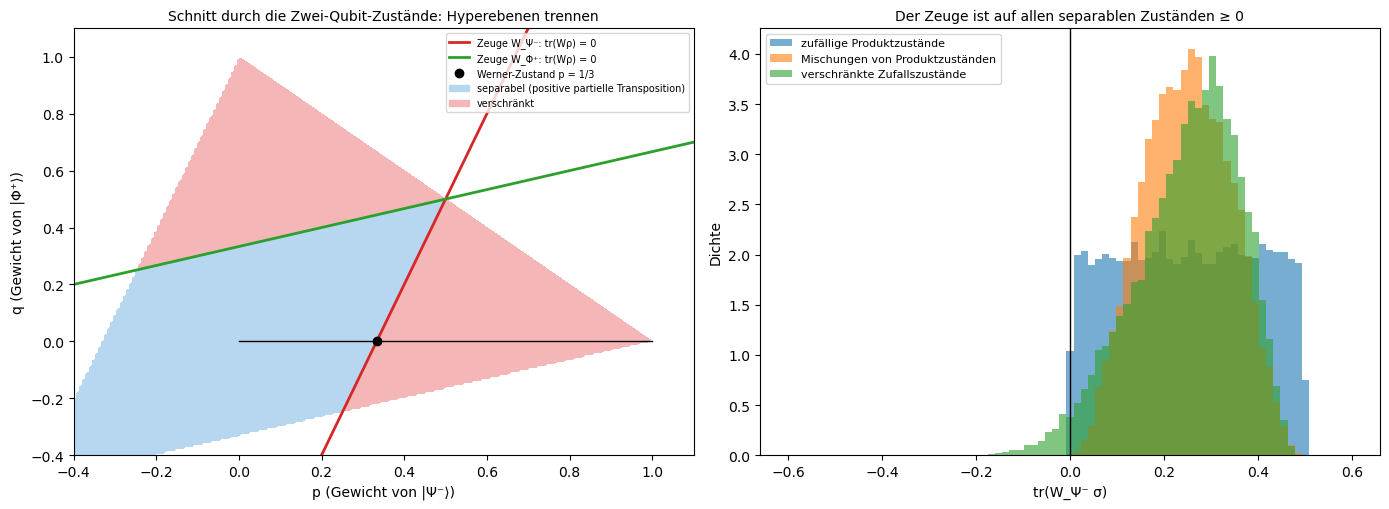

tr(Wσ): kleinster Wert auf 20 000 Produktzuständen 5.90e-06, auf 20 000 Mischungen 0.0120
Werner-Zustand: verschränkt ab p = 0.334 (Theorie 1/3), tr(Wρ_p) = 1/4 − 3p/4 bei p = 0.5: -0.1250
Zufällige Zustände: 0.752 verschränkt; davon erkennt W_Ψ⁻ 0.025, W_Ψ⁻ oder W_Φ⁺ zusammen 0.046


In [4]:
rng = np.random.default_rng(3)
psi_m = np.array([0, 1, -1, 0]) / np.sqrt(2)
phi_p = np.array([1, 0, 0, 1]) / np.sqrt(2)
W_psi = 0.5 * np.eye(4) - np.outer(psi_m, psi_m)
W_phi = 0.5 * np.eye(4) - np.outer(phi_p, phi_p)
def partial_transpose(r):
    return r.reshape(2, 2, 2, 2).transpose(0, 3, 2, 1).reshape(4, 4)
def rand_ket(d):
    v = rng.normal(size=d) + 1j * rng.normal(size=d)
    return v / np.linalg.norm(v)
def rand_product():
    v = np.kron(rand_ket(2), rand_ket(2))
    return np.outer(v, v.conj())
prod = [rand_product() for _ in range(20000)]
mix = [sum(wt * rand_product() for wt in rng.dirichlet(np.ones(4))) for _ in range(20000)]
def rand_state():
    G = rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4))
    r = G @ G.conj().T
    return r / np.trace(r)
states = [rand_state() for _ in range(20000)]
ent = [r for r in states if np.linalg.eigvalsh(partial_transpose(r)).min() < -1e-12]
ev = lambda W, rs: np.array([np.real(np.trace(W @ r)) for r in rs])
w_prod, w_mix, w_ent = ev(W_psi, prod), ev(W_psi, mix), ev(W_psi, ent)
w_ent_both = np.minimum(w_ent, ev(W_phi, ent))
pg = np.linspace(-0.4, 1.1, 201)
P, Q = np.meshgrid(pg, pg)
cls = np.full(P.shape, np.nan)
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        r = P[i, j] * np.outer(psi_m, psi_m) + Q[i, j] * np.outer(phi_p, phi_p) + (1 - P[i, j] - Q[i, j]) * np.eye(4) / 4
        if np.linalg.eigvalsh(r).min() < -1e-12:
            continue
        cls[i, j] = 0 if np.linalg.eigvalsh(partial_transpose(r)).min() >= -1e-12 else 1
werner_p = np.linspace(0, 1, 1001)
werner_ent = werner_p[[np.linalg.eigvalsh(partial_transpose(p_ * np.outer(psi_m, psi_m) + (1 - p_) * np.eye(4) / 4)).min() < -1e-12 for p_ in werner_p]].min()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
ax.contourf(P, Q, cls, levels=[-0.5, 0.5, 1.5], colors=["#b7d7f0", "#f4b6b6"])
ax.plot(pg, 3 * pg - 1, "C3-", lw=2, label="Zeuge W_Ψ⁻: tr(Wρ) = 0")
ax.plot(3 * pg - 1, pg, "C2-", lw=2, label="Zeuge W_Φ⁺: tr(Wρ) = 0")
ax.plot(werner_p, 0 * werner_p, "k-", lw=1)
ax.plot(1 / 3, 0, "ko", ms=6, label="Werner-Zustand p = 1/3")
ax.fill([], [], color="#b7d7f0", label="separabel (positive partielle Transposition)")
ax.fill([], [], color="#f4b6b6", label="verschränkt")
ax.set_xlim(-0.4, 1.1); ax.set_ylim(-0.4, 1.1)
ax.set_xlabel("p (Gewicht von |Ψ⁻⟩)"); ax.set_ylabel("q (Gewicht von |Φ⁺⟩)")
ax.set_title("Schnitt durch die Zwei-Qubit-Zustände: Hyperebenen trennen", fontsize=10)
ax.legend(fontsize=7, loc="upper right")
ax = axes[1]
bins = np.linspace(-0.6, 0.6, 80)
ax.hist(w_prod, bins=bins, alpha=0.6, density=True, label="zufällige Produktzustände")
ax.hist(w_mix, bins=bins, alpha=0.6, density=True, label="Mischungen von Produktzuständen")
ax.hist(w_ent, bins=bins, alpha=0.6, density=True, label="verschränkte Zufallszustände")
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("tr(W_Ψ⁻ σ)")
ax.set_ylabel("Dichte")
ax.set_title("Der Zeuge ist auf allen separablen Zuständen ≥ 0", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"tr(Wσ): kleinster Wert auf 20 000 Produktzuständen {w_prod.min():.2e}, auf 20 000 Mischungen {w_mix.min():.4f}")
print(f"Werner-Zustand: verschränkt ab p = {werner_ent:.3f} (Theorie 1/3), tr(Wρ_p) = 1/4 − 3p/4 bei p = 0.5: {np.real(np.trace(W_psi @ (0.5 * np.outer(psi_m, psi_m) + 0.5 * np.eye(4) / 4))):.4f}")
print(f"Zufällige Zustände: {len(ent) / len(states):.3f} verschränkt; davon erkennt W_Ψ⁻ {np.mean(w_ent < 0):.3f}, W_Ψ⁻ oder W_Φ⁺ zusammen {np.mean(w_ent_both < 0):.3f}")

* **Links** steht der Schnitt durch die Zustände $\rho = p\,\vert\Psi^-\rangle\langle\Psi^-\vert + q\,\vert\Phi^+\rangle\langle\Phi^+\vert + (1 - p - q)\tfrac14$: farbig nur die physikalischen (positiven) Zustände, blau die separablen, rot die verschränkten. Die blaue Menge ist konvex, und jede der beiden roten Ecken wird von einer Hyperebene abgeschnitten: die rote Gerade $\mathrm{tr}(W_{\Psi^-}\rho) = 0$ und die grüne $\mathrm{tr}(W_{\Phi^+}\rho) = 0$. In diesem Schnitt sind die beiden Zeugen genau die Grenzen. Auf der Werner-Linie ($q = 0$, schwarz) beginnt die Verschränkung laut **Ausgabe** bei $p = 0.334$, auf dem Gitter von 0.0075 die Theorie $\tfrac13$. Das beantwortet den ersten Teil der Vorhersage.
* **Rechts** liegt $\mathrm{tr}(W\sigma)$ für alle 20 000 Produktzustände und alle 20 000 Mischungen über 0 (kleinster Wert $5.9\cdot10^{-6}$ bzw. 0.012): Die Hyperebene berührt die separable Menge nur. Von den zufälligen Zuständen sind 75.2 % verschränkt, aber $W_{\Psi^-}$ erkennt nur 2.5 % davon, zusammen mit $W_{\Phi^+}$ 4.6 %. Das beantwortet den zweiten Teil: Ein Zeuge schneidet nur einen Halbraum ab; für jeden verschränkten Zustand garantiert Hahn-Banach einen eigenen.
* **Wo es vorkommt:** Verschränkungszeugen sind das Standardverfahren, um Verschränkung im Labor nachzuweisen (Photonen, Ionenfallen, supraleitende Qubits), weil man nur einen Erwartungswert messen muss statt den ganzen Zustand. Dieselbe Trennungsidee steckt in der Dualitätstheorie der konvexen Optimierung (jedes nicht erfüllbare System hat ein Zertifikat, das Farkas-Lemma), in Support-Vektor-Maschinen (die trennende Hyperebene mit größtem Abstand) und in Bell-Ungleichungen, die lokale Theorien durch eine Hyperebene von der Quantenmechanik trennen.

##### *4. Riesz-Darstellung, Sobolev-Raum und Kern-Hilberträume*

Ist der Wert einer Funktion an einem Punkt eine „stetige“ Größe, und was hat das mit Kernmethoden des maschinellen Lernens zu tun? Vorher vorhersagen: Kann man eine Funktion mit beliebig kleiner $L^2$-Norm finden, die bei $x_0 = 0.3$ den Wert 1 hat?

Links werden Gauß-Spitzen der Breite $\sigma$ um $x_0 = 0.3$ gemessen: das Verhältnis $\vert g(x_0)\vert/\Vert g\Vert$ in der $L^2$-Norm und in der Sobolev-Norm $\Vert g\Vert_{H^1}^2 = \int(g^2 + g'^2)$. In der Mitte stehen die Riesz-Vektoren der Punktauswertung in $H^1(0, 1)$, die Funktionen $k(x_0, \cdot)$, und die Ausgabe prüft $\langle k(x_0, \cdot), f\rangle_{H^1} = f(x_0)$ durch Quadratur. Rechts wird mit dem Gauß-Kern eine Kern-Ridge-Regression an 20 verrauschten Punkten von $\sin(2\pi x)$ gerechnet, und die Ausgabe prüft das Representer-Theorem: Die Minimierung über einen viel größeren Funktionenraum gibt dieselbe Funktion.

**Hintergrund & Fachbegriffe:**
- **Lineares Funktional:** eine lineare Abbildung in die Zahlen, etwa $f\mapsto f(x_0)$ (**Punktauswertung**) oder $f\mapsto\int fw$; **stetig** heißt beschränkt: $\vert\ell(f)\vert\leq C\Vert f\Vert$.
- **Sobolev-Raum** $H^1(0, 1)$: Funktionen mit $f, f'\in L^2$ und dem Skalarprodukt $\langle f, g\rangle_{H^1} = \int(fg + f'g')$.
- **Reproduzierender Kern:** $k(x, y)$ mit $f(x) = \langle k(x, \cdot), f\rangle$ für alle $f$ des Raums; **Kern-Hilbertraum (RKHS)** ist ein Hilbertraum mit einem solchen Kern.
- **Gauß-Kern** $k(x, y) = e^{-(x - y)^2/(2\ell^2)}$, der Standardkern von Support-Vektor-Maschinen und Gauß-Prozessen.
- **Kern-Ridge-Regression:** minimiert $\sum_i(f(x_i) - y_i)^2 + \lambda\Vert f\Vert_{\mathcal H}^2$ über alle $f$ im Kern-Hilbertraum.

**Theorie:**

- **Punktauswertung in $L^2$ ist unstetig:** Eine schmale Spitze hat den Wert 1, aber $L^2$-Norm $\propto\sqrt\sigma\to0$. Es gibt also keinen Riesz-Vektor, und $L^2$-„Funktionen“ haben gar keine Werte an Punkten, nur Klassen fast überall gleicher Funktionen.
- **In $H^1$ ist sie stetig** (eine Sobolev-Einbettung in einer Dimension): $\vert f(x_0)\vert\leq\sqrt{k(x_0, x_0)}\,\Vert f\Vert_{H^1}$. Der Riesz-Vektor ist die Green-Funktion von $-u'' + u$ mit Neumann-Rand, $k(x, y) = \cosh(\min(x, y))\cosh(1 - \max(x, y))/\sinh1$.
- **Representer-Theorem:** Hängt das Ziel nur von $f(x_1), \dots, f(x_n)$ und von $\Vert f\Vert_{\mathcal H}$ ab, liegt der Minimierer im Erzeugnis von $k(x_1, \cdot), \dots, k(x_n, \cdot)$. Der Grund ist der Projektionssatz: Ein Anteil senkrecht zu diesen Funktionen ändert keinen Funktionswert (Riesz), vergrößert aber die Norm. Bei der Kern-Ridge-Regression ist $f = \sum_i\alpha_ik(x_i, \cdot)$ mit $(K + \lambda)\alpha = y$: ein Problem über einem unendlichdimensionalen Raum wird ein $n\times n$-Gleichungssystem.

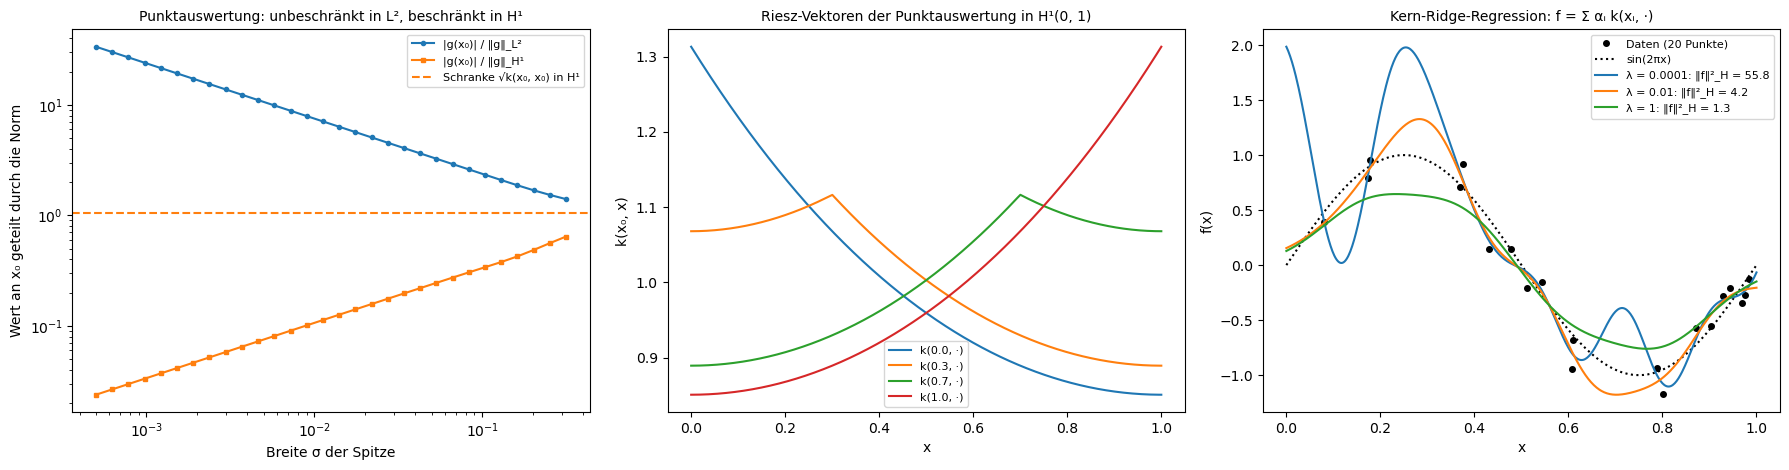

Reproduzierende Eigenschaft in H¹: x₀ = 0.0: ⟨k, f⟩ = 0.00000000, f(x₀) = 0.00000000, x₀ = 0.3: ⟨k, f⟩ = 0.87332691, f(x₀) = 0.87332691, x₀ = 0.7: ⟨k, f⟩ = 1.35320937, f(x₀) = 1.35320937, x₀ = 1.0: ⟨k, f⟩ = 1.14112001, f(x₀) = 1.14112001
Spitze mit σ = 5.0e-04: Verhältnis in L² 33.6, in H¹ 0.0238;  Schranke √k(x₀,x₀) = 1.0566
Representer-Theorem (λ = 0.01): Minimierung über 221 Kernfunktionen weicht von der Lösung mit 20 um höchstens 3.1e-09 ab
Fehler gegen sin(2πx) auf [0, 1]: λ = 0.0001: 0.509, λ = 0.01: 0.158, λ = 1: 0.195


In [5]:
x4 = np.linspace(0, 1, 40001)
w4 = np.full_like(x4, x4[1] - x4[0]); w4[[0, -1]] /= 2
kH1 = lambda x0: np.cosh(np.minimum(x4, x0)) * np.cosh(1 - np.maximum(x4, x0)) / np.sinh(1)
x0 = 0.3
sig = np.logspace(-3.3, -0.5, 30)
r_l2, r_h1 = [], []
for s in sig:
    g = np.exp(-(x4 - x0) ** 2 / (2 * s * s)); gp = -(x4 - x0) / s ** 2 * g
    r_l2.append(1 / l2(g, w4)); r_h1.append(1 / np.sqrt(np.sum(w4 * (g ** 2 + gp ** 2))))
f4 = np.sin(3 * x4) + x4 ** 2; f4p = 3 * np.cos(3 * x4) + 2 * x4
repro = {y0: (np.sum(w4 * (f4 * kH1(y0) + f4p * np.gradient(kH1(y0), x4))), np.sin(3 * y0) + y0 ** 2) for y0 in (0.0, 0.3, 0.7, 1.0)}
rng = np.random.default_rng(4)
xd = np.sort(rng.uniform(0, 1, 20)); yd = np.sin(2 * np.pi * xd) + 0.15 * rng.normal(size=20)
ell = 0.1
kg = lambda a, b: np.exp(-(a[:, None] - b[None, :]) ** 2 / (2 * ell * ell))
xt = np.linspace(0, 1, 501)
krr = {}
for lam in (1e-4, 1e-2, 1.0):
    alpha = np.linalg.solve(kg(xd, xd) + lam * np.eye(20), yd)
    krr[lam] = (kg(xt, xd) @ alpha, alpha, float(alpha @ kg(xd, xd) @ alpha))
z = np.r_[np.linspace(0, 1, 201), xd]                       # viel größerer Ansatzraum: 221 Kernfunktionen
lam = 1e-2
Kzz, Kxz = kg(z, z), kg(xd, z)
ew, ev_ = np.linalg.eigh(Kzz)
keep = ew > 1e-10 * ew.max()
B = ev_[:, keep] / np.sqrt(ew[keep])                        # Koordinaten, in denen die RKHS-Norm die euklidische ist
cb = np.linalg.solve((Kxz @ B).T @ (Kxz @ B) + lam * np.eye(keep.sum()), (Kxz @ B).T @ yd)
f_big = kg(xt, z) @ (B @ cb)
rep_err = np.abs(f_big - krr[lam][0]).max()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.loglog(sig, r_l2, "o-", ms=3, label="|g(x₀)| / ‖g‖_L²")
ax.loglog(sig, r_h1, "s-", ms=3, label="|g(x₀)| / ‖g‖_H¹")
ax.axhline(np.sqrt(kH1(x0)[np.argmin(np.abs(x4 - x0))]), color="C1", ls="--", label="Schranke √k(x₀, x₀) in H¹")
ax.set_xlabel("Breite σ der Spitze")
ax.set_ylabel("Wert an x₀ geteilt durch die Norm")
ax.set_title("Punktauswertung: unbeschränkt in L², beschränkt in H¹", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for y0, c in zip((0.0, 0.3, 0.7, 1.0), ("C0", "C1", "C2", "C3")):
    ax.plot(x4, kH1(y0), color=c, label=f"k({y0}, ·)")
ax.set_xlabel("x"); ax.set_ylabel("k(x₀, x)")
ax.set_title("Riesz-Vektoren der Punktauswertung in H¹(0, 1)", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(xd, yd, "ko", ms=4, label="Daten (20 Punkte)")
ax.plot(xt, np.sin(2 * np.pi * xt), "k:", label="sin(2πx)")
for (lam_, (f_, a_, nrm)), c in zip(krr.items(), ("C0", "C1", "C2")):
    ax.plot(xt, f_, color=c, label=f"λ = {lam_:g}: ‖f‖²_H = {nrm:.1f}")
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title("Kern-Ridge-Regression: f = Σ αᵢ k(xᵢ, ·)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Reproduzierende Eigenschaft in H¹: " + ", ".join(f"x₀ = {y0}: ⟨k, f⟩ = {a:.8f}, f(x₀) = {b:.8f}" for y0, (a, b) in repro.items()))
print(f"Spitze mit σ = {sig[0]:.1e}: Verhältnis in L² {r_l2[0]:.1f}, in H¹ {r_h1[0]:.4f};  Schranke √k(x₀,x₀) = {np.sqrt(np.cosh(x0) * np.cosh(1 - x0) / np.sinh(1)):.4f}")
print(f"Representer-Theorem (λ = 0.01): Minimierung über 221 Kernfunktionen weicht von der Lösung mit 20 um höchstens {rep_err:.1e} ab")
print("Fehler gegen sin(2πx) auf [0, 1]: " + ", ".join(f"λ = {k_:g}: {np.sqrt(np.mean((v[0] - np.sin(2 * np.pi * xt)) ** 2)):.3f}" for k_, v in krr.items()))

* **Links** (beide Achsen logarithmisch) wächst das Verhältnis $\vert g(x_0)\vert/\Vert g\Vert_{L^2}$ für schmaler werdende Spitzen wie $\sigma^{-1/2}$, laut **Ausgabe** auf 33.6 bei $\sigma = 5\cdot10^{-4}$: Die Punktauswertung ist in $L^2$ unbeschränkt. Das beantwortet die Vorhersage: Ja, beliebig kleine $L^2$-Norm bei festem Wert 1 ist möglich. In der $H^1$-Norm bleibt das Verhältnis unter der Schranke $\sqrt{k(x_0, x_0)} = 1.0566$ und fällt sogar (0.024), weil schmale Spitzen große Ableitungen haben.
* In der **Mitte** stehen die Riesz-Vektoren $k(x_0, \cdot)$: Funktionen aus Exponentialstücken mit einem Knick bei $x_0$. Laut Ausgabe ist $\langle k(x_0, \cdot), f\rangle_{H^1} = f(x_0)$ für $f(x) = \sin3x + x^2$ an allen vier Stellen auf acht Nachkommastellen: Die Punktauswertung ist in $H^1$ ein Skalarprodukt.
* **Rechts** steht die Kern-Ridge-Regression: Mit $\lambda = 10^{-4}$ läuft die Kurve durch fast alle Punkte und schwingt dazwischen stark (Fehler gegen $\sin2\pi x$ laut Ausgabe 0.509, RKHS-Norm 55.8), mit $\lambda = 1$ ist sie zu flach (0.195), $\lambda = 0.01$ ist am besten (0.158). Die Minimierung über 221 Kernfunktionen statt der 20 an den Datenpunkten ergibt laut Ausgabe dieselbe Funktion bis auf $3\cdot10^{-9}$: das Representer-Theorem.
* **Wo es vorkommt:** Kernmethoden (Support-Vektor-Maschinen, Kern-Ridge-Regression, Kern-PCA), Gauß-Prozess-Regression in der Bayes'schen Optimierung (der Mittelwert der Vorhersage ist genau die Kern-Ridge-Lösung), Splines (kubische Glättungssplines sind Kern-Ridge-Regression in einem Sobolev-Raum), die Theorie unendlich breiter neuronaler Netze (Neural Tangent Kernel), Maximum Mean Discrepancy für Zwei-Stichproben-Tests und Einbettungen von Wahrscheinlichkeitsverteilungen in Kern-Hilberträume.

##### *5. Beschränkt oder unbeschränkt: Ableitung, Green-Operator, Neumann-Reihe, Fredholm*

Warum ist die Ableitung ein schwieriger Operator und ihre Umkehrung ein gutartiger, und wann lässt sich $(1 - \lambda K)u = f$ lösen? Vorher vorhersagen: Für $K$, die Umkehrung von $-\frac{d^2}{dx^2}$ mit $u(0) = u(1) = 0$, und $f = 1$: Bei welchen $\lambda$ wird die Lösung unendlich groß, und konvergiert die Neumann-Reihe für $\lambda = 12$?

Links werden die Normen der diskretisierten Ableitung $D_n$ (Vorwärtsdifferenz) und des Green-Operators $K_n$ (Nyström-Matrix des Kerns $\min(x, y)(1 - \max(x, y))$) gegen die Zahl $n$ der Gitterpunkte aufgetragen. In der Mitte wird $(1 - \lambda K)u = 1$ mit der Neumann-Reihe $u = \sum_j\lambda^jK^j1$ gelöst, für $\lambda = 5$, 9 und 12, verglichen mit der direkten Lösung. Rechts steht die Norm der exakten Lösung gegen $\lambda$ von 0 bis 120.

**Hintergrund & Fachbegriffe:**
- **Operatornorm** $\Vert A\Vert = \sup_{\Vert f\Vert = 1}\Vert Af\Vert$; **beschränkt** heißt $\Vert A\Vert < \infty$.
- **Green-Funktion:** der Kern $G(x, y)$ der Umkehrung eines Differentialoperators mit Randbedingungen; für $-u'' = f$, $u(0) = u(1) = 0$ ist $G(x, y) = \min(x, y)(1 - \max(x, y))$.
- **Fredholm-Integralgleichung zweiter Art:** $u - \lambda Ku = f$ mit einem Integraloperator $K$.
- **Neumann-Reihe:** $(1 - \lambda K)^{-1} = \sum_{j\geq0}\lambda^jK^j$, die geometrische Reihe für Operatoren.
- **Charakteristischer Wert:** ein $\lambda$, für das $u = \lambda Ku$ eine Lösung $u\neq0$ hat, also $1/\lambda$ ein Eigenwert von $K$ ist.

**Theorie:**

- **Ableitung unbeschränkt:** $\frac{d}{dx}\sin(n\pi x) = n\pi\cos(n\pi x)$; die Norm wächst mit $n$ über alle Grenzen. Auf einem Gitter der Weite $h = 1/n$ ist die größte darstellbare Frequenz $\propto n$, deshalb wächst $\Vert D_n\Vert\approx2n$. Darum sind Differentialgleichungen numerisch steif und ihre Diskretisierungen schlecht konditioniert.
- **Umkehrung kompakt:** $K$ hat die Eigenfunktionen $\sqrt2\sin(k\pi x)$ und die Eigenwerte $1/(k\pi)^2$, also $\Vert K\Vert = 1/\pi^2\approx0.101$. Integration glättet; deshalb formuliert man Randwertprobleme oft als Integralgleichungen.
- **Neumann-Reihe:** Sie konvergiert, wenn der Spektralradius von $\lambda K$ kleiner als 1 ist, hier für $\vert\lambda\vert < \pi^2\approx9.87$. Für $\lambda = 12$ wachsen die Glieder wie $(12/\pi^2)^j$, obwohl die Gleichung eine eindeutige Lösung hat.
- **Fredholm-Alternative:** Für kompaktes $K$ ist $(1 - \lambda K)u = f$ entweder für jedes $f$ eindeutig lösbar, oder $\lambda$ ist ein charakteristischer Wert, und dann ist die Gleichung genau für die $f$ lösbar, die senkrecht auf den Eigenfunktionen (des adjungierten Problems) stehen. Die exakte Lösung für $f = 1$ ist $u(x) = \cos(\sqrt\lambda(x - \tfrac12))/\cos(\sqrt\lambda/2)$; sie wird unendlich bei $\lambda = ((2m + 1)\pi)^2$. Bei $\lambda = (2\pi)^2$ passiert nichts, weil $f = 1$ senkrecht auf $\sin(2\pi x)$ steht.

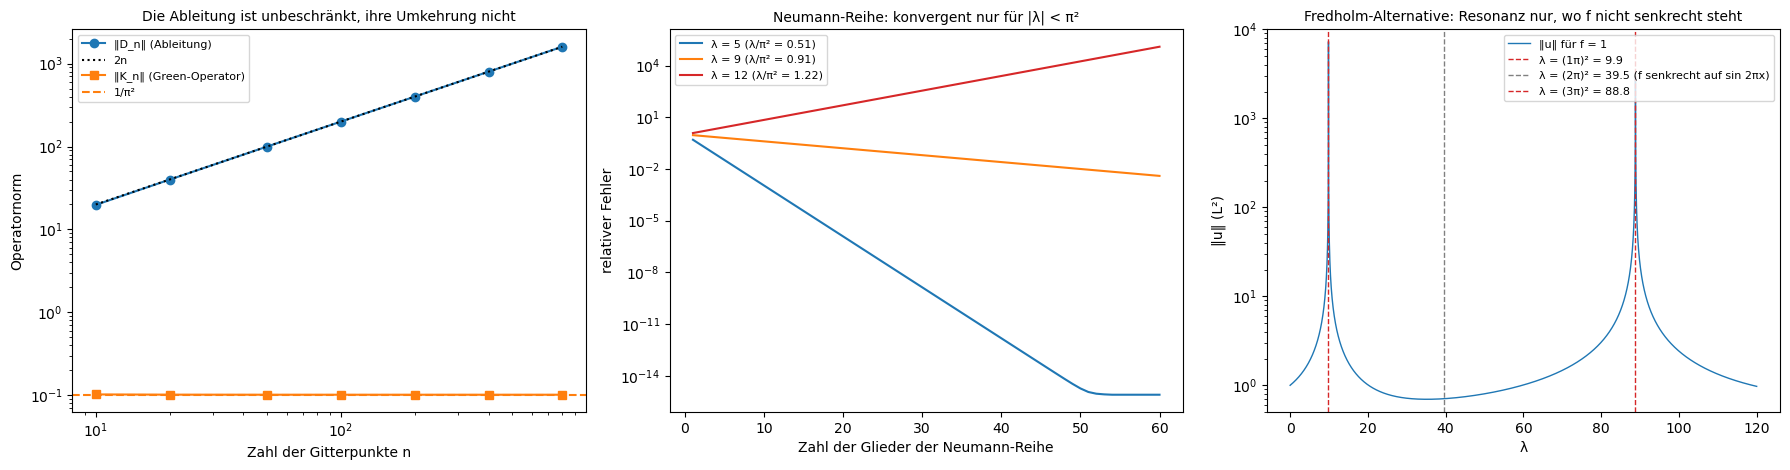

‖D_n‖ für n = [10, 20, 50, 100, 200, 400, 800]: [19.8, 39.9, 100.0, 200.0, 400.0, 800.0, 1600.0];  ‖K_n‖: [0.10216, 0.10153, 0.10135, 0.10133, 0.10132, 0.10132, 0.10132]  (1/π² = 0.10132)
Neumann-Reihe nach 60 Gliedern: λ = 5: 7.9e-16, λ = 9: 3.9e-03, λ = 12: 1.2e+05
Nyström-Lösung gegen exakte Formel bei λ = [20.0, 50.0, 100.0]: Abweichung ['9.9e-06', '5.2e-05', '9.3e-04']
Überlappung ⟨1, √2 sin(kπx)⟩ für k = 1 … 4: [0.900319, 0.0, 0.300112, 0.0]  (Formel 2√2/(kπ) für ungerade k)


In [6]:
G = lambda x, y: np.minimum(x, y) * (1 - np.maximum(x, y))
ns5 = np.array([10, 20, 50, 100, 200, 400, 800])
normD, normK = [], []
for n in ns5:
    h = 1 / n
    D = (np.eye(n, k=1) - np.eye(n)) / h
    normD.append(opnorm(D))
    normK.append(opnorm(integral_operator(G, n)[0]))
K5, x5, w5 = integral_operator(G, 400)
f5 = np.ones(400)
neumann = {}
for lam in (5.0, 9.0, 12.0):
    u_direct = np.linalg.solve(np.eye(400) - lam * K5, f5)
    term, u, errs = f5.copy(), np.zeros(400), []
    for j in range(60):
        u = u + term
        term = lam * K5 @ term
        errs.append(l2(u - u_direct, w5) / l2(u_direct, w5))
    neumann[lam] = np.array(errs)
lams = np.linspace(0.01, 120, 6000)
xx5 = np.linspace(0, 1, 2001); ww5 = np.full_like(xx5, xx5[1] - xx5[0]); ww5[[0, -1]] /= 2
unorm = np.array([l2(np.cos(np.sqrt(l) * (xx5 - 0.5)) / np.cos(np.sqrt(l) / 2), ww5) for l in lams])
check_l = [20.0, 50.0, 100.0]
check = [l2(np.linalg.solve(np.eye(400) - l * K5, f5) - np.cos(np.sqrt(l) * (x5 - 0.5)) / np.cos(np.sqrt(l) / 2), w5) for l in check_l]
overlap = [abs(np.sum(w5 * np.sqrt(2) * np.sin(k * np.pi * x5))) for k in (1, 2, 3, 4)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.loglog(ns5, normD, "o-", label="‖D_n‖ (Ableitung)")
ax.loglog(ns5, 2 * ns5, "k:", label="2n")
ax.loglog(ns5, normK, "s-", label="‖K_n‖ (Green-Operator)")
ax.axhline(1 / np.pi ** 2, color="C1", ls="--", label="1/π²")
ax.set_xlabel("Zahl der Gitterpunkte n")
ax.set_ylabel("Operatornorm")
ax.set_title("Die Ableitung ist unbeschränkt, ihre Umkehrung nicht", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for lam, c in zip(neumann, ("C0", "C1", "C3")):
    ax.semilogy(np.arange(1, 61), neumann[lam], color=c, label=f"λ = {lam:g} (λ/π² = {lam / np.pi ** 2:.2f})")
ax.set_xlabel("Zahl der Glieder der Neumann-Reihe")
ax.set_ylabel("relativer Fehler")
ax.set_title("Neumann-Reihe: konvergent nur für |λ| < π²", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.semilogy(lams, unorm, "C0-", lw=1, label="‖u‖ für f = 1")
for k, c in ((1, "C3"), (2, "grey"), (3, "C3")):
    ax.axvline((k * np.pi) ** 2, color=c, ls="--", lw=1, label=f"λ = ({k}π)² = {(k * np.pi) ** 2:.1f}" + (" (f senkrecht auf sin 2πx)" if k == 2 else ""))
ax.set_ylim(0.5, 1e4)
ax.set_xlabel("λ"); ax.set_ylabel("‖u‖ (L²)")
ax.set_title("Fredholm-Alternative: Resonanz nur, wo f nicht senkrecht steht", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"‖D_n‖ für n = {ns5.tolist()}: {[round(v, 1) for v in normD]};  ‖K_n‖: {[round(v, 5) for v in normK]}  (1/π² = {1 / np.pi ** 2:.5f})")
print("Neumann-Reihe nach 60 Gliedern: " + ", ".join(f"λ = {k:g}: {v[-1]:.1e}" for k, v in neumann.items()))
print(f"Nyström-Lösung gegen exakte Formel bei λ = {check_l}: Abweichung {[f'{c:.1e}' for c in check]}")
print(f"Überlappung ⟨1, √2 sin(kπx)⟩ für k = 1 … 4: {[round(o, 6) for o in overlap]}  (Formel 2√2/(kπ) für ungerade k)")

* **Links** (beide Achsen logarithmisch) wächst $\Vert D_n\Vert$ laut **Ausgabe** genau wie $2n$ (1600 bei $n = 800$), während $\Vert K_n\Vert$ gegen $1/\pi^2 = 0.10132$ konvergiert. Die Ableitung hat keine endliche Norm, ihre Umkehrung schon.
* In der **Mitte** konvergiert die Neumann-Reihe für $\lambda = 5$ schnell (Fehler $8\cdot10^{-16}$ nach 60 Gliedern), für $\lambda = 9$ langsam ($3.9\cdot10^{-3}$, weil $9/\pi^2 = 0.91$ nahe 1 ist) und für $\lambda = 12$ gar nicht: Der Fehler wächst auf $1.2\cdot10^5$, obwohl die Gleichung eine eindeutige Lösung hat, die die direkte Rechnung findet. Das beantwortet den zweiten Teil der Vorhersage.
* **Rechts** wird die Lösung nur bei $\lambda = \pi^2 = 9.9$ und $\lambda = 9\pi^2 = 88.8$ unendlich groß, bei $4\pi^2 = 39.5$ passiert nichts. Laut Ausgabe ist die Überlappung $\langle1, \sqrt2\sin(k\pi x)\rangle$ für gerade $k$ genau 0 und für $k = 1$, 3 gleich 0.900 und 0.300 ($2\sqrt2/(k\pi)$): die Fredholm-Alternative. Das beantwortet den ersten Teil. Die Nyström-Lösung stimmt mit der exakten Formel auf $10^{-5}$ bis $10^{-3}$ überein.
* **Wo es vorkommt:** Integralgleichungen statt Differentialgleichungen sind die Grundlage der Randelementmethode (Akustik, Elektrostatik, Antennen), der Strahlungstransportrechnung und der Neumann-Reihe der Streutheorie (Born-Näherung); die Fredholm-Alternative erklärt Resonanzen in angetriebenen Systemen. Unbeschränkte Ableitungen machen Differentialgleichungen steif und erzwingen kleine Zeitschritte bei expliziten Verfahren (CFL-Bedingung).

##### *6. Kompakte Operatoren: Mercer und Karhunen-Loève*

Wie sehen die Eigenwerte eines kompakten Operators aus, und wie zerlegt man einen Zufallsprozess in unabhängige Bausteine? Vorher vorhersagen: Welcher Anteil der Gesamtvarianz der Brownschen Bewegung auf $[0, 1]$ steckt im ersten Glied ihrer Karhunen-Loève-Zerlegung?

Für drei Kovarianzkerne auf $[0, 1]$ berechnet der Code die Eigenwerte des Integraloperators mit einer Nyström-Matrix aus 1000 Punkten: $\min(s, t)$ (Brownsche Bewegung), $e^{-\vert s - t\vert/0.2}$ (Ornstein-Uhlenbeck) und $e^{-(s - t)^2/(2\cdot0.1^2)}$ (Gauß). Links stehen die Eigenwerte gegen ihre Nummer, in der Mitte die ersten vier Eigenfunktionen der Brownschen Bewegung mit der exakten Formel, rechts Pfade der Brownschen Bewegung aus 5, 20 und 200 Gliedern der Zerlegung mit denselben Zufallszahlen.

**Hintergrund & Fachbegriffe:**
- **Kompakter Operator, Hilbert-Schmidt, Spurklasse:** siehe Theorie, Abschnitt 4.
- **Kovarianzkern** $k(s, t) = \mathrm{Cov}(X_s, X_t)$ eines Zufallsprozesses; der zugehörige Integraloperator heißt **Kovarianzoperator**.
- **Satz von Mercer:** Ein stetiger, symmetrischer, positiv semidefiniter Kern hat die Entwicklung $k(s, t) = \sum_k\lambda_ke_k(s)e_k(t)$ in die Eigenfunktionen seines Integraloperators.
- **Karhunen-Loève-Zerlegung:** $X_t = \sum_k\sqrt{\lambda_k}\,\xi_ke_k(t)$ mit unkorrelierten $\xi_k$ der Varianz 1 (bei Gauß-Prozessen unabhängig und normalverteilt); die Hauptkomponentenanalyse für Funktionen.
- **Nyström-Verfahren:** das Integral durch eine Quadraturformel ersetzen; aus dem Operator wird eine Matrix.

**Theorie:**

- **Spektralsatz für kompakte selbstadjungierte Operatoren:** reelle Eigenwerte, die sich nur bei 0 häufen, und eine Orthonormalbasis aus Eigenfunktionen. 0 liegt immer im Spektrum, weil eine Inverse unbeschränkt wäre.
- **Brownsche Bewegung:** Für $k = \min(s, t)$ ist $\lambda_k = 1/((k - \tfrac12)^2\pi^2)$ und $e_k(t) = \sqrt2\sin((k - \tfrac12)\pi t)$. Die Spur ist $\sum\lambda_k = \int_0^1k(t, t)\,dt = \tfrac12$ (die mittlere Varianz), die Hilbert-Schmidt-Norm $\sum\lambda_k^2 = \int\int k^2 = \tfrac16$. Das erste Glied trägt $\lambda_1/\tfrac12 = 8/\pi^2\approx81\,\%$ der Varianz.
- **Glattheit und Abfall:** Je glatter der Kern, desto schneller fallen die Eigenwerte. Ein Knick auf der Diagonale (Brownsche Bewegung, Ornstein-Uhlenbeck) gibt $\lambda_k\propto k^{-2}$, ein analytischer Kern (Gauß) einen schneller als exponentiellen Abfall. Deshalb lassen sich glatte Gauß-Prozesse mit wenigen Gliedern darstellen, raue nicht.

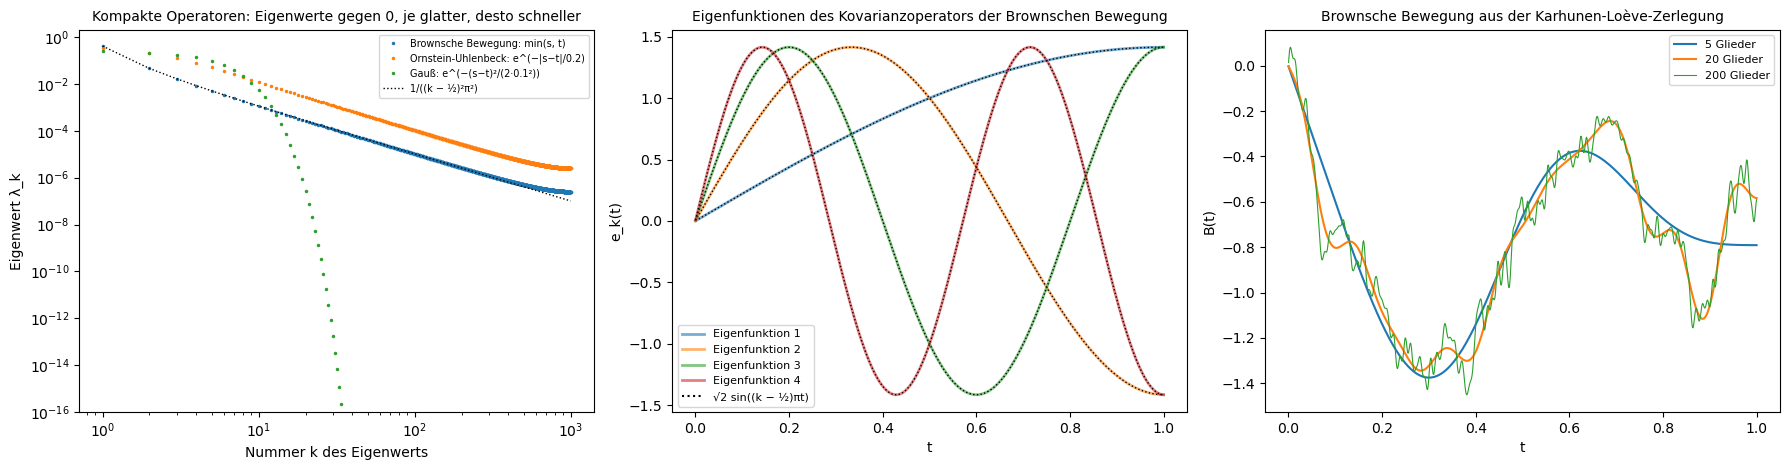

Brownsche Bewegung, Eigenwerte 1 … 4: [0.405285, 0.045032, 0.016211, 0.008271];  Formel: [0.405285, 0.045032, 0.016211, 0.008271]
Spur Σλ = 0.500000 (Theorie 1/2), Σλ² = 0.166667 (Theorie 1/6 = 0.166667)
Anteil der Varianz in den ersten 1, 5, 20 Gliedern: 0.8106, 0.9596, 0.9899  (8/π² = 0.8106)
Brownsche Bewegung: min(s, t)        λ₁ = 0.4053, λ₁₀/λ₁ = 2.77e-03, λ₃₀/λ₁ = 2.87e-04
Ornstein-Uhlenbeck: e^(−|s−t|/0.2)   λ₁ = 0.3309, λ₁₀/λ₁ = 3.58e-02, λ₃₀/λ₁ = 3.62e-03
Gauß: e^(−(s−t)²/(2·0.1²))           λ₁ = 0.2409, λ₁₀/λ₁ = 2.32e-02, λ₃₀/λ₁ = 7.03e-13


In [7]:
kernels6 = {"Brownsche Bewegung: min(s, t)": lambda s, t: np.minimum(s, t),
            "Ornstein-Uhlenbeck: e^(−|s−t|/0.2)": lambda s, t: np.exp(-np.abs(s - t) / 0.2),
            "Gauß: e^(−(s−t)²/(2·0.1²))": lambda s, t: np.exp(-(s - t) ** 2 / 0.02)}
eig6 = {}
for name, k in kernels6.items():
    Kn, x6, w6 = integral_operator(k, 1000)
    lam_, V_ = np.linalg.eigh(Kn)
    order = np.argsort(lam_)[::-1]
    eig6[name] = (lam_[order], V_[:, order] * np.sqrt(1000))     # Eigenfunktionen L²-normiert
lamB, VB = eig6["Brownsche Bewegung: min(s, t)"]
kk = np.arange(1, 1001)
lam_exact = 1 / ((kk - 0.5) ** 2 * np.pi ** 2)
rng = np.random.default_rng(6)
xi = rng.normal(size=1000)
paths = {M: (VB[:, :M] * np.sqrt(np.maximum(lamB[:M], 0))) @ xi[:M] for M in (5, 20, 200)}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for (name, (lam_, _)), c in zip(eig6.items(), ("C0", "C1", "C2")):
    pos = lam_[lam_ > 1e-16]
    ax.loglog(np.arange(1, len(pos) + 1), pos, ".", ms=3, color=c, label=name)
ax.loglog(kk, lam_exact, "k:", lw=1, label="1/((k − ½)²π²)")
ax.set_ylim(1e-16, 2)
ax.set_xlabel("Nummer k des Eigenwerts")
ax.set_ylabel("Eigenwert λ_k")
ax.set_title("Kompakte Operatoren: Eigenwerte gegen 0, je glatter, desto schneller", fontsize=10)
ax.legend(fontsize=7)
ax = axes[1]
for k_, c in zip(range(4), ("C0", "C1", "C2", "C3")):
    sgn = np.sign(VB[50, k_])
    ax.plot(x6, sgn * VB[:, k_], color=c, lw=2, alpha=0.6, label=f"Eigenfunktion {k_ + 1}")
    ax.plot(x6, np.sqrt(2) * np.sin((k_ + 0.5) * np.pi * x6), "k:", lw=1)
ax.plot([], [], "k:", label="√2 sin((k − ½)πt)")
ax.set_xlabel("t"); ax.set_ylabel("e_k(t)")
ax.set_title("Eigenfunktionen des Kovarianzoperators der Brownschen Bewegung", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
for M, c in zip(paths, ("C0", "C1", "C2")):
    ax.plot(x6, paths[M], color=c, lw=1.5 if M < 200 else 0.8, label=f"{M} Glieder")
ax.set_xlabel("t"); ax.set_ylabel("B(t)")
ax.set_title("Brownsche Bewegung aus der Karhunen-Loève-Zerlegung", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Brownsche Bewegung, Eigenwerte 1 … 4: {np.round(lamB[:4], 6).tolist()};  Formel: {np.round(lam_exact[:4], 6).tolist()}")
print(f"Spur Σλ = {lamB.sum():.6f} (Theorie 1/2), Σλ² = {np.sum(lamB ** 2):.6f} (Theorie 1/6 = {1 / 6:.6f})")
print("Anteil der Varianz in den ersten 1, 5, 20 Gliedern: " + ", ".join(f"{lamB[:M].sum() / lamB.sum():.4f}" for M in (1, 5, 20)) + f"  (8/π² = {8 / np.pi ** 2:.4f})")
for name, (lam_, _) in eig6.items():
    print(f"{name:36s} λ₁ = {lam_[0]:.4f}, λ₁₀/λ₁ = {lam_[9] / lam_[0]:.2e}, λ₃₀/λ₁ = {lam_[29] / lam_[0]:.2e}")

* **Links** (beide Achsen logarithmisch) fallen die Eigenwerte der Brownschen Bewegung genau auf der Kurve $1/((k - \tfrac12)^2\pi^2)$, also wie $k^{-2}$; die Ornstein-Uhlenbeck-Eigenwerte ebenfalls wie $k^{-2}$, nur höher. Die Gauß-Eigenwerte fallen dagegen schneller als exponentiell und erreichen bei $k\approx30$ die Rechengenauigkeit; laut **Ausgabe** ist $\lambda_{30}/\lambda_1 = 7\cdot10^{-13}$ gegen $3\cdot10^{-4}$ bei der Brownschen Bewegung. Für sehr große $k$ weichen die Nyström-Eigenwerte vom Gesetz ab, weil das Gitter dort zu grob ist.
* In der **Mitte** liegen die berechneten Eigenfunktionen auf den Formeln $\sqrt2\sin((k - \tfrac12)\pi t)$. Laut Ausgabe stimmen die ersten vier Eigenwerte auf sechs Stellen, die Spur ist 0.500000 und $\sum\lambda^2 = 0.166667$, wie die Theorie verlangt.
* **Rechts** zeigen dieselben Zufallszahlen mit 5, 20 und 200 Gliedern denselben Pfad in immer feinerer Auflösung: Die ersten Glieder legen den groben Verlauf fest, die späteren fügen kleine Zacken hinzu. Laut Ausgabe tragen das erste Glied 81.06 % der Varianz (genau $8/\pi^2$) und die ersten 20 schon 98.99 %. Das beantwortet die Vorhersage.
* **Wo es vorkommt:** Karhunen-Loève heißt in der Datenanalyse Hauptkomponentenanalyse für Funktionen (funktionale Datenanalyse, Eigengesichter, Strömungsmoden als Proper Orthogonal Decomposition), in der Unsicherheitsquantifizierung stellt man Zufallsfelder (Bodenparameter, Materialfehler) mit wenigen Gliedern dar, und Gauß-Prozesse werden mit abgeschnittenen Mercer-Zerlegungen oder Random Fourier Features schnell gemacht. Der Abfall der Eigenwerte bestimmt, wie viele Messungen man braucht und wie gut Kernmethoden verallgemeinern.

##### *7. Arten des Spektrums: Volterra, Multiplikation, Shift*

Kann ein Operator ein Spektrum haben, aber keinen einzigen Eigenwert? Vorher vorhersagen: Der Volterra-Operator $(Vf)(x) = \int_0^xf$ hat die Norm $2/\pi\approx0.64$. Wie groß ist sein Spektralradius?

Links wird die Gelfand-Formel $r(A) = \lim\Vert A^n\Vert^{1/n}$ für den Volterra-Operator und für den Green-Operator aus Exp. 5 ausgewertet (Matrizen mit 400 Punkten). In der Mitte wird für den Multiplikationsoperator $(Mf)(x) = xf(x)$ auf $L^2[0, 1]$ eine Folge immer schmalerer normierter Gauß-Funktionen um $x = 0.5$ gemessen: der Rest $\Vert(M - 0.5)\psi_\sigma\Vert$ und das Skalarprodukt mit der festen Funktion 1. Rechts steht die quadrierte Norm der abgeschnittenen Folgen $v_\lambda = (1, \lambda, \lambda^2, \dots)$, der Eigenvektoren des Linksshifts. Die Ausgabe prüft außerdem, dass das Bild von $S - \lambda$ für den Rechtsshift $S$ senkrecht auf $v_\lambda$ steht.

**Hintergrund & Fachbegriffe:**
- **Punkt-, kontinuierliches und Restspektrum, Spektralradius, approximative Eigenwerte:** siehe Theorie, Abschnitt 5.
- **Volterra-Operator** $V$: das unbestimmte Integral ab 0; **quasinilpotent** heißt $r(V) = 0$, obwohl $V\neq0$.
- **Multiplikationsoperator** $M$: Multiplikation mit der Variablen; in der Quantenmechanik der Ortsoperator.
- **Rechtsshift** $S(x_1, x_2, \dots) = (0, x_1, x_2, \dots)$ und **Linksshift** $S^\dagger(x_1, x_2, \dots) = (x_2, x_3, \dots)$ auf $\ell^2$.
- **Weyl-Folge:** normierte $\psi_n$ mit $\Vert(A - z)\psi_n\Vert\to0$; sie zeigt, dass $z$ im Spektrum liegt, auch wenn es keinen Eigenvektor gibt.

**Theorie:**

- **Volterra:** $(V^nf)(x) = \int_0^x\frac{(x - y)^{n-1}}{(n - 1)!}f(y)\,dy$, also $\Vert V^n\Vert\leq1/n!$ und $\Vert V^n\Vert^{1/n}\to0$: Das Spektrum ist $\lbrace0\rbrace$. Trotzdem ist 0 kein Eigenwert ($Vf = 0$ heißt $f = 0$). $V$ ist kompakt und nicht normal; bei normalen Operatoren wäre $r = \Vert V\Vert$.
- **Multiplikation:** $Mf = zf$ verlangt $f = 0$ außerhalb des Punktes $z$, also $f = 0$ in $L^2$: kein Eigenwert. Für $z\in[0, 1]$ ist $(M - z)^{-1}$, die Multiplikation mit $1/(x - z)$, aber unbeschränkt; das Spektrum ist $[0, 1]$, rein kontinuierlich. Die Weyl-Folge schmaler Gauß-Funktionen hat $\Vert(M - z)\psi_\sigma\Vert = \sigma/\sqrt2\to0$, konvergiert aber schwach gegen 0, nicht gegen einen Eigenvektor.
- **Shifts:** Der Linksshift hat für jedes $\vert\lambda\vert < 1$ den Eigenvektor $v_\lambda$ mit $\Vert v_\lambda\Vert^2 = 1/(1 - \vert\lambda\vert^2)$; die offene Kreisscheibe ist Punktspektrum. Der Rechtsshift ist eine Isometrie, $\Vert(S - \lambda)x\Vert\geq(1 - \vert\lambda\vert)\Vert x\Vert$, also injektiv, aber sein Bild steht senkrecht auf $v_{\bar\lambda}$ und ist nicht dicht: Restspektrum. $S$ ist ein Fredholm-Operator vom Index $-1$, $S^\dagger S = 1$, aber $SS^\dagger\neq1$.

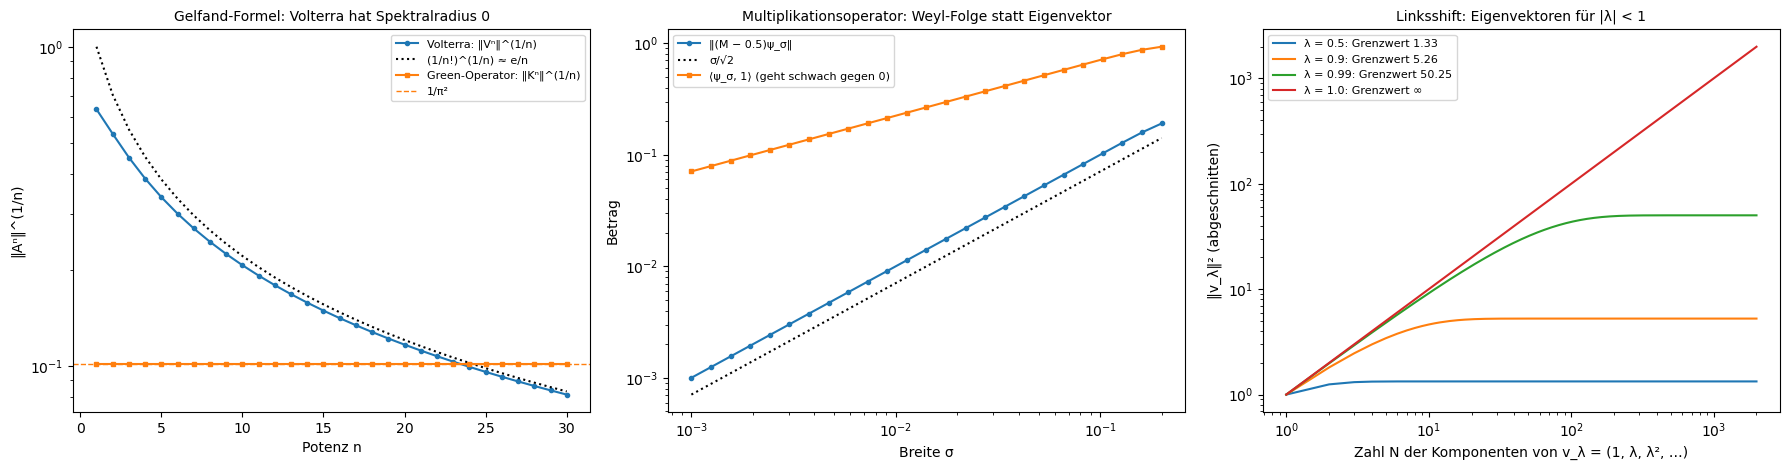

Volterra: ‖V‖ = 0.63662 (2/π = 0.63662), ‖V⁵‖ = 4.39e-03 ≤ 1/5! = 8.33e-03, ‖V³⁰‖^(1/30) = 0.0812
Green-Operator: ‖K³⁰‖^(1/30) = 0.10132 (1/π² = 0.10132); die Matrix-Eigenwerte des diskreten Volterra-Operators sind alle h/2 = 0.00125
Weyl-Folge: Rest bei σ = 0.001: 1.00e-03, Skalarprodukt mit 1: 7.08e-02
Rechtsshift, λ = 0.6: ⟨v_λ, (S − λ)x⟩ = 0.0e+00 für zufälliges x; ‖(S − λ)x‖/‖x‖ = 1.130 ≥ 1 − λ = 0.4


In [8]:
n7 = 400
h7 = 1 / n7
V7 = (np.tril(np.ones((n7, n7)), -1) + 0.5 * np.eye(n7)) * h7         # Volterra mit Trapez-Gewichten
K7 = integral_operator(G, n7)[0]
pw = np.arange(1, 31)
gel_V = np.array([opnorm(np.linalg.matrix_power(V7, k)) ** (1 / k) for k in pw])
gel_K = np.array([opnorm(np.linalg.matrix_power(K7, k)) ** (1 / k) for k in pw])
bound = np.array([(1 / factorial(k)) ** (1 / k) for k in pw])
x7, w7 = grid01(20000)
sigs = np.logspace(-3, -0.7, 25)
resid, overlap7 = [], []
for s in sigs:
    psi = np.exp(-(x7 - 0.5) ** 2 / (4 * s * s)); psi /= l2(psi, w7)
    resid.append(l2((x7 - 0.5) * psi, w7)); overlap7.append(np.sum(w7 * psi))
Ns7 = np.arange(1, 2001)
norms_v = {lam: np.cumsum(lam ** (2 * (Ns7 - 1))) for lam in (0.5, 0.9, 0.99, 1.0)}
rng = np.random.default_rng(7)
xr = np.r_[rng.normal(size=50), np.zeros(450)]
Sx = np.r_[0, xr[:-1]]
lam7 = 0.6
perp = np.dot(lam7 ** np.arange(500), Sx - lam7 * xr)
lower = np.linalg.norm(Sx - lam7 * xr) / np.linalg.norm(xr)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.semilogy(pw, gel_V, "o-", ms=3, label="Volterra: ‖Vⁿ‖^(1/n)")
ax.semilogy(pw, bound, "k:", label="(1/n!)^(1/n) ≈ e/n")
ax.semilogy(pw, gel_K, "s-", ms=3, label="Green-Operator: ‖Kⁿ‖^(1/n)")
ax.axhline(1 / np.pi ** 2, color="C1", ls="--", lw=1, label="1/π²")
ax.set_xlabel("Potenz n")
ax.set_ylabel("‖Aⁿ‖^(1/n)")
ax.set_title("Gelfand-Formel: Volterra hat Spektralradius 0", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
ax.loglog(sigs, resid, "o-", ms=3, label="‖(M − 0.5)ψ_σ‖")
ax.loglog(sigs, sigs / np.sqrt(2), "k:", label="σ/√2")
ax.loglog(sigs, overlap7, "s-", ms=3, label="⟨ψ_σ, 1⟩ (geht schwach gegen 0)")
ax.set_xlabel("Breite σ")
ax.set_ylabel("Betrag")
ax.set_title("Multiplikationsoperator: Weyl-Folge statt Eigenvektor", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
for lam, c in zip(norms_v, ("C0", "C1", "C2", "C3")):
    ax.loglog(Ns7, norms_v[lam], color=c, label=f"λ = {lam}: Grenzwert {'∞' if lam == 1 else f'{1 / (1 - lam * lam):.2f}'}")
ax.set_xlabel("Zahl N der Komponenten von v_λ = (1, λ, λ², …)")
ax.set_ylabel("‖v_λ‖² (abgeschnitten)")
ax.set_title("Linksshift: Eigenvektoren für |λ| < 1", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Volterra: ‖V‖ = {opnorm(V7):.5f} (2/π = {2 / np.pi:.5f}), ‖V⁵‖ = {opnorm(np.linalg.matrix_power(V7, 5)):.2e} ≤ 1/5! = {1 / 120:.2e}, ‖V³⁰‖^(1/30) = {gel_V[-1]:.4f}")
print(f"Green-Operator: ‖K³⁰‖^(1/30) = {gel_K[-1]:.5f} (1/π² = {1 / np.pi ** 2:.5f}); die Matrix-Eigenwerte des diskreten Volterra-Operators sind alle h/2 = {h7 / 2}")
print(f"Weyl-Folge: Rest bei σ = 0.001: {resid[0]:.2e}, Skalarprodukt mit 1: {overlap7[0]:.2e}")
print(f"Rechtsshift, λ = {lam7}: ⟨v_λ, (S − λ)x⟩ = {perp:.1e} für zufälliges x; ‖(S − λ)x‖/‖x‖ = {lower:.3f} ≥ 1 − λ = {1 - lam7:.1f}")

* **Links** fällt $\Vert V^n\Vert^{1/n}$ wie die Schranke $(1/n!)^{1/n}\approx e/n$ und erreicht laut **Ausgabe** bei $n = 30$ den Wert 0.081, weiter gegen 0, obwohl $\Vert V\Vert = 0.63662 = 2/\pi$ ist. Das beantwortet die Vorhersage: Der Spektralradius ist 0. Beim Green-Operator bleibt $\Vert K^n\Vert^{1/n} = 1/\pi^2$ für jedes $n$, weil er selbstadjungiert ist. Die Matrix des diskreten Volterra-Operators hat übrigens den $400$-fachen Eigenwert $h/2 = 0.00125$, eine Spur des Gitters, die mit $h\to0$ verschwindet.
* In der **Mitte** geht der Rest $\Vert(M - 0.5)\psi_\sigma\Vert$ wie $\sigma/\sqrt2$ gegen 0 ($10^{-3}$ bei $\sigma = 10^{-3}$): 0.5 liegt im Spektrum. Gleichzeitig geht das Skalarprodukt mit der festen Funktion 1 wie $\sqrt\sigma$ gegen 0 (0.071): Die Folge konvergiert schwach gegen 0, es gibt keinen Eigenvektor als Grenzwert.
* **Rechts** konvergieren die Normquadrate der abgeschnittenen $v_\lambda$ für $\lambda = 0.5$, 0.9, 0.99 gegen $1/(1 - \lambda^2)$ (1.33, 5.26, 50.25), für $\lambda = 1$ wachsen sie linear: Eigenvektoren des Linksshifts gibt es genau für $\vert\lambda\vert < 1$. Laut Ausgabe steht das Bild von $S - 0.6$ exakt senkrecht auf $v_{0.6}$ (Skalarprodukt 0) und $\Vert(S - 0.6)x\Vert/\Vert x\Vert = 1.13\geq0.4$: injektiv, aber nicht surjektiv, das Restspektrum des Rechtsshifts.
* **Wo es vorkommt:** Der Ortsoperator der Quantenmechanik ist ein Multiplikationsoperator mit rein kontinuierlichem Spektrum, und „Ortseigenzustände“ sind keine Vektoren, sondern Grenzwerte von Weyl-Folgen (Distributionen). Shifts beschreiben Verzögerungen in der Signalverarbeitung und Zeitreihen (der Rechtsshift ist der Verzögerungsoperator eines Filters), Wold-Zerlegungen stationärer Prozesse und Isometrien in der Quanteninformation. Quasinilpotente Operatoren wie Volterra treten bei Anfangswertproblemen auf: Deshalb hat jede lineare Volterra-Integralgleichung eine eindeutige Lösung, für jedes $\lambda$.

##### *8. Endliche Abschnitte täuschen: Toeplitz-Operatoren und Pseudospektren*

Darf man das Spektrum eines Operators aus den Eigenwerten großer abgeschnittener Matrizen ablesen? Vorher vorhersagen: Die Toeplitz-Matrix mit 1 auf der unteren und 0.25 auf der oberen Nebendiagonale hat nur reelle Eigenwerte in $(-1, 1)$. Was passiert mit ihnen, wenn man jeden Eintrag um $10^{-10}$ stört?

Der Code nimmt den $60\times60$-Abschnitt $T_{60}$ des Toeplitz-Operators mit dem Symbol $a(\theta) = e^{i\theta} + 0.25\,e^{-i\theta}$, einer Ellipse mit den Halbachsen 1.25 und 0.75. Links stehen die exakten Eigenwerte $\cos(k\pi/61)$, die von numpy berechneten und die von 20 zufällig gestörten Matrizen ($\Vert E\Vert\approx10^{-10}$ und $10^{-6}$). In der Mitte stehen die Höhenlinien von $\sigma_{\min}(z - T_{60})$, die Ränder der $\varepsilon$-Pseudospektren. Rechts wird $\Vert A^k\Vert$ für $A = T_{60}/1.1$ gegen $k$ aufgetragen und mit der symmetrischen Toeplitz-Matrix verglichen (0.5 auf beiden Nebendiagonalen), die genau dieselben Eigenwerte hat.

**Hintergrund & Fachbegriffe:**
- **Toeplitz-Matrix:** konstante Diagonalen, $a_{ij} = a_{i-j}$; der **Toeplitz-Operator** ist die unendliche Version auf $\ell^2$, das **Symbol** $a(\theta) = \sum_ka_ke^{ik\theta}$.
- **Endlicher Abschnitt:** die linke obere $n\times n$-Ecke eines Operators, das übliche Rechenmodell.
- **Pseudospektrum** $\sigma_\varepsilon(A)$: alle $z$ mit $\sigma_{\min}(z - A) < \varepsilon$, also alle Eigenwerte von Störungen der Größe $< \varepsilon$.
- **Nicht normal:** $A^\dagger A\neq AA^\dagger$; dann können Eigenvektoren fast parallel sein.
- **Transientes Wachstum:** $\Vert A^k\Vert$ wächst zunächst stark, obwohl alle Eigenwerte im Betrag kleiner als 1 sind.

**Theorie:**

- **Spektrum des Operators:** Für ein stetiges Symbol ist das Spektrum des Toeplitz-Operators die Kurve $a(\theta)$ zusammen mit den Punkten, um die sie mit Windungszahl $\neq0$ läuft (Gohberg); hier die ganze Ellipse mit Innerem. Die endlichen Abschnitte haben dagegen Eigenwerte $2\sqrt{1\cdot0.25}\cos(k\pi/(n + 1))$, alle auf der Strecke $[-1, 1]$, für jedes $n$. Die Abschnitte konvergieren nicht gegen das richtige Spektrum.
- **Pseudospektren konvergieren:** $\sigma_\varepsilon(T_n)$ nähert sich für $n\to\infty$ dem $\varepsilon$-Pseudospektrum des Operators, das die Ellipse enthält. Winzige Störungen (auch Rundungsfehler) treiben die Eigenwerte deshalb an den Rand der Ellipse; die Eigenwerte selbst sind numerisch kaum berechenbar.
- **Dynamik:** Für normale Matrizen ist $\Vert A^k\Vert = r(A)^k$. Für nicht normale wächst $\Vert A^k\Vert$ zunächst ungefähr wie $\max\vert a(\theta)\vert^k$, hier $(1.25/1.1)^k$, bevor die Eigenwerte das Abklingen erzwingen. Solches Wachstum erklärt, warum Strömungen umschlagen, obwohl die lineare Stabilitätsanalyse Stabilität vorhersagt (Trefethen et al. 1993).

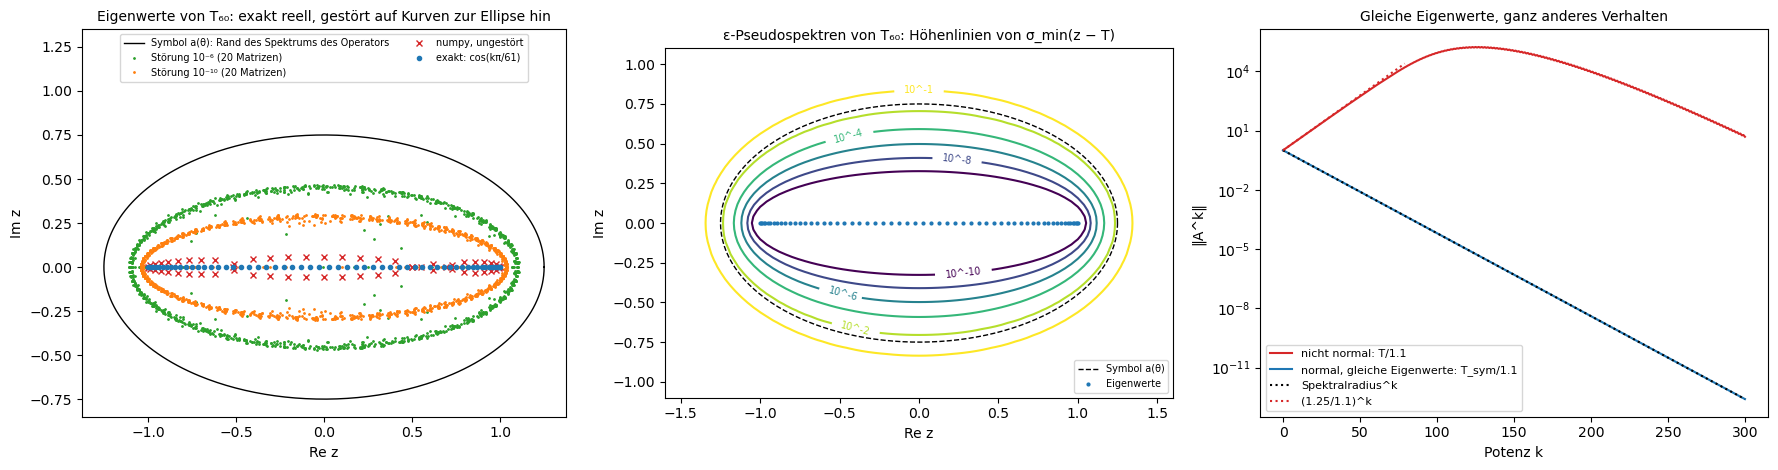

numpy-Eigenwerte von T₆₀: größter Imaginärteil 5.84e-02, größter Fehler gegen cos(kπ/61) 4.30e-02
Störung 1e-10: mittlerer Betrag 0.711, Median des Abstands zur Ellipse (relativ) 0.584, größter Imaginärteil 0.300
Störung 1e-06: mittlerer Betrag 0.800, Median des Abstands zur Ellipse (relativ) 0.441, größter Imaginärteil 0.468
nicht normal: T/1.1                    max ‖A^k‖ = 1.69e+05 bei k = 127, ‖A³⁰⁰‖ = 4.82e+00
normal, gleiche Eigenwerte: T_sym/1.1  max ‖A^k‖ = 1 bei k = 0, ‖A³⁰⁰‖ = 2.57e-13
σ_min(z − T₆₀) bei z = 0.5i (innerhalb der Ellipse, weit weg von allen Eigenwerten): 1.13e-06


In [9]:
n8 = 60
T8 = toeplitz(np.r_[0, 1.0, np.zeros(n8 - 2)], np.r_[0, 0.25, np.zeros(n8 - 2)])
Tsym = toeplitz(np.r_[0, 0.5, np.zeros(n8 - 2)])
ev_exact = np.cos(np.arange(1, n8 + 1) * np.pi / (n8 + 1))
ev_np = np.linalg.eigvals(T8)
rng = np.random.default_rng(8)
pert = {eps: np.concatenate([np.linalg.eigvals(T8 + eps * rng.normal(size=T8.shape) / np.sqrt(n8)) for _ in range(20)]) for eps in (1e-10, 1e-6)}
th8 = np.linspace(0, 2 * np.pi, 400)
symbol = np.exp(1j * th8) + 0.25 * np.exp(-1j * th8)
gx, gy = np.linspace(-1.6, 1.6, 81), np.linspace(-1.1, 1.1, 57)
smin = np.array([[svdvals((a + 1j * b) * np.eye(n8) - T8)[-1] for a in gx] for b in gy])
ks = np.arange(0, 301)
growth = {}
for name, M in (("nicht normal: T/1.1", T8 / 1.1), ("normal, gleiche Eigenwerte: T_sym/1.1", Tsym / 1.1)):
    P_, out = np.eye(n8), []
    for k in ks:
        out.append(opnorm(P_))
        P_ = P_ @ M
    growth[name] = np.array(out)
ell_dist = lambda z: np.abs((z.real / 1.25) ** 2 + (z.imag / 0.75) ** 2 - 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.plot(symbol.real, symbol.imag, "k-", lw=1, label="Symbol a(θ): Rand des Spektrums des Operators")
ax.plot(pert[1e-6].real, pert[1e-6].imag, ".", color="C2", ms=2, label="Störung 10⁻⁶ (20 Matrizen)")
ax.plot(pert[1e-10].real, pert[1e-10].imag, ".", color="C1", ms=2, label="Störung 10⁻¹⁰ (20 Matrizen)")
ax.plot(ev_np.real, ev_np.imag, "x", color="C3", ms=4, label="numpy, ungestört")
ax.plot(ev_exact, 0 * ev_exact, "o", color="C0", ms=3, label="exakt: cos(kπ/61)")
ax.set_aspect("equal")
ax.set_xlabel("Re z"); ax.set_ylabel("Im z")
ax.set_ylim(-0.85, 1.35)
ax.set_title("Eigenwerte von T₆₀: exakt reell, gestört auf Kurven zur Ellipse hin", fontsize=10)
ax.legend(fontsize=7, loc="upper center", ncol=2)
ax = axes[1]
cs = ax.contour(gx, gy, np.log10(smin), levels=[-10, -8, -6, -4, -2, -1], cmap="viridis")
ax.clabel(cs, fmt=lambda v: f"10^{int(v)}", fontsize=7)
ax.plot(symbol.real, symbol.imag, "k--", lw=1, label="Symbol a(θ)")
ax.plot(ev_exact, 0 * ev_exact, "o", color="C0", ms=2, label="Eigenwerte")
ax.set_aspect("equal")
ax.set_xlabel("Re z"); ax.set_ylabel("Im z")
ax.set_title("ε-Pseudospektren von T₆₀: Höhenlinien von σ_min(z − T)", fontsize=10)
ax.legend(fontsize=7, loc="lower right")
ax = axes[2]
for name, c in zip(growth, ("C3", "C0")):
    ax.semilogy(ks, growth[name], color=c, label=name)
ax.semilogy(ks, (np.cos(np.pi / 61) / 1.1) ** ks, "k:", label="Spektralradius^k")
ax.semilogy(ks[:80], (1.25 / 1.1) ** ks[:80], "C3:", label="(1.25/1.1)^k")
ax.set_xlabel("Potenz k")
ax.set_ylabel("‖A^k‖")
ax.set_title("Gleiche Eigenwerte, ganz anderes Verhalten", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"numpy-Eigenwerte von T₆₀: größter Imaginärteil {np.abs(ev_np.imag).max():.2e}, größter Fehler gegen cos(kπ/61) {np.abs(np.sort(ev_np.real) - np.sort(ev_exact)).max():.2e}")
for eps, z in pert.items():
    print(f"Störung {eps:.0e}: mittlerer Betrag {np.abs(z).mean():.3f}, Median des Abstands zur Ellipse (relativ) {np.median(ell_dist(z)):.3f}, größter Imaginärteil {np.abs(z.imag).max():.3f}")
for name, g in growth.items():
    print(f"{name:38s} max ‖A^k‖ = {g.max():.3g} bei k = {int(ks[np.argmax(g)])}, ‖A³⁰⁰‖ = {g[-1]:.2e}")
print(f"σ_min(z − T₆₀) bei z = 0.5i (innerhalb der Ellipse, weit weg von allen Eigenwerten): {svdvals(0.5j * np.eye(n8) - T8)[-1]:.2e}")

* **Links** liegen die exakten Eigenwerte $\cos(k\pi/61)$ auf der reellen Strecke $(-1, 1)$. Schon numpy trifft sie nicht: Laut **Ausgabe** haben die berechneten Werte Imaginärteile bis 0.058 und Fehler bis 0.043, allein durch Rundungsfehler der Größe $10^{-16}$. Störungen von $10^{-10}$ (orange) und $10^{-6}$ (grün) schieben die Eigenwerte auf Kurven, die mit der Störung zur Symbol-Ellipse hin wandern (mittlerer Betrag 0.71 bzw. 0.80, Imaginärteile bis 0.30 bzw. 0.47). Das beantwortet die Vorhersage.
* In der **Mitte** stehen die Höhenlinien von $\sigma_{\min}(z - T_{60})$: Die Kurven der gestörten Eigenwerte links liegen etwa auf den Linien $10^{-10}$ und $10^{-6}$. Laut Ausgabe ist $\sigma_{\min}(0.5i - T_{60}) = 1.1\cdot10^{-6}$, obwohl $0.5i$ weit von jedem Eigenwert entfernt ist. Für $n\to\infty$ füllen die Pseudospektren das Innere der Ellipse, das Spektrum des Toeplitz-Operators.
* **Rechts** (logarithmische Achse) fällt $\Vert A^k\Vert$ für die symmetrische Matrix ab dem ersten Schritt wie der Spektralradius hoch $k$, für die nicht normale mit genau denselben Eigenwerten wächst es dagegen wie $(1.25/1.1)^k$ auf $1.7\cdot10^5$ bei $k = 127$ und ist bei $k = 300$ immer noch 4.8. Die Eigenwerte sagen über das Verhalten für endliche Zeiten fast nichts.
* **Wo es vorkommt:** Pseudospektren erklären den Umschlag von laminaren zu turbulenten Strömungen trotz linearer Stabilität (Trefethen et al. 1993), die Empfindlichkeit von Konvektions-Diffusions-Diskretisierungen, das Verhalten iterativer Löser wie GMRES, das transiente Wachstum in Ökologie- und Klimamodellen und das Rauschen in nicht hermiteschen Lasersystemen. Toeplitz-Operatoren sind die Faltungsoperatoren der Signalverarbeitung und die Kovarianzmatrizen stationärer Zeitreihen; endliche Abschnitte davon benutzt man ständig, und man muss wissen, wann ihre Eigenwerte täuschen.

##### *9. Spektralmaß: gebundene Zustände und kontinuierliches Spektrum*

Wie unterscheidet sich ein Punktspektrum von einem kontinuierlichen, wenn man ohnehin nur auf endlichen Gittern rechnen kann? Vorher vorhersagen: Ein Teilchen sitzt am Anfang im Potentialtopf. Wie viel seiner Aufenthaltswahrscheinlichkeit bleibt für lange Zeiten dort?

Der Hamilton-Operator ist $H = -\tfrac12\frac{d^2}{dx^2} + V(x)$ mit dem Pöschl-Teller-Topf $V(x) = -\tfrac{\lambda(\lambda + 1)}2\,\mathrm{sech}^2x$, $\lambda = 2.5$, diskretisiert mit Gitterweite 0.03 in einem Kasten der Länge $L$ (Dirichlet-Rand). Links stehen die Eigenwerte gegen $L$, in der Mitte die Verteilungsfunktion des Spektralmaßes eines Wellenpakets für drei Kastenlängen, rechts die Überlebenswahrscheinlichkeit $\vert\langle\psi\vert e^{-iHt}\psi\rangle\vert^2$ mit der Vorhersage aus den gebundenen Zuständen allein.

**Hintergrund & Fachbegriffe:**
- **Gebundener Zustand:** ein normierbarer Eigenvektor, hier mit negativer Energie; **Streuzustand:** Energie $> 0$, das Teilchen läuft weg.
- **Pöschl-Teller-Potential:** ein Topf, dessen gebundene Energien exakt bekannt sind, $E_n = -\tfrac12(\lambda - n)^2$ für $n < \lambda$; für $\lambda = 2.5$ also $-3.125$, $-1.125$, $-0.125$.
- **Spektralmaß** $\mu_\psi$ eines Zustands: die Verteilung der Energie-Messwerte; in einem endlichen Kasten $\sum_k\vert\langle k\vert\psi\rangle\vert^2\delta(E - E_k)$.
- **Überlebenswahrscheinlichkeit:** die Wahrscheinlichkeit, das System zur Zeit $t$ wieder im Anfangszustand zu finden; ihre Amplitude ist die Fourier-Transformierte des Spektralmaßes.

**Theorie:**

- **Zerlegung:** $H$ hat drei gebundene Zustände (Punktspektrum) und das kontinuierliche Spektrum $[0, \infty)$. Im Kasten wird alles diskret, aber verschieden: Die gebundenen Energien hängen nicht von $L$ ab, die Kasten-Energien des Kontinuums rücken wie $1/L^2$ zusammen und füllen $[0, \infty)$. Das Spektralmaß eines Zustands hat Sprünge an den gebundenen Energien und konvergiert sonst gegen eine stetige Verteilung.
- **RAGE-Satz** (Ruelle, Amrein, Georgescu, Enß): Der Anteil eines Zustands im kontinuierlichen Spektrum verlässt jedes beschränkte Gebiet im Zeitmittel, der Anteil im Punktspektrum bleibt lokalisiert. Die Überlebensamplitude ist $\int e^{-iEt}d\mu_\psi(E)$; der kontinuierliche Teil geht nach Riemann-Lebesgue gegen 0, übrig bleibt $\sum_{\mathrm{geb.}}\vert c_n\vert^2e^{-iE_nt}$.
- Das ist die physikalische Bedeutung der Spektralzerlegung: Punktspektrum heißt gebunden, kontinuierliches Spektrum heißt Streuung.

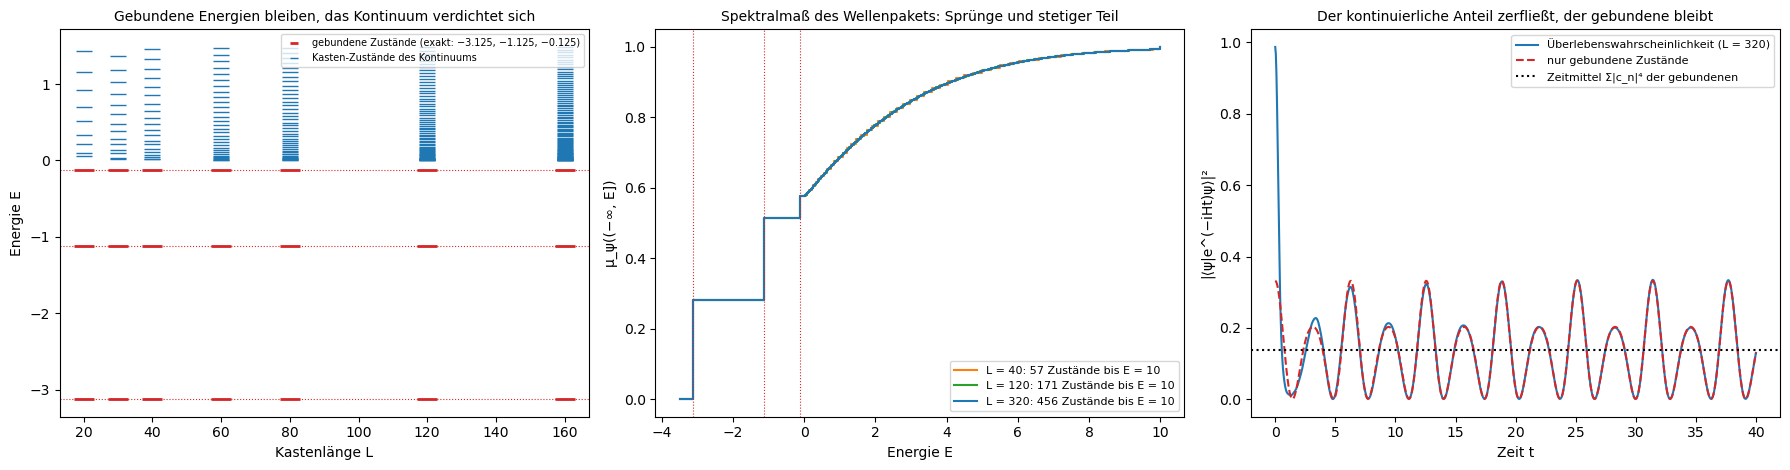

Gebundene Energien (L = 320): [-3.1251, -1.1253, -0.1252];  exakt [-3.125, -1.125, -0.125]
Gewicht des Pakets auf den gebundenen Zuständen: [0.2807, 0.2326, 0.0629], zusammen 0.5762;  Kontinuum 0.4174
L =  40: 57 Eigenwerte bis E = 10, kleinste positive Energie 0.0125, gebundenes Gewicht 0.5762
L = 120: 171 Eigenwerte bis E = 10, kleinste positive Energie 0.0014, gebundenes Gewicht 0.5762
L = 320: 456 Eigenwerte bis E = 10, kleinste positive Energie 0.0002, gebundenes Gewicht 0.5762
Überlebenswahrscheinlichkeit für t > 20: gemessen im Mittel 0.1318, nur gebunden 0.1316;  größte Abweichung 0.0035


In [10]:
lam9 = 2.5
V9 = lambda x: -lam9 * (lam9 + 1) / 2 / np.cosh(x) ** 2
h9 = 0.03
def box_spectrum(L, Emax=10.0):
    x = np.arange(-L / 2 + h9, L / 2 - h9 / 2, h9)
    E, U = eigh_tridiagonal(1 / h9 ** 2 + V9(x), -0.5 / h9 ** 2 * np.ones(len(x) - 1), select="v", select_range=(-10, Emax))
    return x, E, U / np.sqrt(h9)
packet = lambda x: np.exp(-x ** 2 / (2 * 0.6 ** 2)) * np.exp(2.5j * x)
spec9 = {}
for L in (40, 120, 320):
    x, E, U = box_spectrum(L)
    psi = packet(x); psi /= np.sqrt(h9 * np.sum(np.abs(psi) ** 2))
    c = h9 * (U.T @ psi)
    spec9[L] = (E, np.abs(c) ** 2)
Ls9 = np.array([20, 30, 40, 60, 80, 120, 160])
levels = {L: box_spectrum(L, Emax=1.5)[1] for L in Ls9}
E640, p640 = spec9[320]
bound = E640 < 0
tt9 = np.linspace(0, 40, 801)
amp = np.array([np.sum(p640 * np.exp(-1j * E640 * t)) for t in tt9])
amp_b = np.array([np.sum(p640[bound] * np.exp(-1j * E640[bound] * t)) for t in tt9])
Egrid = np.linspace(-3.5, 10, 2000)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for L in Ls9:
    E = levels[L]
    ax.plot(np.full(len(E), L), E, "_", ms=12, color="C0")
    ax.plot(np.full((E < 0).sum(), L), E[E < 0], "_", ms=14, mew=2, color="C3")
for n in range(3):
    ax.axhline(-(lam9 - n) ** 2 / 2, color="C3", ls=":", lw=0.8)
ax.plot([], [], "_", color="C3", mew=2, label="gebundene Zustände (exakt: −3.125, −1.125, −0.125)")
ax.plot([], [], "_", color="C0", label="Kasten-Zustände des Kontinuums")
ax.set_xlabel("Kastenlänge L")
ax.set_ylabel("Energie E")
ax.set_title("Gebundene Energien bleiben, das Kontinuum verdichtet sich", fontsize=10)
ax.legend(fontsize=7, loc="upper right")
ax = axes[1]
for L, c in zip(spec9, ("C1", "C2", "C0")):
    E, p = spec9[L]
    ax.step(np.r_[Egrid[0], E, Egrid[-1]], np.r_[0, np.cumsum(p), 1], where="post", color=c, label=f"L = {L}: {len(E)} Zustände bis E = 10")
for n in range(3):
    ax.axvline(-(lam9 - n) ** 2 / 2, color="C3", ls=":", lw=0.8)
ax.set_xlabel("Energie E")
ax.set_ylabel("μ_ψ((−∞, E])")
ax.set_title("Spektralmaß des Wellenpakets: Sprünge und stetiger Teil", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(tt9, np.abs(amp) ** 2, "C0", label="Überlebenswahrscheinlichkeit (L = 320)")
ax.plot(tt9, np.abs(amp_b) ** 2, "C3--", label="nur gebundene Zustände")
ax.axhline(np.sum(p640[bound] ** 2), color="k", ls=":", label="Zeitmittel Σ|c_n|⁴ der gebundenen")
ax.set_xlabel("Zeit t")
ax.set_ylabel("|⟨ψ|e^(−iHt)ψ⟩|²")
ax.set_title("Der kontinuierliche Anteil zerfließt, der gebundene bleibt", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Gebundene Energien (L = 320): {np.round(E640[bound], 4).tolist()};  exakt {[-(lam9 - n) ** 2 / 2 for n in range(3)]}")
print(f"Gewicht des Pakets auf den gebundenen Zuständen: {np.round(p640[bound], 4).tolist()}, zusammen {p640[bound].sum():.4f};  Kontinuum {p640[~bound].sum():.4f}")
for L, (E, p) in spec9.items():
    print(f"L = {L:3d}: {len(E)} Eigenwerte bis E = 10, kleinste positive Energie {E[E > 0].min():.4f}, gebundenes Gewicht {p[E < 0].sum():.4f}")
late = tt9 > 20
print(f"Überlebenswahrscheinlichkeit für t > 20: gemessen im Mittel {np.mean(np.abs(amp[late]) ** 2):.4f}, nur gebunden {np.mean(np.abs(amp_b[late]) ** 2):.4f};  größte Abweichung {np.abs(np.abs(amp[late]) ** 2 - np.abs(amp_b[late]) ** 2).max():.4f}")

* **Links** liegen die drei gebundenen Energien (rot) für jede Kastenlänge an derselben Stelle, laut **Ausgabe** $-3.1251$, $-1.1253$, $-0.1252$ gegen exakt $-3.125$, $-1.125$, $-0.125$. Die Kasten-Zustände des Kontinuums (blau) rücken mit wachsendem $L$ immer dichter an $E = 0$ heran; die kleinste positive Energie fällt von 0.0125 ($L = 40$) auf 0.0002 ($L = 320$), und die Zahl der Zustände bis $E = 10$ wächst proportional zu $L$ (57, 171, 456).
* In der **Mitte** hat die Verteilungsfunktion des Spektralmaßes drei Sprünge an den gebundenen Energien mit den Höhen 0.281, 0.233 und 0.063 (zusammen 0.576) und steigt dann stetig bis 1; der stetige Teil trägt 0.417. Die Kurven für $L = 40$, 120 und 320 liegen praktisch aufeinander: Das Spektralmaß hängt nicht vom Kasten ab, nur seine Zerlegung in einzelne Linien.
* **Rechts** fällt die Überlebenswahrscheinlichkeit zuerst schnell (der Streuanteil läuft weg) und schwingt dann genau wie die Vorhersage aus den gebundenen Zuständen allein, mit den Frequenzen der Energiedifferenzen. Laut Ausgabe ist ihr Mittel für $t > 20$ gleich 0.132, die Vorhersage $\sum\vert c_n\vert^4$ 0.132, größte Abweichung 0.004. Das beantwortet die Vorhersage: Im Mittel bleibt eine Überlebenswahrscheinlichkeit von etwa 13 %, genau so viel, wie die gebundenen Zustände vorgeben; der kontinuierliche Anteil verschwindet.
* **Wo es vorkommt:** Atome und Moleküle haben diskrete gebundene Zustände unter einem Kontinuum (Ionisation, Photoeffekt), Halbleiter-Quantenpunkte und Störstellen gebundene Zustände in einem Band, Kernphysik und Teilchenphysik Resonanzen am Rand des Kontinuums. Spektralmaße und ihre Fourier-Transformation sind die Grundlage der Spektroskopie (das gemessene Spektrum ist ein Spektralmaß), der Zustandsdichte in der Festkörperphysik und der Methode der Kernel-Polynome, mit der man Spektren großer Systeme berechnet.

##### *10. Unbeschränkte Operatoren: Definitionsbereich und selbstadjungierte Erweiterungen*

Ist „der Impulsoperator auf einem Intervall“ eindeutig festgelegt? Vorher vorhersagen: Welche Eigenwerte hat $p = -i\frac{d}{dx}$ auf $[0, 1]$ mit der Randbedingung $\psi(1) = e^{i\theta}\psi(0)$, und was ist der kleinste Eigenwert von $-\frac{d^2}{dx^2}$ auf $[0, 1]$ mit Neumann-Rand?

Links werden $-\frac{d^2}{dx^2}$ und $p$ auf $[0, 1]$ mit 400 Punkten diskretisiert, die Randbedingung als „verdrehte“ Periodizität eingebaut. Die sieben tiefsten Eigenvektoren des Laplace-Operators sind ebene Wellen $e^{i(2\pi k + \theta)x}$, also auch Eigenvektoren von $p$; aufgetragen ist ihr Impuls $\langle v, pv\rangle$ gegen $\theta$. (Die Eigenwerte von $p$ direkt zu nehmen, ginge schief: zentrale Differenzen haben zu jeder Welle einen Doppelgänger mit wechselndem Vorzeichen, der ebenfalls kleine Eigenwerte liefert.) In der Mitte steht der kleinste Eigenwert von $-\frac{d^2}{dx^2}$ mit der Robin-Randbedingung $u'(0) = \kappa u(0)$, $u'(1) = -\kappa u(1)$ gegen $\kappa$, mit der exakten Lösung der transzendenten Gleichung. Rechts wird ein Wellenpaket nach links verschoben, auf der ganzen Geraden, auf $[0, 1]$ mit $\theta$-Randbedingung und auf der Halbgeraden $[0, \infty)$; gemessen wird die verbleibende Norm.

**Hintergrund & Fachbegriffe:**
- **Definitionsbereich, symmetrisch, selbstadjungiert, Defektindizes:** siehe Theorie, Abschnitt 7.
- **Randbedingungen:** **Dirichlet** $u = 0$, **Neumann** $u' = 0$, **Robin** $u' = \kappa u$ am Rand, **periodisch mit Phase** $\psi(1) = e^{i\theta}\psi(0)$ (Bloch-Bedingung).
- **Selbstadjungierte Erweiterung:** ein selbstadjungierter Operator, der auf dem kleineren Definitionsbereich mit dem symmetrischen übereinstimmt.
- **Verschiebung:** $(U(a)\psi)(x) = \psi(x - a)$, die Gruppe, die der Impuls erzeugt.

**Theorie:**

- **Impuls auf dem Intervall:** Auf glatten Funktionen mit $\psi(0) = \psi(1) = 0$ ist $p$ symmetrisch (partielle Integration ohne Randterme), aber nicht selbstadjungiert. Die Gleichungen $p^\dagger\psi = \pm i\psi$ haben die Lösungen $e^{\mp x}$, beide quadratintegrierbar auf $[0, 1]$: Defektindizes $(1, 1)$. Die selbstadjungierten Erweiterungen sind genau die Randbedingungen $\psi(1) = e^{i\theta}\psi(0)$, eine Familie mit einem Parameter, mit den Eigenwerten $2\pi k + \theta$. Physikalisch ist $\theta$ ein magnetischer Fluss durch einen Ring (Aharonov-Bohm) oder der Bloch-Impuls im Kristall.
- **Halbgerade:** Auf $[0, \infty)$ ist nur $e^{-x}$ quadratintegrierbar: Defektindizes $(1, 0)$, keine selbstadjungierte Erweiterung. Die Verschiebung nach links verliert Norm über den Rand bei 0; sie ist eine Isometrie in der anderen Richtung, aber keine unitäre Gruppe, und nach dem Satz von Stone gibt es deshalb keinen selbstadjungierten Erzeuger.
- **Laplace-Operator:** $-\frac{d^2}{dx^2}$ auf $[0, 1]$ hat Defektindizes $(2, 2)$ und eine Familie von Erweiterungen, darunter Dirichlet (Grundzustand $\pi^2$), Neumann (0) und Robin. Für $\kappa < 0$ zieht der Rand an, und es entstehen negative Eigenwerte, Zustände am Rand.

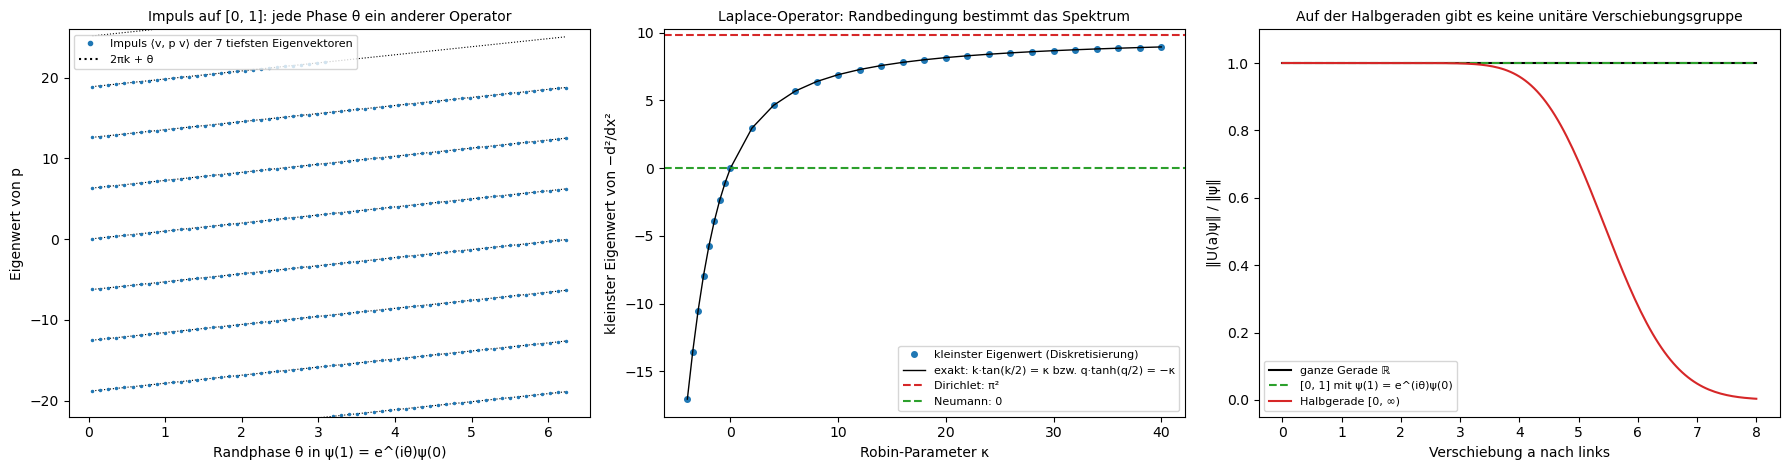

Diskretisierte Operatoren hermitesch für jedes θ (Fehler 0e+00); Impulse bei θ = 1.622: [-17.222, -10.943, -4.661, 1.622, 7.905, 14.185, 20.463], exakt [-17.228, -10.944, -4.661, 1.622, 7.905, 14.188, 20.472]
Robin κ =  -2.0: kleinster Eigenwert  -5.7569, exakt  -5.7569
Robin κ =   0.0: kleinster Eigenwert   0.0000, exakt   0.0000
Robin κ =   4.0: kleinster Eigenwert   4.6386, exakt   4.6386
Robin κ =  40.0: kleinster Eigenwert   8.9536, exakt   8.9536
Defektfunktionen e^(−x), e^(x): Norm² auf [0, 1] 0.4323 und 3.1945; auf [0, 30] 0.5000 und 5.71e+25
Verschiebung um a = 8: Norm auf der Halbgeraden 3.32e-03, auf dem Ring 1.000000


In [11]:
def twisted(n, theta, kind):
    """−i d/dx (kind = "p", zentrale Differenzen) oder −d²/dx² (kind = "L") auf [0, 1] mit ψ(1) = e^(iθ)ψ(0)."""
    h = 1 / n
    M = np.zeros((n, n), complex)
    for j in range(n):
        jp, jm = (j + 1) % n, (j - 1) % n
        fp = np.exp(1j * theta) if j == n - 1 else 1
        fm = np.exp(-1j * theta) if j == 0 else 1
        if kind == "p":
            M[j, jp] += -1j / (2 * h) * fp
            M[j, jm] += 1j / (2 * h) * fm
        else:
            M[j, j] += 2 / h ** 2
            M[j, jp] += -fp / h ** 2
            M[j, jm] += -fm / h ** 2
    return M
thetas = np.linspace(0.05, 2 * np.pi - 0.05, 60)
mom_ev = []
for th in thetas:
    E_, V_ = np.linalg.eigh(twisted(400, th, "L"))
    mom_ev.append(np.sort(np.real(np.einsum("ij,ik,kj->j", V_[:, :7].conj(), twisted(400, th, "p"), V_[:, :7]))))
mom_ev = np.array(mom_ev)
herm = max(np.abs(twisted(400, th, k_) - twisted(400, th, k_).conj().T).max() for th in (0.3, 2.0) for k_ in ("p", "L"))
def robin_ground(kappa, n=1500):
    h = 1 / n
    A = (2 * np.eye(n + 1) - np.eye(n + 1, k=1) - np.eye(n + 1, k=-1))
    A[0, 1] = A[n, n - 1] = -2
    A[0, 0] = A[n, n] = 2 + 2 * h * kappa
    d = np.ones(n + 1); d[[0, -1]] = 0.5
    S = (np.sqrt(d)[:, None] * A / np.sqrt(d)[None, :]) / h ** 2
    return np.sort(np.linalg.eigvalsh((S + S.T) / 2))[:2]
def robin_exact(kappa):
    from scipy.optimize import brentq
    if kappa > 0:
        k = brentq(lambda k: k * np.tan(k / 2) - kappa, 1e-9, np.pi - 1e-9)
        return k * k
    if kappa < 0:
        q = brentq(lambda q: q * np.tanh(q / 2) + kappa, 1e-9, 50)
        return -q * q
    return 0.0
kappas = np.r_[np.linspace(-4, 0, 9)[:-1], np.linspace(0, 40, 21)]
rob = np.array([robin_ground(k) for k in kappas])
rob_ex = np.array([robin_exact(k) for k in kappas])
tt10 = np.linspace(0, 8, 161)
xh = np.linspace(0, 30, 30001); wh = np.full_like(xh, xh[1] - xh[0]); wh[[0, -1]] /= 2
pk = lambda x: np.exp(-(x - 5) ** 2 / 2)
nrm0 = l2(pk(xh), wh)
half = [l2(pk(xh + t), wh) / nrm0 for t in tt10]
n_r = 400; xr10 = (np.arange(n_r) + 0.5) / n_r
Pth = twisted(n_r, 1.0, "p")
er, Vr = np.linalg.eigh(Pth)
ring0 = np.exp(-(xr10 - 0.5) ** 2 / 0.005).astype(complex)
ring = [np.linalg.norm(Vr @ (np.exp(-1j * t * er) * (Vr.conj().T @ ring0))) / np.linalg.norm(ring0) for t in tt10]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for k in range(-4, 5):
    ax.plot(thetas, 2 * np.pi * k + thetas, "k:", lw=0.8)
ax.plot(thetas, mom_ev, ".", color="C0", ms=3)
ax.plot([], [], ".", color="C0", label="Impuls ⟨v, p v⟩ der 7 tiefsten Eigenvektoren")
ax.plot([], [], "k:", label="2πk + θ")
ax.set_ylim(-22, 26)
ax.set_xlabel("Randphase θ in ψ(1) = e^(iθ)ψ(0)")
ax.set_ylabel("Eigenwert von p")
ax.set_title("Impuls auf [0, 1]: jede Phase θ ein anderer Operator", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(kappas, rob[:, 0], "o", ms=4, label="kleinster Eigenwert (Diskretisierung)")
ax.plot(kappas, rob_ex, "k-", lw=1, label="exakt: k·tan(k/2) = κ bzw. q·tanh(q/2) = −κ")
ax.axhline(np.pi ** 2, color="C3", ls="--", label="Dirichlet: π²")
ax.axhline(0, color="C2", ls="--", label="Neumann: 0")
ax.set_xlabel("Robin-Parameter κ")
ax.set_ylabel("kleinster Eigenwert von −d²/dx²")
ax.set_title("Laplace-Operator: Randbedingung bestimmt das Spektrum", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(tt10, np.ones_like(tt10), "k-", label="ganze Gerade ℝ")
ax.plot(tt10, ring, "C2--", label="[0, 1] mit ψ(1) = e^(iθ)ψ(0)")
ax.plot(tt10, half, "C3-", label="Halbgerade [0, ∞)")
ax.set_ylim(-0.05, 1.1)
ax.set_xlabel("Verschiebung a nach links")
ax.set_ylabel("‖U(a)ψ‖ / ‖ψ‖")
ax.set_title("Auf der Halbgeraden gibt es keine unitäre Verschiebungsgruppe", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

i90 = np.argmin(np.abs(thetas - np.pi / 2))
print(f"Diskretisierte Operatoren hermitesch für jedes θ (Fehler {herm:.0e}); Impulse bei θ = {thetas[i90]:.3f}: {np.round(mom_ev[i90], 3).tolist()}, "
      f"exakt {np.round(np.sort([2 * np.pi * k + thetas[i90] for k in (-3, -2, -1, 0, 1, 2, 3)]), 3).tolist()}")
for kap in (-2.0, 0.0, 5.0, 40.0):
    j = np.argmin(np.abs(kappas - kap))
    print(f"Robin κ = {kappas[j]:5.1f}: kleinster Eigenwert {rob[j, 0]:8.4f}, exakt {rob_ex[j]:8.4f}")
print(f"Defektfunktionen e^(−x), e^(x): Norm² auf [0, 1] {0.5 * (1 - np.exp(-2)):.4f} und {0.5 * (np.exp(2) - 1):.4f}; auf [0, 30] {0.5 * (1 - np.exp(-60)):.4f} und {0.5 * (np.exp(60) - 1):.2e}")
print(f"Verschiebung um a = 8: Norm auf der Halbgeraden {half[-1]:.2e}, auf dem Ring {ring[-1]:.6f}")

* **Links** liegen die Impulse der sieben tiefsten Laplace-Eigenvektoren genau auf den Geraden $2\pi k + \theta$ (laut **Ausgabe** bei $\theta = 1.622$: $-17.222, \dots, 20.463$ gegen exakt $-17.228, \dots, 20.472$). Das beantwortet den ersten Teil der Vorhersage: Jede Phase $\theta$ ergibt einen anderen selbstadjungierten Impulsoperator mit dem Spektrum $2\pi\mathbb Z + \theta$; nach einer Umdrehung $\theta\to\theta + 2\pi$ ist das Spektrum wieder dasselbe. Die Matrizen sind für jedes $\theta$ exakt hermitesch.
* In der **Mitte** steigt der kleinste Eigenwert von $-\frac{d^2}{dx^2}$ mit $\kappa$ von negativen Werten (Randzustände, $-5.757$ bei $\kappa = -2$) über 0 bei Neumann ($\kappa = 0$) auf $\pi^2$ bei Dirichlet ($\kappa\to\infty$; bei $\kappa = 40$ schon 8.954). Laut Ausgabe stimmt die Diskretisierung mit der transzendenten Gleichung auf vier Stellen überein. Das beantwortet den zweiten Teil: Mit Neumann-Rand ist der kleinste Eigenwert 0 (die Konstante).
* **Rechts** bleibt die Norm auf der ganzen Geraden und auf dem Ring 1 (auf dem Ring läuft das Paket über den Rand mit einer Phase wieder herein), auf der Halbgeraden fällt sie auf $3\cdot10^{-3}$ bei $a = 8$: Die Verschiebung nach links verliert, was über den Rand bei 0 läuft. Laut Ausgabe sind beide Defektfunktionen $e^{\mp x}$ auf $[0, 1]$ normierbar, auf der Halbgeraden nur $e^{-x}$.
* **Wo es vorkommt:** Randbedingungen sind physikalische Entscheidungen: eingespannte gegen freie Membran (Dirichlet, Neumann), Wärmeübergang an einer Wand (Robin), Bloch-Bedingungen in Kristallen, deren Phase $\theta$ der Quasi-Impuls der Bandstruktur ist, und Aharonov-Bohm-Flüsse durch Ringe. Selbstadjungierte Erweiterungen entscheiden in der Quantenmechanik über Punktwechselwirkungen (Delta-Potentiale in zwei und drei Dimensionen), das Verhalten am Ursprung bei singulären Potentialen und Randbedingungen an Graphen (Quantengraphen, Nanodrähte).

##### *11. Das Weyl-Gesetz: Was man aus den Eigenwerten einer Trommel hört*

Kann man an den Tönen einer Trommel ihre Form erkennen? Vorher vorhersagen: Vier Trommeln mit derselben Fläche 1 (Quadrat, Kreis, gleichseitiges Dreieck, L-Form). Welche der Größen Fläche, Umfang und Zahl der Ecken lassen sich aus den Eigenwerten zurückgewinnen?

Für das Quadrat, den Kreis und das Dreieck sind die Dirichlet-Eigenwerte des Laplace-Operators exakt bekannt (für den Kreis über die Nullstellen der Bessel-Funktionen); für die L-Form berechnet der Code die 300 kleinsten mit finiten Differenzen und einem dünnbesetzten Eigenwertlöser. Links steht die Zählfunktion $N(\lambda)$ des Kreises mit dem Weyl-Gesetz, in der Mitte der Rest $(N(\lambda) - \lambda/4\pi)/\sqrt\lambda$ für alle vier Formen. Rechts werden aus der Wärmespur $Z(t) = \sum_ke^{-\lambda_kt}$ durch einen Fit Fläche, Umfang und Eckenterm geschätzt und mit den wahren Werten verglichen.

**Hintergrund & Fachbegriffe:**
- **Dirichlet-Laplace-Operator** $-\Delta$ auf einem Gebiet $\Omega$ mit $u = 0$ am Rand: Seine Eigenwerte $\lambda_k$ sind die Quadrate der Eigenfrequenzen einer eingespannten Membran.
- **Zählfunktion** $N(\lambda)$: die Zahl der Eigenwerte $\leq\lambda$.
- **Wärmespur** $Z(t) = \mathrm{tr}\,e^{t\Delta} = \sum_ke^{-\lambda_kt}$: Sie misst, wie viel Wärme nach der Zeit $t$ insgesamt noch im Gebiet ist.
- **Isospektral:** zwei Gebiete mit genau denselben Eigenwerten.

**Theorie:**

- **Weyl-Gesetz** (1911): $N(\lambda)\approx\frac{\vert\Omega\vert}{4\pi}\lambda - \frac{\vert\partial\Omega\vert}{4\pi}\sqrt\lambda$ in zwei Dimensionen (der zweite Term von Ivrii 1980). Die Eigenwerte wachsen also linear, mit der Fläche als Steigung; das Spektrum ist diskret, weil die Umkehrung von $-\Delta$ auf einem beschränkten Gebiet kompakt ist.
- **Wärmespur:** $Z(t)\approx\frac{\vert\Omega\vert}{4\pi t} - \frac{\vert\partial\Omega\vert}{8\sqrt{\pi t}} + c_0$ für kleine $t$. Für ein Polygon ist $c_0 = \sum_{\text{Ecken}}\frac{\pi^2 - \alpha^2}{24\pi\alpha}$ mit den Innenwinkeln $\alpha$: $\tfrac14$ für das Quadrat, $\tfrac13$ für das gleichseitige Dreieck, $\tfrac5{18}$ für die L-Form mit ihrer einspringenden Ecke; für ein glattes Gebiet ohne Löcher $c_0 = \tfrac16$. Man „hört“ also Fläche, Umfang und Ecken.
- **Aber nicht die Form:** Kac fragte 1966, ob das Spektrum die Form bestimmt. Gordon, Webb und Wolpert fanden 1992 zwei verschiedene Polygone mit demselben Spektrum. Das Spektrum bestimmt viele Invarianten, aber nicht alles.

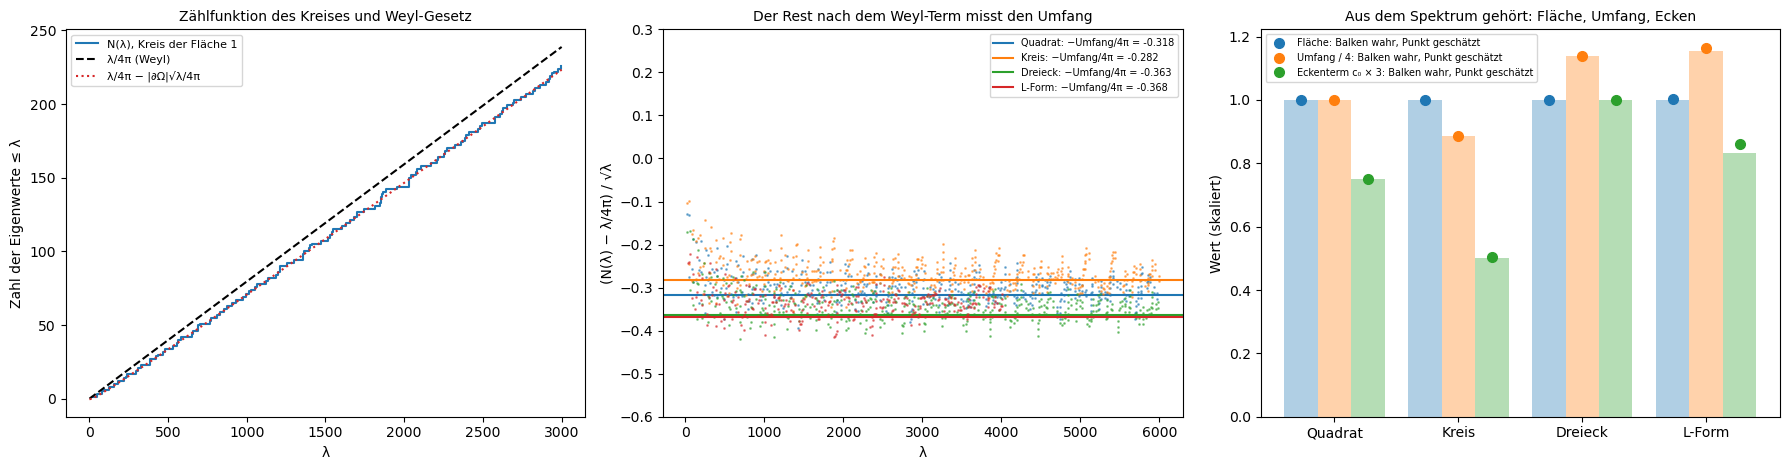

L-Form: 42721 Gitterpunkte, kleinster Eigenwert 28.9292 (Literatur für die L-Form aus Einheitsquadraten 9.6397, mal 3 = 28.919)
Form       Fläche (Fit / wahr)   Umfang (Fit / wahr)    c₀ (Fit / wahr)
Quadrat    1.0000 / 1.0000      4.0000 / 4.0000       0.2500 / 0.2500
Kreis      1.0000 / 1.0000      3.5453 / 3.5449       0.1681 / 0.1667
Dreieck    1.0000 / 1.0000      4.5590 / 4.5590       0.3333 / 0.3333
L-Form     1.0024 / 1.0000      4.6594 / 4.6188       0.2867 / 0.2778


In [12]:
M11 = 150
spectra = {"Quadrat": np.sort([np.pi ** 2 * (m * m + n * n) for m in range(1, M11) for n in range(1, M11)])}
r11 = 1 / np.sqrt(np.pi)
spectra["Kreis"] = np.sort(np.concatenate([jn_zeros(0, 160) ** 2] + [np.repeat(jn_zeros(m, 160) ** 2, 2) for m in range(1, 160)])) / r11 ** 2
a11 = np.sqrt(4 / np.sqrt(3))
spectra["Dreieck"] = np.sort([16 * np.pi ** 2 / (9 * a11 * a11) * (m * m + m * n + n * n) for m in range(1, M11) for n in range(1, M11)])
def lshape_eigs(n, k):
    s = 1 / np.sqrt(3); h = s / n; N = 2 * n
    inside = np.zeros((N + 1, N + 1), bool)
    inside[1:N, 1:N] = True
    inside[n:, n:] = False
    idx = -np.ones(inside.shape, int); idx[inside] = np.arange(inside.sum())
    rows, cols, vals = [], [], []
    for i, j in zip(*np.where(inside)):
        p = idx[i, j]
        rows.append(p); cols.append(p); vals.append(4 / h ** 2)
        for di, dj in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            q = idx[i + di, j + dj]
            if q >= 0:
                rows.append(p); cols.append(q); vals.append(-1 / h ** 2)
    A = sp.csr_matrix((vals, (rows, cols)))
    return np.sort(spla.eigsh(A, k=k, sigma=0, which="LM", return_eigenvectors=False)), A.shape[0]
spectra["L-Form"], nL = lshape_eigs(120, 300)
truth = {"Quadrat": (1, 4, 1 / 4), "Kreis": (1, 2 * np.sqrt(np.pi), 1 / 6), "Dreieck": (1, 3 * a11, 1 / 3), "L-Form": (1, 8 / np.sqrt(3), 5 / 18)}
fits = {}
for name, ev in spectra.items():
    lmax = ev[-1] if name == "L-Form" else 40000
    ts = np.linspace(8 / lmax, 25 / lmax, 40)
    Z = np.array([np.sum(np.exp(-ev * t)) for t in ts])
    X = np.c_[1 / (4 * np.pi * ts), -1 / (8 * np.sqrt(np.pi * ts)), np.ones_like(ts)]
    fits[name] = np.linalg.lstsq(X, Z, rcond=None)[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
lam_ax = np.linspace(1, 3000, 2000)
evk = spectra["Kreis"]
ax.step(evk[evk < 3000], np.arange(1, (evk < 3000).sum() + 1), where="post", color="C0", label="N(λ), Kreis der Fläche 1")
ax.plot(lam_ax, lam_ax / (4 * np.pi), "k--", label="λ/4π (Weyl)")
ax.plot(lam_ax, lam_ax / (4 * np.pi) - truth["Kreis"][1] * np.sqrt(lam_ax) / (4 * np.pi), "C3:", label="λ/4π − |∂Ω|√λ/4π")
ax.set_xlabel("λ"); ax.set_ylabel("Zahl der Eigenwerte ≤ λ")
ax.set_title("Zählfunktion des Kreises und Weyl-Gesetz", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for (name, ev), c in zip(spectra.items(), ("C0", "C1", "C2", "C3")):
    lam_s = ev[ev < (ev[-1] if name == "L-Form" else 6000)]
    rest = (np.arange(1, len(lam_s) + 1) - lam_s / (4 * np.pi)) / np.sqrt(lam_s)
    ax.plot(lam_s, rest, ".", ms=2, color=c, alpha=0.5)
    ax.axhline(-truth[name][1] / (4 * np.pi), color=c, lw=1.5, label=f"{name}: −Umfang/4π = {-truth[name][1] / (4 * np.pi):.3f}")
ax.set_ylim(-0.6, 0.3)
ax.set_xlabel("λ"); ax.set_ylabel("(N(λ) − λ/4π) / √λ")
ax.set_title("Der Rest nach dem Weyl-Term misst den Umfang", fontsize=10)
ax.legend(fontsize=7)
ax = axes[2]
names = list(spectra)
xb = np.arange(len(names))
for j, (lab, c) in enumerate(zip(("Fläche", "Umfang / 4", "Eckenterm c₀ × 3"), ("C0", "C1", "C2"))):
    scale = (1, 0.25, 3)[j]
    ax.bar(xb + (j - 1) * 0.27, [truth[n][j] * scale for n in names], 0.27, color=c, alpha=0.35)
    ax.plot(xb + (j - 1) * 0.27, [fits[n][j] * scale for n in names], "o", color=c, ms=7, label=f"{lab}: Balken wahr, Punkt geschätzt")
ax.set_xticks(xb, names)
ax.set_ylabel("Wert (skaliert)")
ax.set_title("Aus dem Spektrum gehört: Fläche, Umfang, Ecken", fontsize=10)
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

print(f"L-Form: {nL} Gitterpunkte, kleinster Eigenwert {spectra['L-Form'][0]:.4f} (Literatur für die L-Form aus Einheitsquadraten 9.6397, mal 3 = 28.919)")
print("Form       Fläche (Fit / wahr)   Umfang (Fit / wahr)    c₀ (Fit / wahr)")
for name in names:
    print(f"{name:9s}  {fits[name][0]:.4f} / {truth[name][0]:.4f}      {fits[name][1]:.4f} / {truth[name][1]:.4f}       {fits[name][2]:.4f} / {truth[name][2]:.4f}")

* **Links** folgt die Zählfunktion des Kreises nicht der Weyl-Geraden $\lambda/4\pi$ (gestrichelt), sondern der Kurve mit Randkorrektur (rot gepunktet), mit kleinen Schwankungen um sie. Der Abstand zur Geraden wächst wie $\sqrt\lambda$: Der Rand nimmt Eigenwerte weg.
* In der **Mitte** schwankt der Rest $(N(\lambda) - \lambda/4\pi)/\sqrt\lambda$ für jede Form um ihre eigene Linie $-\vert\partial\Omega\vert/4\pi$: Der Kreis hat den kleinsten Umfang und liegt am höchsten, Dreieck und L-Form am tiefsten. Schon an der Zählfunktion hört man also den Umfang, nur verrauscht.
* **Rechts** und laut **Ausgabe** gibt der Fit an die Wärmespur für Quadrat, Kreis und Dreieck Fläche, Umfang und Eckenterm auf drei bis vier Stellen zurück (Kreis: Umfang 3.5453 gegen 3.5449, $c_0 = 0.168$ gegen $\tfrac16$; Dreieck exakt $\tfrac13$). Für die L-Form aus finiten Differenzen sind es 1.0024, 4.659 gegen 4.619 und 0.287 gegen 0.278; die Abweichungen von 1 bis 3 % kommen vom Gitter, das die Eigenwerte leicht verschiebt. Das beantwortet die Vorhersage: Fläche, Umfang und die Ecken (über $c_0$, das bei einer glatten Form $\tfrac16$ wäre) sind hörbar. Der kleinste Eigenwert der L-Form ist 28.929, gegen 28.919 aus der Literatur.
* **Wo es vorkommt:** Das Weyl-Gesetz bestimmt die Modendichte von Resonatoren (Mikrowellen, Laser, Akustik von Räumen), die Plancksche Strahlungsformel (die Zahl der Moden im Hohlraum) und die Zustandsdichte von Elektronen in Festkörpern; die Wärmespur ist ein Werkzeug der Quantenfeldtheorie (Casimir-Effekt, Anomalien) und der Geometrie (Index-Satz). In der Datenanalyse benutzt man Spektren des Graph-Laplace-Operators, um Formen und Netzwerke zu vergleichen (Shape-DNA, spektrale Deskriptoren in der Computergrafik).

##### *12. Der Satz von Stone: unitäre Gruppen und ihre Erzeuger*

Was bedeutet es, dass der Impuls die Verschiebungen „erzeugt“, und warum ist das nur für glatte Funktionen eine Ableitung? Vorher vorhersagen: Wie schnell geht $\Vert\psi(\cdot - a) - \psi\Vert$ gegen 0, wenn $\psi$ eine Gauß-Funktion ist, und wie schnell, wenn $\psi$ ein Rechteck ist?

Links wird die Verschiebung $U(a)\psi = \psi(\cdot - a)$ für eine Gauß-Funktion und ein Rechteck gemessen, dazu die Operatornorm $\Vert U(a) - 1\Vert$, ausgewertet an der Testfunktion $\sin(\pi x/a)$ mit Gauß-Fenster. In der Mitte steht der Fehler des Differenzenquotienten $(U(a)\psi - \psi)/a + \psi'$, der für Funktionen im Definitionsbereich des Erzeugers gegen 0 gehen muss. Rechts wirkt eine andere unitäre Gruppe, $e^{-i\alpha H}$ mit dem harmonischen Oszillator $H = \tfrac12(p^2 + x^2)$ (512 Gitterpunkte, $p^2$ über die FFT), auf ein geglättetes Rechteck: die gebrochene Fourier-Transformation.

**Hintergrund & Fachbegriffe:**
- **Einparametrige unitäre Gruppe:** unitäre $U(t)$ mit $U(s + t) = U(s)U(t)$, $U(0) = 1$; **stark stetig:** $U(t)\psi\to\psi$ für jedes $\psi$; **normstetig:** $\Vert U(t) - 1\Vert\to0$.
- **Erzeuger:** $H\psi = i\frac{d}{dt}U(t)\psi\vert_{t=0}$, definiert für die $\psi$, für die der Grenzwert existiert.
- **Gebrochene Fourier-Transformation** $\mathcal F^\alpha = e^{-i\alpha(H - 1/2)}$: eine Drehung der Zeit-Frequenz-Ebene um den Winkel $\alpha$; $\alpha = \pi/2$ ist die Fourier-Transformation, $\alpha = \pi$ die Spiegelung $\psi(x)\mapsto\psi(-x)$.
- **Hermite-Funktionen:** die Eigenfunktionen des harmonischen Oszillators zu den Eigenwerten $n + \tfrac12$.

**Theorie:**

- **Satz von Stone:** Jede stark stetige unitäre Gruppe hat die Form $U(t) = e^{-iHt}$ mit genau einem selbstadjungierten $H$, und umgekehrt. Für die Verschiebungen ist $H = p = -i\frac{d}{dx}$; für die Zeitentwicklung der Hamilton-Operator, für Drehungen der Drehimpuls.
- **Stark, nicht normstetig:** Für glatte $\psi$ ist $\Vert U(a)\psi - \psi\Vert\approx a\Vert\psi'\Vert$, für ein Rechteck mit zwei Sprüngen $\sqrt{2a}$, also langsamer, aber immer noch gegen 0. Die Operatornorm $\Vert U(a) - 1\Vert$ ist dagegen für jedes $a\neq0$ gleich 2: Eine Funktion, die mit Periode $2a$ das Vorzeichen wechselt, wird durch die Verschiebung fast genau in $-\psi$ überführt. Deshalb ist $p$ unbeschränkt.
- **Definitionsbereich:** Der Differenzenquotient konvergiert genau für $\psi$ im Definitionsbereich von $p$ (hier im Sobolev-Raum $H^1$). Für das Rechteck wächst er wie $\sqrt{2/a}$: Das Rechteck liegt im Raum, auf dem die Gruppe wirkt, aber nicht im Definitionsbereich ihres Erzeugers.
- **Fourier als Zeitentwicklung:** Weil die Hermite-Funktionen Eigenfunktionen der Fourier-Transformation zu $(-i)^n$ sind, ist $\mathcal F = e^{-i\frac\pi2(H - \frac12)}$. Die gebrochene Transformation benutzt man in Optik (Lichtausbreitung in Gradientenindex-Medien), Radar und Signalverarbeitung für Chirps.

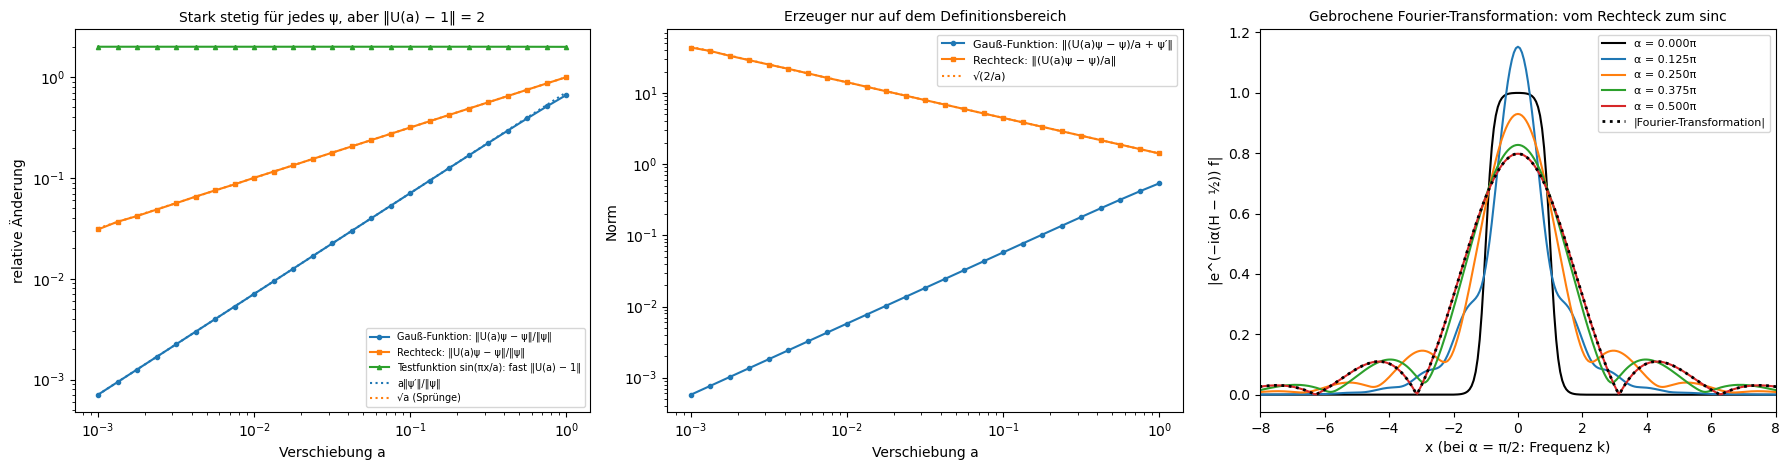

Oszillator auf dem Gitter: kleinste Eigenwerte [0.5, 1.5, 2.5, 3.5, 4.5], E₄₀ = 40.5000
e^(−iπ/2 (H − ½)) f gegen die Fourier-Transformation: größte Abweichung 4.5e-04;  α = π gibt f(−x): 1.2e-03
Verschiebung a = 1e-03: Gauß 7.07e-04, Rechteck 3.08e-02 (√a = 3.16e-02);  Testfunktion bei a = 0.01, 0.1, 1: [2.0, 1.9999, 1.9949]
Differenzenquotient bei a = 1e-03: Gauß-Fehler 5.76e-04, Rechteck 43.6 (√(2/a) = 44.7)


In [13]:
xs12 = np.linspace(-12, 12, 240001)
ws12 = np.full_like(xs12, xs12[1] - xs12[0]); ws12[[0, -1]] /= 2
gaussf = lambda x: np.exp(-x ** 2 / 2)
rectf = lambda x: ((x > -1) & (x < 1)).astype(float)
aa = np.logspace(-3, 0, 25)
shift_g = np.array([l2(gaussf(xs12 - a) - gaussf(xs12), ws12) for a in aa]) / l2(gaussf(xs12), ws12)
shift_r = np.array([l2(rectf(xs12 - a) - rectf(xs12), ws12) for a in aa]) / l2(rectf(xs12), ws12)
def osc_ratio(a):
    f = np.sin(np.pi * xs12 / a) * np.exp(-xs12 ** 2 / 50)
    return l2(np.sin(np.pi * (xs12 - a) / a) * np.exp(-(xs12 - a) ** 2 / 50) - f, ws12) / l2(f, ws12)
opn = np.array([osc_ratio(a) for a in aa])
dq_g = np.array([l2((gaussf(xs12 - a) - gaussf(xs12)) / a - xs12 * gaussf(xs12), ws12) for a in aa])     # −ψ' = x e^{−x²/2}
dq_r = np.array([l2((rectf(xs12 - a) - rectf(xs12)) / a, ws12) for a in aa])
N12, L12 = 512, 16
xg12 = np.linspace(-L12, L12, N12, endpoint=False); h12 = xg12[1] - xg12[0]
kg12 = 2 * np.pi * np.fft.fftfreq(N12, h12)
T12 = np.real(np.fft.ifft(kg12[:, None] ** 2 * np.fft.fft(np.eye(N12), axis=0), axis=0)) / 2
H12 = (T12 + T12.T) / 2 + np.diag(xg12 ** 2) / 2
E12, V12 = eigh(H12)
frft = lambda al, f: (V12 * np.exp(-1j * al * (E12 - 0.5))) @ (V12.T @ f)
f12 = 0.5 * (np.tanh(4 * (xg12 + 1)) - np.tanh(4 * (xg12 - 1)))
F12 = np.array([np.sum(f12 * np.exp(-1j * k * xg12)) * h12 / np.sqrt(2 * np.pi) for k in xg12])     # Fourier-Transformation an den Stellen k = x

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.loglog(aa, shift_g, "o-", ms=3, label="Gauß-Funktion: ‖U(a)ψ − ψ‖/‖ψ‖")
ax.loglog(aa, shift_r, "s-", ms=3, label="Rechteck: ‖U(a)ψ − ψ‖/‖ψ‖")
ax.loglog(aa, opn, "^-", ms=3, label="Testfunktion sin(πx/a): fast ‖U(a) − 1‖")
ax.loglog(aa, aa * l2(xs12 * gaussf(xs12), ws12) / l2(gaussf(xs12), ws12), "C0:", label="a‖ψ′‖/‖ψ‖")
ax.loglog(aa, np.sqrt(aa), "C1:", label="√a (Sprünge)")
ax.set_xlabel("Verschiebung a")
ax.set_ylabel("relative Änderung")
ax.set_title("Stark stetig für jedes ψ, aber ‖U(a) − 1‖ = 2", fontsize=10)
ax.legend(fontsize=7)
ax = axes[1]
ax.loglog(aa, dq_g, "o-", ms=3, label="Gauß-Funktion: ‖(U(a)ψ − ψ)/a + ψ′‖")
ax.loglog(aa, dq_r, "s-", ms=3, label="Rechteck: ‖(U(a)ψ − ψ)/a‖")
ax.loglog(aa, np.sqrt(2 / aa), "C1:", label="√(2/a)")
ax.set_xlabel("Verschiebung a")
ax.set_ylabel("Norm")
ax.set_title("Erzeuger nur auf dem Definitionsbereich", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
for al, c in zip((0, np.pi / 8, np.pi / 4, 3 * np.pi / 8, np.pi / 2), ("k", "C0", "C1", "C2", "C3")):
    ax.plot(xg12, np.abs(frft(al, f12)), color=c, label=f"α = {al / np.pi:.3f}π")
ax.plot(xg12, np.abs(F12), "k:", lw=2, label="|Fourier-Transformation|")
ax.set_xlim(-8, 8)
ax.set_xlabel("x (bei α = π/2: Frequenz k)")
ax.set_ylabel("|e^(−iα(H − ½)) f|")
ax.set_title("Gebrochene Fourier-Transformation: vom Rechteck zum sinc", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

g_half = frft(np.pi / 2, f12)
print(f"Oszillator auf dem Gitter: kleinste Eigenwerte {np.round(E12[:5], 6).tolist()}, E₄₀ = {E12[40]:.4f}")
print(f"e^(−iπ/2 (H − ½)) f gegen die Fourier-Transformation: größte Abweichung {np.abs(g_half - F12).max():.1e};  α = π gibt f(−x): {np.abs(frft(np.pi, f12) - f12[(-np.arange(N12)) % N12]).max():.1e}")
print(f"Verschiebung a = {aa[0]:.0e}: Gauß {shift_g[0]:.2e}, Rechteck {shift_r[0]:.2e} (√a = {np.sqrt(aa[0]):.2e});  Testfunktion bei a = 0.01, 0.1, 1: {np.round(opn[[8, 16, -1]], 4).tolist()}")
print(f"Differenzenquotient bei a = {aa[0]:.0e}: Gauß-Fehler {dq_g[0]:.2e}, Rechteck {dq_r[0]:.1f} (√(2/a) = {np.sqrt(2 / aa[0]):.1f})")

* **Links** (beide Achsen logarithmisch) geht $\Vert U(a)\psi - \psi\Vert$ für die Gauß-Funktion linear gegen 0 (laut **Ausgabe** $7.1\cdot10^{-4}$ bei $a = 10^{-3}$), für das Rechteck wie $\sqrt a$ ($3.08\cdot10^{-2}$ gegen $\sqrt a = 3.16\cdot10^{-2}$). Das beantwortet die Vorhersage. Beide gehen gegen 0: Die Gruppe ist stark stetig. Für die oszillierende Testfunktion ist die relative Änderung dagegen bei jedem $a$ gleich 2.0: $\Vert U(a) - 1\Vert = 2$, keine Normstetigkeit.
* In der **Mitte** geht der Fehler des Differenzenquotienten für die Gauß-Funktion wie $a$ gegen 0 ($5.8\cdot10^{-4}$), die Ableitung existiert. Für das Rechteck wächst der Differenzenquotient wie $\sqrt{2/a}$ (43.6 gegen 44.7 bei $a = 10^{-3}$): Das Rechteck liegt nicht im Definitionsbereich des Impulses.
* **Rechts** verwandelt die Oszillator-Gruppe das geglättete Rechteck schrittweise in seine Fourier-Transformation; bei $\alpha = \pi/2$ liegt die Kurve auf $\vert\hat f\vert$ (laut Ausgabe Abweichung $4.5\cdot10^{-4}$, Phase $e^{-i\pi/4}$ schon im Ansatz $H - \tfrac12$ berücksichtigt). Zwischendurch entstehen Überschwinger wie bei der Fresnel-Beugung. Die Eigenwerte des diskretisierten Oszillators sind laut Ausgabe genau $n + \tfrac12$, und $\alpha = \pi$ gibt $f(-x)$.
* **Wo es vorkommt:** Der Satz von Stone ist die mathematische Form von „der Hamilton-Operator erzeugt die Zeitentwicklung, der Impuls die Verschiebung, der Drehimpuls die Drehung“; er garantiert, dass jede selbstadjungierte Quantenmechanik eine unitäre Zeitentwicklung hat. Halbgruppen (die nicht unitäre Verallgemeinerung, Hille-Yosida) beschreiben Wärmeleitung, Markov-Prozesse und offene Quantensysteme. Die gebrochene Fourier-Transformation benutzt man in der Optik (Ausbreitung in Gradientenindex-Fasern), in der Radar- und Sonar-Signalverarbeitung für Chirps und in der Zeit-Frequenz-Analyse.

##### *13. Stone-von Neumann: [x, p] = i lässt sich nicht mit Matrizen darstellen*

Warum gibt es keine endlichen Matrizen $x$, $p$ mit $[x, p] = i$, und was passiert, wenn man es mit abgeschnittenen Matrizen trotzdem versucht? Vorher vorhersagen: Was steht auf der Diagonale von $[x_N, p_N]$, wenn man Ort und Impuls in den ersten $N$ Zuständen des harmonischen Oszillators abschneidet?

Mit dem abgeschnittenen Vernichter $a_N$ ($N\times N$) sind $x_N = (a_N + a_N^\dagger)/\sqrt2$ und $p_N = (a_N - a_N^\dagger)/(i\sqrt2)$. Links steht die Diagonale von $[x_N, p_N]/i$ für $N = 10$. In der Mitte wird die Weyl-Relation $D(\alpha)D(\beta) = e^{i\,\mathrm{Im}(\alpha\bar\beta)}D(\alpha + \beta)$ der Verschiebungsoperatoren $D(\alpha) = e^{\alpha a^\dagger - \bar\alpha a}$ auf dem Vakuum geprüft, für $\alpha = r$, $\beta = ir$ und $N = 20$, 40, 80. Rechts stehen die Eigenwerte von $x_N$ für $N = 200$ als Histogramm. Die Ausgabe prüft außerdem die Eindeutigkeit endlicher Weyl-Paare.

**Hintergrund & Fachbegriffe:**
- **Kanonische Vertauschungsrelation** (CCR): $[x, p] = i$ (mit $\hbar = 1$); **Weyl-Form:** $e^{-iap}e^{-ibx} = e^{iab}e^{-ibx}e^{-iap}$, dieselbe Aussage für die beschränkten unitären Gruppen.
- **Vernichter und Erzeuger:** $a\vert n\rangle = \sqrt n\vert n - 1\rangle$, $a^\dagger\vert n\rangle = \sqrt{n + 1}\vert n + 1\rangle$, $[a, a^\dagger] = 1$.
- **Verschiebungsoperator** $D(\alpha)$: verschiebt einen Zustand im Phasenraum um $\alpha$; $D(\alpha)\vert0\rangle$ ist ein kohärenter Zustand.
- **Takt- und Schiebematrix** (clock and shift): $Z = \mathrm{diag}(1, \omega, \omega^2, \dots)$, $X\vert k\rangle = \vert k + 1\rangle$ mit $\omega = e^{2\pi i/N}$; sie erfüllen $ZX = \omega XZ$, die endliche Weyl-Relation.

**Theorie:**

- **Spur-Argument:** Für $N\times N$-Matrizen ist $\mathrm{tr}[x, p] = \mathrm{tr}(xp) - \mathrm{tr}(px) = 0$, aber $\mathrm{tr}(i\cdot1) = iN$. Also muss mindestens einer der Operatoren unbeschränkt sein (Wintner, Wielandt). Abgeschnitten ist $[a_N, a_N^\dagger] = \mathrm{diag}(1, \dots, 1, -(N - 1))$: richtig bis auf den letzten Zustand, der die ganze Spur ausgleicht.
- **Stone-von Neumann:** Die Weyl-Relation hat bis auf unitäre Äquivalenz nur eine irreduzible Lösung, die Schrödinger-Darstellung auf $L^2(\mathbb R)$. Die Weyl-Form ist nötig: Es gibt pathologische Paare, die $[x, p] = i$ auf einem dichten Teilraum erfüllen und trotzdem nicht äquivalent sind. In endlicher Dimension gilt dasselbe für Takt und Schiebung: Jedes Paar unitärer $U, V$ mit $UV = \omega VU$ und $U^N = V^N = 1$ ist unitär äquivalent zu $(X, Z)$.
- **Abschneiden:** Kohärente Zustände mit $\vert\alpha\vert^2\ll N$ werden richtig dargestellt, größere „spüren“ den Rand. Die Eigenwerte von $x_N$ sind die Nullstellen des Hermite-Polynoms $H_N$ (die Knoten der Gauß-Hermite-Quadratur), verteilt wie ein Halbkreis auf $[-\sqrt{2N}, \sqrt{2N}]$: eine endliche Matrix ahmt das kontinuierliche Spektrum $\mathbb R$ durch $N$ immer dichtere Punkte nach.

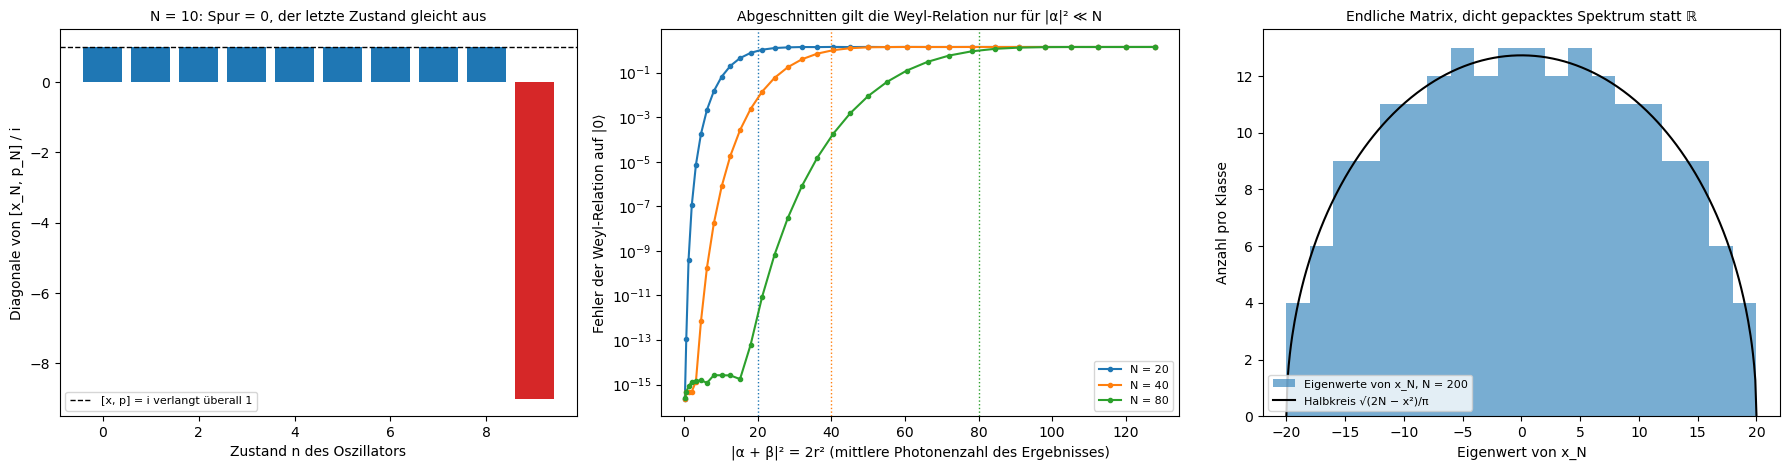

Diagonale von [x₁₀, p₁₀]/i: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, -9.0], Spur 0.0e+00
N = 20: Weyl-Relation auf |0⟩ besser als 1e-6 bis 2r² = 2.0, Fehler bei 2r² = 128: 1.417
N = 40: Weyl-Relation auf |0⟩ besser als 1e-6 bis 2r² = 10.1, Fehler bei 2r² = 128: 1.414
N = 80: Weyl-Relation auf |0⟩ besser als 1e-6 bis 2r² = 32.0, Fehler bei 2r² = 128: 1.414
Eigenwerte von x_N (N = 200) gleich den Hermite-Nullstellen (Gauß-Hermite-Knoten): 6.4e-14;  größter 19.339, √(2N) = 20.000
Endliches Weyl-Paar (N = 12), zufällig gedreht: VU = ωUV bis auf 4.4e-16;  rekonstruierte Verflechtung S mit S U S† = X, S V S† = Z: Fehler 6.8e-15


In [14]:
def ladder(N):
    return np.diag(np.sqrt(np.arange(1, N)), 1)
a10 = ladder(10)
x10 = (a10 + a10.T) / np.sqrt(2); p10 = (a10 - a10.T) / (1j * np.sqrt(2))
comm10 = np.diag(x10 @ p10 - p10 @ x10) / 1j
rs = np.linspace(0.25, 8, 32)
weyl = {}
for N in (20, 40, 80):
    a = ladder(N)
    D = lambda al: expm(al * a.T - np.conj(al) * a)
    vac = np.zeros(N); vac[0] = 1
    weyl[N] = np.array([np.linalg.norm(D(r) @ D(1j * r) @ vac - np.exp(1j * np.imag(r * np.conj(1j * r))) * D(r + 1j * r) @ vac) for r in rs])
N60 = 200
a60 = ladder(N60)
ex60 = np.linalg.eigvalsh((a60 + a60.T) / np.sqrt(2))
herm_nodes = np.polynomial.hermite.hermgauss(N60)[0]
Nw = 12
om = np.exp(2j * np.pi / Nw)
Xs = np.roll(np.eye(Nw), 1, axis=0); Zc = np.diag(om ** np.arange(Nw))
rng = np.random.default_rng(13)
Q_, R_ = np.linalg.qr(rng.normal(size=(Nw, Nw)) + 1j * rng.normal(size=(Nw, Nw)))
Wr = Q_ * (np.diag(R_) / np.abs(np.diag(R_)))
U13, V13 = Wr @ Xs @ Wr.conj().T, Wr @ Zc @ Wr.conj().T
evV, vecV = np.linalg.eig(V13)
v0 = vecV[:, np.argmin(np.abs(evV - 1))]
v0 = v0 / np.linalg.norm(v0)
basis = [v0]
for _ in range(Nw - 1):
    basis.append(U13 @ basis[-1])
S13 = np.array(basis).conj()                                 # Zeilen: Basisvektoren, S U S† = Schiebung, S V S† = Takt
inter_err = max(np.abs(S13 @ U13 @ S13.conj().T - Xs).max(), np.abs(S13 @ V13 @ S13.conj().T - Zc).max())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.bar(np.arange(10), np.real(comm10), color=["C0"] * 9 + ["C3"])
ax.axhline(1, color="k", ls="--", lw=1, label="[x, p] = i verlangt überall 1")
ax.set_xlabel("Zustand n des Oszillators")
ax.set_ylabel("Diagonale von [x_N, p_N] / i")
ax.set_title(f"N = 10: Spur = {np.real(comm10).sum():.0f}, der letzte Zustand gleicht aus", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for N, c in zip(weyl, ("C0", "C1", "C2")):
    ax.semilogy(rs ** 2 * 2, weyl[N] + 1e-17, "o-", ms=3, color=c, label=f"N = {N}")
    ax.axvline(N, color=c, ls=":", lw=1)
ax.set_xlabel("|α + β|² = 2r² (mittlere Photonenzahl des Ergebnisses)")
ax.set_ylabel("Fehler der Weyl-Relation auf |0⟩")
ax.set_title("Abgeschnitten gilt die Weyl-Relation nur für |α|² ≪ N", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
xx13 = np.linspace(-np.sqrt(2 * N60), np.sqrt(2 * N60), 400)
ax.hist(ex60, bins=np.linspace(-np.sqrt(2 * N60), np.sqrt(2 * N60), 21), alpha=0.6, label=f"Eigenwerte von x_N, N = {N60}")
ax.plot(xx13, np.sqrt(2 * N60 - xx13 ** 2) / np.pi * (2 * np.sqrt(2 * N60) / 20), "k-", label="Halbkreis √(2N − x²)/π")
ax.set_xlabel("Eigenwert von x_N")
ax.set_ylabel("Anzahl pro Klasse")
ax.set_title("Endliche Matrix, dicht gepacktes Spektrum statt ℝ", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Diagonale von [x₁₀, p₁₀]/i: {np.round(np.real(comm10), 6).tolist()}, Spur {np.real(comm10).sum():.1e}")
for N, e in weyl.items():
    ok = rs[e < 1e-6]
    print(f"N = {N}: Weyl-Relation auf |0⟩ besser als 1e-6 bis 2r² = {2 * ok.max() ** 2:.1f}, Fehler bei 2r² = 128: {e[-1]:.3f}")
print(f"Eigenwerte von x_N (N = {N60}) gleich den Hermite-Nullstellen (Gauß-Hermite-Knoten): {np.abs(np.sort(ex60) - np.sort(herm_nodes)).max():.1e};  größter {ex60.max():.3f}, √(2N) = {np.sqrt(2 * N60):.3f}")
print(f"Endliches Weyl-Paar (N = 12), zufällig gedreht: VU = ωUV bis auf {np.abs(V13 @ U13 - om * U13 @ V13).max():.1e};  "
      f"rekonstruierte Verflechtung S mit S U S† = X, S V S† = Z: Fehler {inter_err:.1e}")

* **Links** ist die Diagonale von $[x_N, p_N]/i$ für $N = 10$ laut **Ausgabe** neunmal 1 und einmal $-9$, die Spur 0. Das beantwortet die Vorhersage: Die Vertauschungsrelation gilt auf allen Zuständen außer dem obersten, der die Spur ausgleicht. Mit Matrizen geht es nicht anders.
* In der **Mitte** (logarithmische Achse) ist der Fehler der Weyl-Relation auf dem Vakuum winzig, solange die mittlere Photonenzahl $2r^2$ klein gegen $N$ ist, und steigt dann steil auf etwa $\sqrt2$, den Abstand zweier zueinander senkrechter Einheitsvektoren. Laut Ausgabe bleibt er unter $10^{-6}$ bis $2r^2 = 2.0$, 10.1 und 32.0 für $N = 20$, 40 und 80; die gepunkteten Linien markieren $2r^2 = N$.
* **Rechts** füllen die 200 Eigenwerte von $x_N$ das Intervall $[-\sqrt{2N}, \sqrt{2N}] = [-20, 20]$ mit der Halbkreis-Dichte. Laut Ausgabe sind sie bis auf $6\cdot10^{-14}$ die Nullstellen des Hermite-Polynoms $H_{200}$, der größte ist 19.34. Eine endliche Matrix kann das kontinuierliche Spektrum $\mathbb R$ des Ortsoperators nur durch immer mehr, immer dichtere Punkte in einem wachsenden Intervall ersetzen. Für das endliche Weyl-Paar findet der Code die Verflechtung mit Takt und Schiebung bis auf $7\cdot10^{-15}$: Stone-von Neumann in endlicher Dimension.
* **Wo es vorkommt:** Jede Simulation bosonischer Systeme (Photonen in Resonatoren, Phononen, bosonische Quantencodes wie GKP- und Katzen-Codes) schneidet den Fock-Raum ab und muss prüfen, dass die Zustände weit unter $N$ bleiben. Gauß-Hermite-Quadratur benutzt die Eigenwerte von $x_N$ als Stützstellen. Takt und Schiebung sind die Pauli-Operatoren von Qudits und die Grundlage der Weyl-Heisenberg-Gruppe in Fehlerkorrektur und Tomographie; Stone-von Neumann begründet, dass Orts-, Impuls- und Fock-Darstellung dieselbe Physik beschreiben.

##### *14. Der Koopman-Operator: nichtlineare Dynamik als lineare Abbildung*

Kann man eine nichtlineare Bewegung mit linearer Algebra vorhersagen? Vorher vorhersagen: Für $\dot x_1 = \mu x_1$, $\dot x_2 = \lambda(x_2 - x_1^2)$ mit $\mu = -0.05$, $\lambda = -1$: Welche Zerfallsraten findet ein lineares Modell, das nur $x_1$ und $x_2$ kennt, und welche eines, das zusätzlich $x_1^2$ beobachtet?

Aus 30 Trajektorien (Schrittweite 0.1, je 100 Schritte) werden zwei lineare Modelle durch kleinste Quadrate gelernt: die Dynamic Mode Decomposition (DMD) mit den Beobachtungen $(x_1, x_2)$ und die erweiterte DMD (EDMD) mit $(x_1, x_2, x_1^2)$. Links steht das Phasenporträt mit der langsamen Mannigfaltigkeit, in der Mitte stehen die Eigenwerte der beiden Modelle als Raten $\log(\text{Eigenwert})/\Delta t$, rechts die Vorhersage einer neuen Trajektorie.

**Hintergrund & Fachbegriffe:**
- **Koopman-Operator** $\mathcal K^tg = g\circ\Phi^t$: Er bildet eine Beobachtungsgröße $g$ (eine Funktion auf dem Zustandsraum) auf ihren Wert nach der Zeit $t$ ab. Er ist linear, auch wenn der Fluss $\Phi^t$ nichtlinear ist, wirkt aber auf einem unendlichdimensionalen Funktionenraum.
- **Koopman-Eigenfunktion:** $\mathcal K^t\varphi = e^{\nu t}\varphi$; entlang jeder Trajektorie wächst oder zerfällt sie exakt exponentiell.
- **Invarianter Unterraum:** ein endlicher Satz von Beobachtungen, der unter $\mathcal K^t$ in sich abgebildet wird; dann ist die Dynamik darauf exakt eine Matrix.
- **DMD und EDMD:** die beste lineare Abbildung $Y\approx AX$ zwischen aufeinanderfolgenden Messungen (DMD) bzw. zwischen Funktionen der Messungen aus einem Wörterbuch (EDMD).

**Theorie:**

- **Exakte Linearisierung:** Mit $y_3 = x_1^2$ gilt $\dot y_3 = 2\mu y_3$ und $\dot x_2 = \lambda x_2 - \lambda y_3$. Die drei Beobachtungen $(x_1, x_2, x_1^2)$ spannen einen invarianten Unterraum auf, und die Dynamik darauf ist linear mit den Eigenwerten $\mu$, $\lambda$, $2\mu$ (Brunton et al. 2016). Die nichtlineare Bewegung ist also ein linearer Operator auf einem größeren Raum.
- **DMD auf den Zuständen allein** sieht keinen invarianten Unterraum und findet einen Kompromiss: falsche Raten und schlechte Vorhersagen.
- **Spektrum des Koopman-Operators:** Bei maßerhaltender Dynamik ist er unitär auf $L^2$; seine Eigenwerte zeigen periodische Anteile, ein kontinuierliches Spektrum zeigt Chaos (Mischung). Damit wird Spektraltheorie zu einem Werkzeug der Datenanalyse.

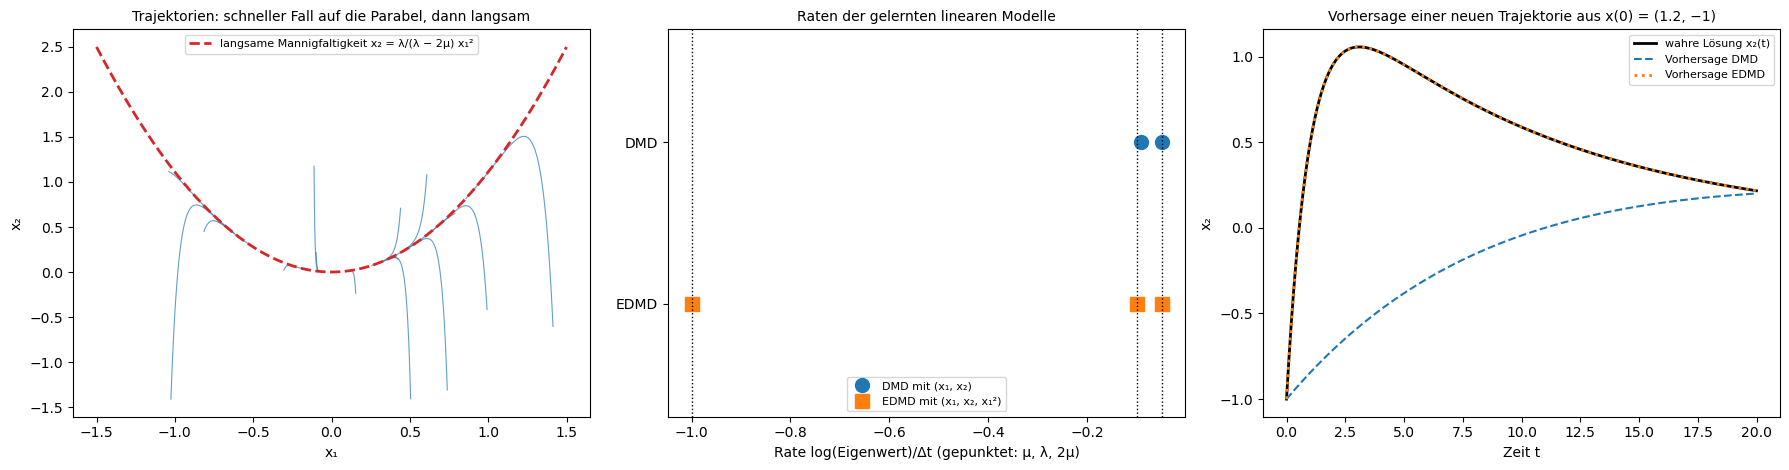

Raten DMD: [-0.0905, -0.05];  EDMD: [-1.0, -0.1, -0.05];  exakt: [-1.0, -0.1, -0.05]
Vorhersagefehler max |x₂| über t ∈ [0, 20]: DMD 1.681, EDMD 1.1e-10
EDMD-Matrix (gerundet):
[[0.995  0.     0.    ]
 [0.     0.9048 0.0947]
 [0.     0.     0.99  ]]


In [15]:
mu14, la14 = -0.05, -1.0
flow14 = lambda t, z: [mu14 * z[0], la14 * (z[1] - z[0] ** 2)]
dt14 = 0.1
rng = np.random.default_rng(14)
Xd, Yd, trajs = [], [], []
for _ in range(30):
    sol = solve_ivp(flow14, (0, 10), rng.uniform(-1.5, 1.5, 2), t_eval=np.arange(0, 10 + 1e-9, dt14), rtol=1e-10, atol=1e-12).y
    trajs.append(sol); Xd.append(sol[:, :-1]); Yd.append(sol[:, 1:])
Xd, Yd = np.hstack(Xd), np.hstack(Yd)
A_dmd = Yd @ np.linalg.pinv(Xd)
lift = lambda Z: np.vstack([Z[0], Z[1], Z[0] ** 2])
K_edmd = lift(Yd) @ np.linalg.pinv(lift(Xd))
rate = lambda M: np.sort(np.log(np.linalg.eigvals(M).astype(complex)).real / dt14)
z_test = np.array([1.2, -1.0])
t_test = np.arange(0, 20 + 1e-9, dt14)
truth14 = solve_ivp(flow14, (0, 20), z_test, t_eval=t_test, rtol=1e-10, atol=1e-12).y
pred_dmd = np.array([np.linalg.matrix_power(A_dmd, k) @ z_test for k in range(len(t_test))]).T
pred_edmd = np.array([np.linalg.matrix_power(K_edmd, k) @ lift(z_test[:, None])[:, 0] for k in range(len(t_test))]).T[:2]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
for tr in trajs[:15]:
    ax.plot(tr[0], tr[1], "C0-", lw=0.8, alpha=0.7)
xs14 = np.linspace(-1.5, 1.5, 200)
ax.plot(xs14, la14 / (la14 - 2 * mu14) * xs14 ** 2, "C3--", lw=2, label="langsame Mannigfaltigkeit x₂ = λ/(λ − 2μ) x₁²")
ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
ax.set_title("Trajektorien: schneller Fall auf die Parabel, dann langsam", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(rate(A_dmd), np.full(2, 1), "o", ms=10, label="DMD mit (x₁, x₂)")
ax.plot(rate(K_edmd), np.full(3, 0), "s", ms=10, label="EDMD mit (x₁, x₂, x₁²)")
for v in (mu14, la14, 2 * mu14):
    ax.axvline(v, color="k", ls=":", lw=1)
ax.set_yticks([0, 1], ["EDMD", "DMD"]); ax.set_ylim(-0.7, 1.7)
ax.set_xlabel("Rate log(Eigenwert)/Δt (gepunktet: μ, λ, 2μ)")
ax.set_title("Raten der gelernten linearen Modelle", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.plot(t_test, truth14[1], "k-", lw=2, label="wahre Lösung x₂(t)")
ax.plot(t_test, pred_dmd[1], "C0--", label="Vorhersage DMD")
ax.plot(t_test, pred_edmd[1], "C1:", lw=2, label="Vorhersage EDMD")
ax.set_xlabel("Zeit t"); ax.set_ylabel("x₂")
ax.set_title("Vorhersage einer neuen Trajektorie aus x(0) = (1.2, −1)", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Raten DMD: {np.round(rate(A_dmd), 4).tolist()};  EDMD: {np.round(rate(K_edmd), 6).tolist()};  exakt: {sorted([mu14, la14, 2 * mu14])}")
print(f"Vorhersagefehler max |x₂| über t ∈ [0, 20]: DMD {np.abs(pred_dmd[1] - truth14[1]).max():.3f}, EDMD {np.abs(pred_edmd[1] - truth14[1]).max():.1e}")
print(f"EDMD-Matrix (gerundet):\n{np.round(K_edmd, 4)}")

* **Links** fallen die Trajektorien schnell (Rate $\lambda = -1$) auf die Parabel $x_2 = \frac{\lambda}{\lambda - 2\mu}x_1^2$ und wandern dann langsam (Rate $\mu = -0.05$) zum Ursprung: eine nichtlineare Dynamik mit zwei Zeitskalen.
* In der **Mitte** findet die DMD auf $(x_1, x_2)$ laut **Ausgabe** die Raten $-0.0905$ und $-0.05$: Die langsame Rate stimmt, die schnelle Rate $-1$ fehlt ganz und wird durch einen falschen Mischwert ersetzt. Die EDMD mit $x_1^2$ findet $-1$, $-0.1$, $-0.05$ exakt, also $\lambda$, $2\mu$ und $\mu$. Das beantwortet die Vorhersage. Die gelernte Matrix ist dreiecksförmig, wie die Theorie verlangt: $x_1^2$ treibt $x_2$, aber nicht umgekehrt.
* **Rechts** sagt die EDMD die neue Trajektorie über 20 Zeiteinheiten mit einem Fehler von $10^{-10}$ voraus, die DMD liegt um bis zu 1.68 daneben: Sie sieht den Anstieg von $x_2$ am Anfang nicht, weil der von $x_1^2$ kommt.
* **Wo es vorkommt:** Dynamic Mode Decomposition (Schmid 2010) ist ein Standardwerkzeug der Strömungsmechanik (kohärente Strukturen in Wirbelstraßen und Turbulenz aus Messdaten) und wird in Klimadaten, Epidemiologie, Stromnetzen, Neurowissenschaften und Videoanalyse benutzt. Koopman-Autoencoder lernen das Wörterbuch mit neuronalen Netzen, und modellprädiktive Regelung auf Koopman-Modellen macht nichtlineare Systeme mit linearen Methoden regelbar. PyDMD bietet viele Varianten.

##### *15. Operator-Lernen: eine Abbildung zwischen Funktionsräumen aus Beispielen*

Wie lernt man den Lösungsoperator einer Differentialgleichung aus Daten, so dass er auf jedem Gitter funktioniert? Vorher vorhersagen: Wie viele Beispielpaare braucht ein Modell, das den Operator als Multiplikation im Fourier-Raum ansetzt, im Vergleich zu einem Modell mit einer vollen $64\times64$-Matrix?

Der Operator ist die Wärmeleitung auf dem Kreis $[0, 2\pi)$ bis zur Zeit $T = 0.05$: $f\mapsto u = e^{T\Delta}f$. Die Eingaben sind zufällige glatte Funktionen (20 Fourier-Moden mit abfallenden Amplituden), die Ausgaben sind mit Rauschen der Stärke $10^{-3}$ versehen. Zwei Modelle werden aus $n$ Paaren auf einem Gitter mit 64 Punkten gelernt: ein **Fourier-Multiplikator** (eine Zahl pro Frequenz, der lineare Kern einer Schicht eines Fourier Neural Operators) und eine **volle Matrix** (kleinste Quadrate mit kleiner Regularisierung). Links steht der gelernte Multiplikator mit dem exakten $e^{-k^2T}$, in der Mitte die Vorhersage für eine neue Eingabe auf einem feineren Gitter mit 256 Punkten, rechts der Testfehler gegen $n$.

**Hintergrund & Fachbegriffe:**
- **Lösungsoperator:** die Abbildung von den Daten einer Gleichung (Anfangswert, Quelle, Koeffizient) auf ihre Lösung; eine Abbildung zwischen Funktionsräumen.
- **Fourier-Multiplikator:** ein Operator, der jede Frequenz $k$ mit einer Zahl $m(k)$ multipliziert; genau die verschiebungsinvarianten beschränkten Operatoren auf dem Kreis sind von dieser Art.
- **Fourier Neural Operator (FNO):** ein neuronales Netz aus Schichten $v\mapsto\sigma(Wv + \mathcal F^{-1}(R\cdot\mathcal Fv))$ mit gelernten Multiplikatoren $R$ für die niedrigen Frequenzen und einer punktweisen Nichtlinearität $\sigma$ (Li et al. 2021).
- **Diskretisierungsinvarianz:** Ein Modell, das auf Frequenzen statt auf Gitterpunkten definiert ist, lässt sich auf jedem Gitter auswerten.
- **Induktive Verzerrung:** eine Annahme, die in die Modellklasse eingebaut ist, hier die Verschiebungsinvarianz.

**Theorie:**

- **Verschiebungsinvariant heißt diagonal in der Fourier-Basis:** Vertauscht ein Operator mit allen Verschiebungen, dann sind die $e^{ikx}$ seine Eigenfunktionen (sie sind die Eigenfunktionen der Verschiebungen, und vertauschende Operatoren haben gemeinsame Eigenvektoren). Er ist ein Multiplikator, hier $m(k) = e^{-k^2T}$: ein kompakter Operator, dessen Eigenwerte schnell gegen 0 gehen.
- **Stichprobenbedarf:** Der Multiplikator hat pro Frequenz einen Parameter; jedes Beispiel liefert für jede Frequenz eine Gleichung. Die volle Matrix hat $64^2 = 4096$ Parameter und kennt den Operator erst, wenn die Eingaben den ganzen Eingaberaum aufspannen, hier 40 Dimensionen (Sinus und Kosinus für 20 Frequenzen). Mit der richtigen Struktur lernt man aus wenigen Beispielen, und das Ergebnis lässt sich auf jedes Gitter übertragen.
- **Grenzen:** Nichtlineare Operatoren (Navier-Stokes, Burgers) sind keine Multiplikatoren; FNOs kombinieren deshalb Multiplikatoren mit Nichtlinearitäten und mehreren Schichten. Der lineare Teil bleibt Funktionalanalysis.

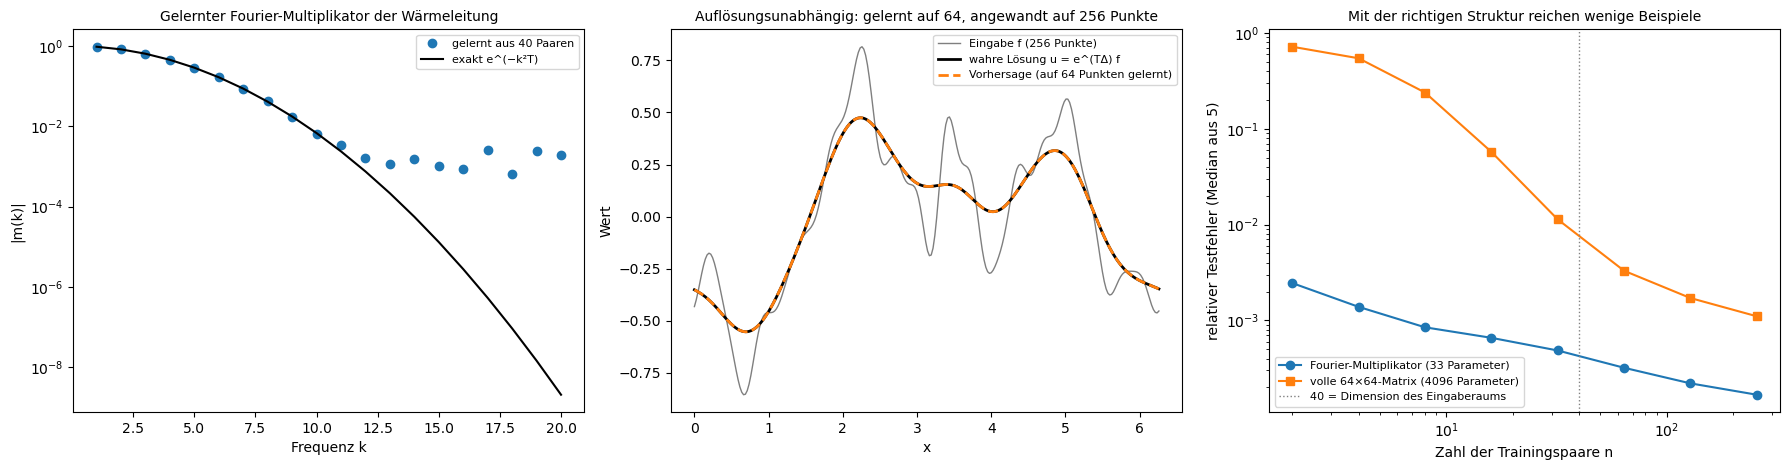

Multiplikator k = 1 … 5: [0.9513, 0.8187, 0.6375, 0.4491, 0.2866];  exakt [0.9512, 0.8187, 0.6376, 0.4493, 0.2865]
Fehler auf dem feinen Gitter (256 Punkte): 4.04e-04
Testfehler Multiplikator / Matrix: n = 2: 2.5e-03 / 7.2e-01, n = 4: 1.4e-03 / 5.5e-01, n = 8: 8.5e-04 / 2.4e-01, n = 16: 6.6e-04 / 5.8e-02, n = 32: 4.9e-04 / 1.1e-02, n = 64: 3.2e-04 / 3.3e-03, n = 128: 2.2e-04 / 1.7e-03, n = 256: 1.7e-04 / 1.1e-03


In [16]:
T15, kmax15 = 0.05, 20
ks15 = np.arange(1, kmax15 + 1)
rng = np.random.default_rng(15)
def heat_pairs(n, N):
    c = (rng.normal(size=(n, kmax15)) + 1j * rng.normal(size=(n, kmax15))) / (1 + ks15) ** 1.5
    xs = 2 * np.pi * np.arange(N) / N
    basis = np.exp(1j * np.outer(ks15, xs))
    return np.real(c @ basis), np.real((c * np.exp(-ks15 ** 2 * T15)) @ basis)
def fit_multiplier(F, U):
    Fh, Uh = np.fft.rfft(F, axis=1), np.fft.rfft(U, axis=1)
    return np.array([np.vdot(Fh[:, k], Uh[:, k]) / max(np.vdot(Fh[:, k], Fh[:, k]).real, 1e-30) for k in range(Fh.shape[1])])
def apply_multiplier(m, F):
    N = F.shape[1]
    mm = np.zeros(N // 2 + 1, complex); mm[:min(len(m), N // 2 + 1)] = m[:N // 2 + 1]
    return np.fft.irfft(np.fft.rfft(F, axis=1) * mm[None, :], n=N, axis=1)
F_test, U_test = heat_pairs(200, 64)
F_fine, U_fine = heat_pairs(1, 256)
ns15 = np.array([2, 4, 8, 16, 32, 64, 128, 256])
err_mult, err_mat = [], []
for n in ns15:
    e1, e2 = [], []
    for rep in range(5):
        F, U = heat_pairs(n, 64)
        U = U + 1e-3 * rng.normal(size=U.shape)
        m = fit_multiplier(F, U)
        e1.append(np.linalg.norm(apply_multiplier(m, F_test) - U_test) / np.linalg.norm(U_test))
        Wm = U.T @ F @ np.linalg.inv(F.T @ F + 1e-6 * np.eye(64))
        e2.append(np.linalg.norm(F_test @ Wm.T - U_test) / np.linalg.norm(U_test))
    err_mult.append(np.median(e1)); err_mat.append(np.median(e2))
F40, U40 = heat_pairs(40, 64)
m40 = fit_multiplier(F40, U40 + 1e-3 * rng.normal(size=U40.shape))
pred_fine = apply_multiplier(m40, F_fine)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
kk15 = np.arange(len(m40))
ax.semilogy(kk15[1:kmax15 + 1], np.abs(m40[1:kmax15 + 1]), "o", label="gelernt aus 40 Paaren")
ax.semilogy(kk15[1:kmax15 + 1], np.exp(-kk15[1:kmax15 + 1] ** 2 * T15), "k-", label="exakt e^(−k²T)")
ax.set_xlabel("Frequenz k")
ax.set_ylabel("|m(k)|")
ax.set_title("Gelernter Fourier-Multiplikator der Wärmeleitung", fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
xf = 2 * np.pi * np.arange(256) / 256
ax.plot(xf, F_fine[0], "C7-", lw=1, label="Eingabe f (256 Punkte)")
ax.plot(xf, U_fine[0], "k-", lw=2, label="wahre Lösung u = e^(TΔ) f")
ax.plot(xf, pred_fine[0], "C1--", lw=2, label="Vorhersage (auf 64 Punkten gelernt)")
ax.set_xlabel("x"); ax.set_ylabel("Wert")
ax.set_title("Auflösungsunabhängig: gelernt auf 64, angewandt auf 256 Punkte", fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
ax.loglog(ns15, err_mult, "o-", label="Fourier-Multiplikator (33 Parameter)")
ax.loglog(ns15, err_mat, "s-", label="volle 64×64-Matrix (4096 Parameter)")
ax.axvline(40, color="grey", ls=":", lw=1, label="40 = Dimension des Eingaberaums")
ax.set_xlabel("Zahl der Trainingspaare n")
ax.set_ylabel("relativer Testfehler (Median aus 5)")
ax.set_title("Mit der richtigen Struktur reichen wenige Beispiele", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Multiplikator k = 1 … 5: {np.round(m40[1:6].real, 4).tolist()};  exakt {np.round(np.exp(-np.arange(1, 6) ** 2 * T15), 4).tolist()}")
print(f"Fehler auf dem feinen Gitter (256 Punkte): {np.linalg.norm(pred_fine - U_fine) / np.linalg.norm(U_fine):.2e}")
print("Testfehler Multiplikator / Matrix: " + ", ".join(f"n = {n}: {a:.1e} / {b:.1e}" for n, a, b in zip(ns15, err_mult, err_mat)))

* **Links** (logarithmische Achse) trifft der aus 40 Paaren gelernte Multiplikator die Kurve $e^{-k^2T}$ bis etwa $k = 10$ genau (laut **Ausgabe** 0.9513, 0.8187, … gegen 0.9512, 0.8187, …). Darüber ist der wahre Multiplikator kleiner als das Rauschen von $10^{-3}$, und die gelernten Werte bleiben auf Rauschniveau. Das schadet kaum, weil diese Frequenzen in der Ausgabe ohnehin fast fehlen.
* In der **Mitte** liegt die Vorhersage auf dem feinen Gitter mit 256 Punkten auf der wahren Lösung, obwohl das Modell nur auf 64 Punkten gelernt wurde; laut Ausgabe ist der relative Fehler $4\cdot10^{-4}$. Die Eingabe (grau) ist rau, die Lösung glatt: Der Operator dämpft hohe Frequenzen.
* **Rechts** ist der Multiplikator schon mit 2 Beispielen auf $2.5\cdot10^{-3}$ genau und verbessert sich danach nur noch langsam, begrenzt durch das Rauschen. Die volle Matrix braucht etwa 40 Beispiele (die Dimension des Eingaberaums), bevor ihr Fehler unter $10^{-2}$ fällt, und bleibt auch mit 256 Beispielen sechsmal schlechter ($1.1\cdot10^{-3}$ gegen $1.7\cdot10^{-4}$). Das beantwortet die Vorhersage.
* **Wo es vorkommt:** Fourier Neural Operators und DeepONets lernen Lösungsoperatoren für Wetter- und Klimamodelle (FourCastNet), Strömungen, Materialien und Erdbebenwellen; sie ersetzen teure Simulationen durch schnelle Auswertungen. Faltungsnetze sind genau die Netze, deren lineare Schichten verschiebungsinvariant und damit Fourier-Multiplikatoren sind; äquivariante Netze verallgemeinern das auf andere Symmetriegruppen. Dieselbe Idee steckt in Wiener-Filtern und in der Dekonvolution von Bildern.

#### **Ergebnis**

Beim Lauf vom 2026-10-27:

- **Unendliche Dimension:** Alle Abstände der Orthonormalfolge $\sqrt2\sin(n\pi x)$ sind $\sqrt2$, keine Teilfolge konvergiert; $(\tfrac1N, \dots, \tfrac1N)$ geht in $\ell^2$ und $\ell^\infty$ gegen 0, in $\ell^1$ nicht, und $(1/k)$ liegt in $\ell^2$ (Norm $\pi/\sqrt6$), nicht in $\ell^1$.
- **Schwache Konvergenz:** $\langle\sin(nx), g\rangle$ fällt wie $1/n$ (Sprung), $1/n^2$ (Knick) oder schneller (glatt), bei konstanter Norm $\sqrt\pi$; $\sin^2(nx)$ geht schwach gegen $\tfrac12$; stetige Funktionen haben in $L^2$ einen unstetigen Grenzwert, im Supremum bleibt der Abstand 0.5.
- **Hahn-Banach:** Der Zeuge $\tfrac12 - \vert\Psi^-\rangle\langle\Psi^-\vert$ ist auf allen separablen Zuständen $\geq0$ und erkennt Werner-Zustände genau ab $p = \tfrac13$, aber nur 2.5 % der verschränkten Zufallszustände.
- **Riesz und Kern-Hilberträume:** Punktauswertung ist in $L^2$ unbeschränkt, in $H^1$ durch $\sqrt{k(x_0, x_0)} = 1.057$ beschränkt; der $H^1$-Kern reproduziert auf acht Stellen; das Representer-Theorem gilt bis auf $3\cdot10^{-9}$.
- **Beschränkt und unbeschränkt:** $\Vert D_n\Vert = 2n$, $\Vert K_n\Vert\to1/\pi^2$; die Neumann-Reihe konvergiert nur für $\lambda < \pi^2$; Resonanzen nur bei $\pi^2$ und $9\pi^2$, nicht bei $4\pi^2$ (Fredholm-Alternative).
- **Kompakte Operatoren:** Eigenwerte der Brownschen Bewegung exakt $1/((k - \tfrac12)^2\pi^2)$, Spur $\tfrac12$, $\sum\lambda^2 = \tfrac16$, erstes Glied 81 % der Varianz; Gauß-Kern-Eigenwerte schneller als exponentiell.
- **Arten des Spektrums:** Volterra hat Norm $2/\pi$ und Spektralradius 0; der Multiplikationsoperator hat Weyl-Folgen, aber keine Eigenvektoren; der Linksshift hat Eigenwerte in der offenen Kreisscheibe, der Rechtsshift dort Restspektrum.
- **Pseudospektren:** Die Eigenwerte des Toeplitz-Abschnitts $T_{60}$ sind reell, schon Rundung verschiebt sie um bis zu 0.06, Störungen von $10^{-10}$ auf Kurven zur Symbol-Ellipse; $\Vert(T/1.1)^k\Vert$ wächst auf $1.7\cdot10^5$, bei gleichen Eigenwerten fällt die normale Version sofort.
- **Spektralmaß:** Die gebundenen Pöschl-Teller-Energien stimmen auf $3\cdot10^{-4}$ und hängen nicht vom Kasten ab; das Wellenpaket trägt 0.576 im Punkt- und 0.417 im kontinuierlichen Spektrum; die Überlebenswahrscheinlichkeit geht im Mittel gegen $\sum\vert c_n\vert^4 = 0.132$ der gebundenen Zustände.
- **Erweiterungen:** Impuls mit $\psi(1) = e^{i\theta}\psi(0)$ hat das Spektrum $2\pi\mathbb Z + \theta$; der Grundzustand des Laplace-Operators wandert mit dem Robin-Parameter von negativen Werten über 0 (Neumann) nach $\pi^2$ (Dirichlet); auf der Halbgeraden verliert die Verschiebung Norm.
- **Weyl-Gesetz:** Aus der Wärmespur kommen Fläche, Umfang und Eckenterm zurück, exakt für Quadrat und Dreieck, beim Kreis der Umfang auf 0.01 % und der Eckenterm auf 1 %, bei der L-Form auf 1 bis 3 % aus finiten Differenzen.
- **Stone:** Verschiebungen sind stark stetig ($\propto a$ für glatte, $\propto\sqrt a$ für Funktionen mit Sprung), aber $\Vert U(a) - 1\Vert = 2$; der Differenzenquotient konvergiert nur im Definitionsbereich; $e^{-i\frac\pi2(H - \frac12)}$ ist die Fourier-Transformation bis auf $4.5\cdot10^{-4}$.
- **Stone-von Neumann:** $[x_N, p_N]/i = \mathrm{diag}(1, \dots, 1, -(N - 1))$; die Weyl-Relation gilt abgeschnitten nur für $\vert\alpha\vert^2\ll N$; die Eigenwerte von $x_N$ sind die Hermite-Nullstellen; endliche Weyl-Paare sind bis auf $7\cdot10^{-15}$ zu Takt und Schiebung äquivalent.
- **Koopman:** DMD auf den Zuständen verfehlt die schnelle Rate, EDMD mit $x_1^2$ findet $\mu$, $\lambda$, $2\mu$ exakt und sagt eine neue Trajektorie auf $10^{-10}$ voraus.
- **Operator-Lernen:** Der Fourier-Multiplikator der Wärmeleitung ist aus 2 Beispielen auf $2.5\cdot10^{-3}$ gelernt und auf ein viermal feineres Gitter übertragbar ($4\cdot10^{-4}$); eine volle Matrix braucht etwa 40 Beispiele.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Zwischen $\ell^1$ und $\ell^2$:** Berechne in Experiment 1 $\Vert y_N\Vert_{1.5}$ für $N = 10^5$. *(Vorhersage: $\sum k^{-1.5}$ konvergiert, also liegt $(1/k)$ in $\ell^{1.5}$ mit Norm $\zeta(1.5)^{2/3} = 1.897$; allgemein in $\ell^p$ genau für $p > 1$. Getestet: 1.894 bei $N = 10^5$.)*
2. **Ein Zeuge für jeden Zustand:** Nimm in Experiment 3 für jeden verschränkten Zustand $\rho$ den Eigenvektor $v$ zum negativen Eigenwert von $\rho^{T_B}$ und den Zeugen $W_\rho = (\vert v\rangle\langle v\vert)^{T_B}$. *(Vorhersage: $\mathrm{tr}(W_\rho\rho) = \langle v\vert\rho^{T_B}\vert v\rangle < 0$ und $\mathrm{tr}(W_\rho\sigma) = \langle v\vert\sigma^{T_B}\vert v\rangle\geq0$ für separable $\sigma$: Jeder verschränkte Zustand wird erkannt, wie Hahn-Banach verspricht. Getestet an 2000 Zuständen: alle erkannt, kleinster Wert auf Produktzuständen $2.7\cdot10^{-6}$.)*
3. **Andere rechte Seite:** Löse in Experiment 5 $(1 - \lambda K)u = \sqrt2\sin(2\pi x)$. *(Vorhersage: $f$ ist selbst eine Eigenfunktion, $u = f/(1 - \lambda/(2\pi)^2)$; die einzige Resonanz liegt bei $4\pi^2 = 39.5$, bei $\pi^2$ passiert nichts. Getestet: Maximum bei $\lambda = 39.6$ auf dem Raster, bei $\pi^2$ Norm 1.34.)*
4. **Brownsche Brücke:** Ersetze in Experiment 6 den Kern durch $\min(s, t) - st$. *(Vorhersage: Eigenwerte $1/(k\pi)^2$, Eigenfunktionen $\sqrt2\sin(k\pi t)$, Spur $\int t(1 - t)\,dt = \tfrac16$; es ist der Green-Operator aus Exp. 5. Getestet: 0.101321, 0.025330, …, Spur 0.166667.)*
5. **Resolvente des Volterra-Operators:** Summiere in Experiment 7 die Neumann-Reihe $(z - V)^{-1} = \sum_kV^k/z^{k+1}$ für $z = 0.05$, also weit unterhalb von $\Vert V\Vert = 0.64$. *(Vorhersage: Sie konvergiert trotzdem, weil der Spektralradius 0 ist; aber die Resolvente ist riesig, etwa $e^{1/z}/(2z)\approx5\cdot10^9$. Getestet: Fehler $7\cdot10^{-16}$ nach 80 Gliedern, $\Vert(z - V)^{-1}\Vert = 4.9\cdot10^9$.)*
6. **Normaler Toeplitz-Abschnitt:** Störe in Experiment 8 die symmetrische Matrix $T_{\mathrm{sym}}$ mit $10^{-6}$. *(Vorhersage: Bei normalen Matrizen verschiebt eine Störung $E$ jeden Eigenwert höchstens um $\Vert E\Vert$ (Bauer-Fike); die Eigenwerte bleiben bei den gut getrennten reellen Werten. Getestet: alle Imaginärteile 0.)*
7. **Tieferer Topf:** Setze in Experiment 9 $\lambda = 3.5$. *(Vorhersage: vier gebundene Zustände mit $-\tfrac12(3.5 - n)^2 = -6.125$, $-3.125$, $-1.125$, $-0.125$. Getestet: $-6.1253$, $-3.1259$, $-1.1262$, $-0.1255$.)*
8. **Antiperiodisch:** Setze in Experiment 10 $\theta = \pi$. *(Vorhersage: Impulse $\pm\pi, \pm3\pi, \dots$, kein Eigenwert 0; die Laplace-Eigenwerte $\pi^2, 9\pi^2, 25\pi^2$ sind doppelt. Getestet: 9.870, 9.870, 88.82, 88.82, 246.7, 246.7.)*
9. **Ein Rechteck hören:** Ergänze in Experiment 11 das Rechteck $2\times\tfrac12$ mit den Eigenwerten $\pi^2(m^2/4 + 4n^2)$. *(Vorhersage: dieselbe Fläche 1 und derselbe Eckenterm $\tfrac14$ wie das Quadrat, aber Umfang 5. Getestet: Fit 1.0000, 5.0000, 0.2500.)*
10. **Größeres Wörterbuch:** Nimm in Experiment 14 zusätzlich $x_1^3$ ins Wörterbuch. *(Vorhersage: $x_1^3$ ist selbst eine Koopman-Eigenfunktion, $\frac{d}{dt}x_1^3 = 3\mu x_1^3$; EDMD findet zusätzlich die Rate $3\mu = -0.15$. Getestet: $-1$, $-0.15$, $-0.1$, $-0.05$.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist ein Banachraum, was ein Hilbertraum?</summary>

Ein Banachraum ist ein normierter Vektorraum, in dem jede Cauchy-Folge konvergiert. Ein Hilbertraum ist ein Banachraum, dessen Norm aus einem Skalarprodukt kommt; dort gibt es Winkel, Orthogonalität und Projektionen. $\ell^p$ und $L^p$ sind Banachräume, nur für $p = 2$ Hilberträume.
</details>

<details><summary>2. Warum ist die Einheitskugel in unendlicher Dimension nicht kompakt?</summary>

Eine Orthonormalfolge liegt in der Einheitskugel, aber je zwei Glieder haben den Abstand $\sqrt2$; keine Teilfolge ist eine Cauchy-Folge. Nach dem Lemma von Riesz ist die Kugel genau in endlicher Dimension kompakt.
</details>

<details><summary>3. Was ist schwache Konvergenz, und warum ist sin(nx) ein Beispiel?</summary>

$f_n\rightharpoonup f$, wenn $\langle f_n, g\rangle\to\langle f, g\rangle$ für jedes feste $g$. $\sin(nx)$ hat immer die Norm $\sqrt\pi$, aber jedes feste $g$ mittelt die Schwingung weg (Riemann-Lebesgue). Schwache Grenzwerte vertragen sich nicht mit nichtlinearen Funktionen: $\sin^2(nx)\rightharpoonup\tfrac12$.
</details>

<details><summary>4. Was sagt der Satz von Hahn-Banach geometrisch, und was hat das mit Verschränkung zu tun?</summary>

Eine abgeschlossene konvexe Menge und ein Punkt außerhalb lassen sich durch eine Hyperebene trennen. Die separablen Zustände sind konvex und abgeschlossen; zu jedem verschränkten Zustand gibt es deshalb einen Verschränkungszeugen $W$ mit $\mathrm{tr}(W\sigma)\geq0$ für alle separablen $\sigma$ und $\mathrm{tr}(W\rho) < 0$.
</details>

<details><summary>5. Was sagt der Darstellungssatz von Riesz, und warum gibt es in L² keine Punktauswertung?</summary>

Jedes stetige lineare Funktional auf einem Hilbertraum ist ein Skalarprodukt mit einem festen Vektor. Die Punktauswertung $f\mapsto f(x_0)$ ist auf $L^2$ nicht stetig: Schmale Spitzen haben den Wert 1, aber beliebig kleine Norm. In $H^1$ oder in einem Kern-Hilbertraum ist sie stetig, ihr Riesz-Vektor ist der Kern $k(x_0, \cdot)$.
</details>

<details><summary>6. Was besagt das Representer-Theorem, und warum gilt es?</summary>

Hängt das Ziel nur von den Werten $f(x_i)$ und von $\Vert f\Vert_{\mathcal H}$ ab, liegt der Minimierer im Erzeugnis der $k(x_i, \cdot)$. Ein Anteil senkrecht dazu ändert keinen Wert $f(x_i) = \langle k(x_i, \cdot), f\rangle$, vergrößert aber die Norm. Deshalb rechnen Kernmethoden mit $n\times n$-Matrizen.
</details>

<details><summary>7. Warum ist die Ableitung unbeschränkt und ihre Umkehrung kompakt?</summary>

$\frac{d}{dx}\sin(n\pi x) = n\pi\cos(n\pi x)$ hat die $n\pi$-fache Norm, wächst also mit $n$ über alle Grenzen. Die Umkehrung mit Randbedingungen ist ein Integraloperator mit stetigem Kern, dessen Eigenwerte $1/(k\pi)^2$ gegen 0 gehen: Integration glättet.
</details>

<details><summary>8. Wann konvergiert die Neumann-Reihe, und was sagt die Fredholm-Alternative?</summary>

$\sum\lambda^jK^j$ konvergiert, wenn der Spektralradius von $\lambda K$ kleiner als 1 ist. Für kompaktes $K$ ist $(1 - \lambda K)u = f$ entweder eindeutig lösbar, oder $1/\lambda$ ist ein Eigenwert, und dann ist die Gleichung nur für $f$ senkrecht zu den Eigenfunktionen (des adjungierten Problems) lösbar.
</details>

<details><summary>9. Wie sieht das Spektrum eines kompakten selbstadjungierten Operators aus?</summary>

Reelle Eigenwerte, die sich höchstens bei 0 häufen, dazu die 0; die Eigenvektoren bilden eine Orthonormalbasis. Je glatter ein Integralkern, desto schneller fallen die Eigenwerte (Knick: $k^{-2}$, analytisch: schneller als exponentiell).
</details>

<details><summary>10. Was ist die Karhunen-Loève-Zerlegung?</summary>

Die Entwicklung eines Zufallsprozesses $X_t = \sum_k\sqrt{\lambda_k}\xi_ke_k(t)$ in die Eigenfunktionen seines Kovarianzoperators mit unkorrelierten Koeffizienten $\xi_k$: die Hauptkomponentenanalyse für Funktionen. Bei der Brownschen Bewegung trägt das erste Glied $8/\pi^2\approx81\,\%$ der Varianz.
</details>

<details><summary>11. Welche Arten von Spektrum gibt es, und welche kommen in endlicher Dimension vor?</summary>

Punktspektrum (Eigenwerte), kontinuierliches Spektrum ($z - A$ injektiv mit dichtem, nicht abgeschlossenem Bild) und Restspektrum (Bild nicht dicht). In endlicher Dimension gibt es nur Eigenwerte. Beispiele: Multiplikationsoperator (kontinuierlich), Rechtsshift (Restspektrum in der offenen Kreisscheibe), Linksshift (dort Eigenwerte).
</details>

<details><summary>12. Wie kann ein Operator mit Norm 2/π den Spektralradius 0 haben?</summary>

Der Spektralradius ist $\lim\Vert A^n\Vert^{1/n}$ (Gelfand). Beim Volterra-Operator ist $\Vert V^n\Vert\leq1/n!$, also geht $\Vert V^n\Vert^{1/n}$ gegen 0. Nur bei normalen Operatoren ist der Spektralradius gleich der Norm.
</details>

<details><summary>13. Warum täuschen die Eigenwerte endlicher Abschnitte eines Toeplitz-Operators?</summary>

Die Abschnitte haben ihre Eigenwerte auf einer Strecke, der Operator hat als Spektrum die ganze Fläche innerhalb der Symbolkurve. Weil die Matrizen stark nicht normal sind, ist ihr Pseudospektrum riesig: winzige Störungen verschieben die Eigenwerte weit. Pseudospektren konvergieren, Eigenwerte nicht.
</details>

<details><summary>14. Was unterscheidet Punktspektrum und kontinuierliches Spektrum physikalisch?</summary>

Punktspektrum heißt gebunden: Der Anteil eines Zustands dort bleibt lokalisiert und schwingt mit den Energiedifferenzen. Kontinuierliches Spektrum heißt Streuung: Dieser Anteil läuft weg, seine Beiträge zur Überlebensamplitude gehen gegen 0 (RAGE, Riemann-Lebesgue).
</details>

<details><summary>15. Was ist der Unterschied zwischen symmetrisch und selbstadjungiert?</summary>

Symmetrisch heißt $\langle Ax, y\rangle = \langle x, Ay\rangle$ auf dem Definitionsbereich; selbstadjungiert verlangt zusätzlich, dass der Adjungierte denselben Definitionsbereich hat. Nur selbstadjungierte Operatoren haben reelles Spektrum, einen Spektralsatz und eine unitäre Zeitentwicklung. Bei Differentialoperatoren entscheiden die Randbedingungen.
</details>

<details><summary>16. Warum hat der Impuls auf [0, 1] viele selbstadjungierte Versionen und auf der Halbgeraden keine?</summary>

Die Defektindizes zählen die Lösungen von $p^\dagger\psi = \pm i\psi$, hier $e^{\mp x}$. Auf $[0, 1]$ sind beide normierbar, Indizes $(1, 1)$: eine Familie von Erweiterungen $\psi(1) = e^{i\theta}\psi(0)$ mit Spektrum $2\pi\mathbb Z + \theta$. Auf $[0, \infty)$ nur $e^{-x}$, Indizes $(1, 0)$: keine Erweiterung, und die Verschiebung ist nicht unitär.
</details>

<details><summary>17. Was sagt das Weyl-Gesetz, und was hört man aus den Eigenwerten einer Trommel?</summary>

$N(\lambda)\approx\frac{\vert\Omega\vert}{4\pi}\lambda - \frac{\vert\partial\Omega\vert}{4\pi}\sqrt\lambda$. Aus der Wärmespur $\sum e^{-\lambda_kt}$ liest man Fläche, Umfang und Ecken (oder Löcher) ab. Die Form selbst bestimmt das Spektrum nicht: Es gibt isospektrale Trommeln (Gordon, Webb, Wolpert 1992).
</details>

<details><summary>18. Was sagt der Satz von Stone?</summary>

Stark stetige unitäre Gruppen und selbstadjungierte Operatoren entsprechen sich über $U(t) = e^{-iHt}$. Der Erzeuger ist $H\psi = i\frac{d}{dt}U(t)\psi\vert_0$, aber nur für $\psi$ im Definitionsbereich; die Gruppe ist stark, nicht normstetig, wenn $H$ unbeschränkt ist.
</details>

<details><summary>19. Warum gibt es keine Matrizen mit [x, p] = i, und was sagt Stone-von Neumann?</summary>

Die Spur eines Kommutators ist 0, die von $i\cdot1$ ist $iN$. Mindestens ein Operator muss also unbeschränkt sein. Stone-von Neumann: Die Weyl-Relation hat bis auf unitäre Äquivalenz nur eine irreduzible Darstellung, die Schrödinger-Darstellung; deshalb sind Wellen- und Matrizenmechanik dasselbe.
</details>

<details><summary>20. Was ist der Koopman-Operator, und was leistet die Dynamic Mode Decomposition?</summary>

$\mathcal K^tg = g\circ\Phi^t$ bildet Beobachtungsgrößen auf ihren späteren Wert ab; er ist linear, auch bei nichtlinearer Dynamik, aber unendlichdimensional. DMD und EDMD schätzen ihn aus Daten auf einem endlichen Wörterbuch; spannt das Wörterbuch einen invarianten Unterraum auf, ist das Ergebnis exakt.
</details>

<details><summary>21. Warum lernt ein Fourier-Multiplikator den Wärmeleitungsoperator aus so wenigen Beispielen?</summary>

Ein verschiebungsinvarianter Operator ist diagonal in der Fourier-Basis, also ein Multiplikator mit einer Zahl pro Frequenz. Jedes Beispiel liefert eine Gleichung für jede Frequenz; eine volle Matrix muss dagegen tausende Einträge schätzen. Weil das Modell auf Frequenzen statt auf Gitterpunkten definiert ist, lässt es sich auf jedes Gitter übertragen.
</details>

#### **Nächste Schritte**

- **Sobolev-Räume und partielle Differentialgleichungen:** Einbettungssätze, das Lemma von Lax-Milgram, Galerkin- und Finite-Elemente-Verfahren mit Konvergenzbeweis, Green-Funktionen in mehreren Dimensionen.
- **Halbgruppen:** Hille-Yosida, Wärmeleitung und Markov-Prozesse als Kontraktionshalbgruppen, offene Quantensysteme und die Lindblad-Gleichung.
- **Streutheorie:** Wellenoperatoren, die S-Matrix, Resonanzen als Pole der fortgesetzten Resolvente, Lippmann-Schwinger als Fredholm-Gleichung.
- **Operatoralgebren:** C*- und von-Neumann-Algebren, die GNS-Konstruktion an einem Beispiel, KMS-Zustände der Quantenstatistik.
- **Inverse Probleme und Regularisierung:** Schlecht gestellte Probleme mit kompakten Operatoren (Dekonvolution, Tomographie), Tikhonov und abgeschnittene Singulärwertzerlegung, Compressed Sensing in Banachräumen.
- **Funktionalanalysis im maschinellen Lernen:** der Neural Tangent Kernel, Gauß-Prozesse in unendlicher Dimension, Wasserstein-Abstände und optimale Transporte, nichtlineare neuronale Operatoren für Navier-Stokes.

#### **Referenzen**

- Reed, M. & Simon, B. (1980): *Methods of Modern Mathematical Physics I: Functional Analysis*, revised ed., Academic Press.
- Kreyszig, E. (1978): *Introductory Functional Analysis with Applications*, Wiley.
- Werner, D. (2018): *Funktionalanalysis*, 8. Aufl., Springer.
- Brezis, H. (2011): *Functional Analysis, Sobolev Spaces and Partial Differential Equations*, Springer.
- Hall, B. C. (2013): *Quantum Theory for Mathematicians*, Springer (Kap. 9 und 10: unbeschränkte Operatoren und Spektralsatz, Kap. 14: Stone-von Neumann).
- Trefethen, L. N. & Embree, M. (2005): *Spectra and Pseudospectra: The Behavior of Nonnormal Matrices and Operators*, Princeton University Press.
- Böttcher, A. & Grudsky, S. M. (2005): *Spectral Properties of Banded Toeplitz Matrices*, SIAM.
- Schölkopf, B. & Smola, A. J. (2002): *Learning with Kernels*, MIT Press.
- Berlinet, A. & Thomas-Agnan, C. (2004): *Reproducing Kernel Hilbert Spaces in Probability and Statistics*, Springer.
- Horodecki, R., Horodecki, P., Horodecki, M. & Horodecki, K. (2009): *Quantum entanglement*, Reviews of Modern Physics 81, 865.
- Kac, M. (1966): *Can one hear the shape of a drum?*, American Mathematical Monthly 73, 1.
- Gordon, C., Webb, D. & Wolpert, S. (1992): *Isospectral plane domains and surfaces via Riemannian orbifolds*, Inventiones Mathematicae 110, 1.
- Trefethen, L. N., Trefethen, A. E., Reddy, S. C. & Driscoll, T. A. (1993): *Hydrodynamic stability without eigenvalues*, Science 261, 578.
- Brunton, S. L., Brunton, B. W., Proctor, J. L. & Kutz, J. N. (2016): *Koopman invariant subspaces and finite linear representations of nonlinear dynamical systems for control*, PLoS ONE 11, e0150171.
- Schmid, P. J. (2010): *Dynamic mode decomposition of numerical and experimental data*, Journal of Fluid Mechanics 656, 5.
- Li, Z. et al. (2021): *Fourier Neural Operator for Parametric Partial Differential Equations*, ICLR 2021.
- Namias, V. (1980): *The fractional order Fourier transform and its application to quantum mechanics*, IMA Journal of Applied Mathematics 25, 241.